In [3]:
# =============== 0) IMPORTS & GLOBAL CONFIG ===============

# ---- Standard library
import os, json, tempfile, logging

# ---- Core scientific stack
import numpy as np
import pandas as pd

# ---- Plotting
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

# ---- Statistics
from scipy.stats import chi2_contingency, fisher_exact, ttest_ind

# ---- Scikit-learn
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_curve, roc_auc_score, average_precision_score, precision_recall_curve,
    brier_score_loss, confusion_matrix
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, ClassifierMixin  # for model wrappers

# ---- Gradient-boosting libs
from catboost import CatBoostClassifier
from xgboost import DMatrix, train as xgb_train

# ---- Hyperparameter tuning
import optuna
from optuna.samplers import TPESampler

# ---- Pandas categorical dtype helpers
from pandas.api.types import CategoricalDtype as CatDType

# ---- Plot style (set once here)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120

# ---- Silence Optuna console output
optuna.logging.set_verbosity(optuna.logging.ERROR)  # or optuna.logging.CRITICAL
try:
    optuna.logging.disable_default_handler()
    optuna.logging.disable_propagation()
except Exception:
    pass

# Belt-and-suspenders via stdlib logging
logging.getLogger("optuna").setLevel(logging.ERROR)
logging.getLogger("optuna").propagate = False


# plotting style
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120

# ---------- PATHS ----------
BASE_DIR = "/Users/hbattey/Desktop/Rodwell"
IMG_DIR  = f"{BASE_DIR}/Output/Images"
CSV_DIR  = f"{BASE_DIR}/Output/csv"
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(CSV_DIR, exist_ok=True)

# ---------- GLOBAL CONFIG ----------
# seeds
split_seed           = 42
params_seed          = 123
random_feature_seed  = 789

# nested-CV / tuning
TARGET_SPEC = 0.80
N_OUTER     = 5
N_INNER     = 3
N_TRIALS    = 30
RANDOM_STATE = split_seed

# permutation-importance repeats (keep one value used everywhere)
N_PI_REPEATS = 200  # was sometimes 50 — use one value consistently

# single, canonical name for the random/noise feature
RAND_NAME = "rand_noise"

# pretty-name mapping (extend as needed)
rename_dict = {
    "Score": "qXR Score",
    "lived_with_another_tb": "History of contact with ATB case",
    "tb_history_composite": "ATB History",
    "CBC_LYM_freq": "LYM", "CBC_NEU_freq": "NEU",
    "QFT_result_composite": "QFT result",
    "age": "Age", "bmi": "BMI", "gender": "Sex", "bcg": "BCG vax",
    "diabetes": "Diabetes", "race_collapsed": "Race", "asthma": "Asthma",
    "night_sweats": "Night sweats", "weight_loss": "Weight loss",
    "shortness_of_breath": "Shortness breath", "persistent_cough": "Persistent cough",
    "cough_blood": "Hemoptysis", "fatigue": "Fatigue", "fever": "Fever",
    "lung_nodules": "Nodules", "lung_cavities": "Cavities", "lung_infiltrates": "Infiltrates",
    "imaging_tb": "Provider CXR interpret", "lymph_nodes": "Lymphadenopathy",
    "CBC_HCT": "HCT", "CBC_PCT": "PCT", "CBC_PLT": "PLT", "CBC_MCV": "MCV",
    "CBC_MCH": "MCH", "CBC_RBC": "RBC", "CBC_PDW": "PDW", "CBC_RDW_SD": "RDW_SD",
    "CBC_WBC": "WBC", "CBC_MPV": "MPV", "CBC_MCHC": "MCHC", "CBC_P_LCR": "P_LCR",
    "CBC_RDW_CV": "RDW_CV", "pleural_effusion": "Pleural effusion", "CBC_HGB": "HGB",
    RAND_NAME: "Random noise (control)"
}


In [ ]:
# =============== 1) LOAD, CLEAN, SPLIT, RANDOM CONTROL ===============
file_path = r"/Users/hbattey/Desktop/Rodwell/Datasets/Checkpoints/Pakistan_imputed_minimal.xlsx"
df0 = pd.read_excel(file_path)

# Add TB_status_detailed from the master dataset for a sensitivity check.
master_tb_file = r"/Users/hbattey/Desktop/Rodwell/Datasets/TB_Antigen_Clinical_Data_Master_v3.0-08.30.24.xlsx"
master_tb = pd.read_excel(master_tb_file, sheet_name="Dataset", usecols=["record_id", "TB_status_detailed"])
df0 = df0.merge(master_tb, on="record_id", how="left", validate="one_to_one")

df0["TB_status_detailed"] = df0["TB_status_detailed"].astype("string").str.strip()
missing_details = df0["TB_status_detailed"].isna().sum()
if missing_details:
    print(f"WARNING: {missing_details} records missing TB_status_detailed after merge")

# Alternative outcome definitions for sensitivity:
# - bacteriologically confirmed ATB only
# - inclusive ATB that also includes clinician diagnosis
# Keep these as analysis flags but do not use in downstream modeling features.
df0["TB_status_bac_only"] = np.where(
    df0["TB_status_detailed"] == "ATB-bacteriologically confirmed", 1, 0
)
df0["TB_status_including_clinician"] = np.where(
    df0["TB_status_detailed"].isin([
        "ATB-bacteriologically confirmed",
        "ATB-clinician diagnosed at baseline",
    ]),
    1,
    0,
)
df0["TB_status_clinician_only"] = np.where(
    df0["TB_status_detailed"] == "ATB-clinician diagnosed at baseline", 1, 0
)

# Ensure binary target is 0/1
if df0["TB_status"].dtype == object:
    df0["TB_status"] = df0["TB_status"].map({"atb": 1, "non_atb": 0})
df0["TB_status"] = df0["TB_status"].astype(int)

print("TB_status_detailed counts:")
print(df0["TB_status_detailed"].value_counts(dropna=False))
print("Original TB_status atb count:", df0["TB_status"].sum())
print("Bacteriologic-only ATB count:", df0["TB_status_bac_only"].sum())
print("Inclusive ATB count:", df0["TB_status_including_clinician"].sum())
print("Clinician-diagnosed only count:", df0["TB_status_clinician_only"].sum())
print(pd.crosstab(
    df0["TB_status"],
    df0["TB_status_including_clinician"],
    rownames=["original"],
    colnames=["incl_clinician"],
))

# Features / target
# Drop the new outcome flags from the feature matrix so they are not used as predictors.
drop_cols = [
    "record_id",
    "TB_status",
    "TB_status_detailed",
    "TB_status_bac_only",
    "TB_status_including_clinician",
    "TB_status_clinician_only",
]
X = df0.drop(columns=drop_cols)
y = df0["TB_status"].astype(int)

# Detect categorical columns (object/bool/category)
cat_cols_all = X.select_dtypes(include=["object", "bool", "category"]).columns.tolist()

# Split (stratified)
feature_train, feature_test, target_train, target_test = train_test_split(
    X, y, test_size=0.20, random_state=split_seed, stratify=y
)

# ---------- RANDOM CONTROL FEATURE ----------
# Define the random-column name, but DO NOT add it to train/test here.
# We will inject it later ONLY for the permutation-importance refit (PI-only).
RAND_NAME = "rand_noise"
random_feature_seed = 789
rng = np.random.default_rng(random_feature_seed)

# Make sure cat list never contains RAND_NAME
if RAND_NAME in cat_cols_all:
    cat_cols_all = [c for c in cat_cols_all if c != RAND_NAME]

print(f"Train n={len(feature_train)} | Test n={len(feature_test)} | Pos rate={target_train.mean():.3f}")

Train n=636 | Test n=159 | Pos rate=0.222


In [5]:
# =============== TABLE 1 DESCRIPTIVE STATISTICS ===============

df = pd.read_excel(file_path)

# ---------- 2) Config ----------
OUTCOME = "TB_status"
OUTCOME_ORDER = ["atb", "non_atb"]   # adjust if your labels differ

categorical_vars = [
    "gender","race_collapsed","diabetes","asthma","lived_with_another_tb","bcg",
    "persistent_cough","shortness_of_breath","fever","fatigue","cough_blood",
    "weight_loss","night_sweats","tb_history_composite","QFT_result_composite","imaging_tb"
]

continuous_vars = [
    "CBC_WBC","CBC_NEU_freq","CBC_LYM_freq","CBC_P_LCR","CBC_RBC","CBC_HGB","CBC_HCT",
    "CBC_MCHC","CBC_MCH","CBC_MCV","CBC_RDW_CV","CBC_RDW_SD","CBC_PLT","CBC_MPV",
    "CBC_PCT","CBC_PDW","age","bmi"
]

# ---------- 3) Helper functions ----------
def _format_n_pct(n, denom):
    if denom == 0 or pd.isna(denom):
        return "0 (0.0%)"
    pct = 100.0 * n / denom
    return f"{int(n)} ({pct:.1f}%)"

def _pick_test_and_pvalue(ct):
    chi2, p_chi, dof, expected = chi2_contingency(ct, correction=False)
    if (expected >= 5).all():
        return p_chi, "Chi-squared test"
    if ct.shape == (2, 2):
        _, p_fish = fisher_exact(ct.values, alternative="two-sided")
        return p_fish, "Fisher's exact test"
    return p_chi, "Chi-squared test (low exp. counts)"

def _ensure_outcome_order(df, outcome_col, desired_order):
    vals = list(df[outcome_col].dropna().unique())
    if desired_order:
        return [g for g in desired_order if g in vals] + [g for g in vals if g not in desired_order]
    return sorted(vals, key=lambda x: str(x))

# ---------- 4) Table builders ----------
def table1_categorical(df, outcome_col, cat_vars, outcome_order=None):
    groups = _ensure_outcome_order(df, outcome_col, outcome_order)
    rows = []
    for var in cat_vars:
        ct = pd.crosstab(df[var], df[outcome_col], dropna=False).reindex(columns=groups, fill_value=0)
        p_value, test_used = _pick_test_and_pvalue(ct)
        for level, counts in ct.iterrows():
            row = {"Variable": var, "Value": level, "Test used": test_used, "p_value": p_value}
            for g in groups:
                n = counts[g]
                denom = df.loc[df[outcome_col] == g].shape[0]
                row[f"n_{g}"] = int(n)
                row[f"N(%)_{g}"] = _format_n_pct(n, denom)
            rows.append(row)
    out = pd.DataFrame(rows)
    def stars(p):
        if pd.isna(p): return "NA"
        if p < 0.001: return "***"
        if p < 0.01:  return "**"
        if p < 0.05:  return "*"
        return "ns"
    out["significance"] = out["p_value"].map(stars)
    return out

def table1_continuous(df, outcome_col, cont_vars, outcome_order=None, equal_var=True):
    groups = _ensure_outcome_order(df, outcome_col, outcome_order)
    rows = []
    for var in cont_vars:
        row = {"Variable": var}
        for g in groups:
            vals = pd.to_numeric(df.loc[df[outcome_col] == g, var], errors="coerce").dropna()
            if len(vals) > 1:
                row[f"Mean(SD)_{g}"] = f"{vals.mean():.1f} ({vals.std(ddof=1):.1f})"
            else:
                row[f"Mean(SD)_{g}"] = "NA"
        vals_all = pd.to_numeric(df[var], errors="coerce").dropna()
        if len(vals_all) > 1:
            row["Overall"] = f"{vals_all.mean():.1f} ({vals_all.std(ddof=1):.1f})"
        else:
            row["Overall"] = "NA"
        if len(groups) >= 2:
            g0 = pd.to_numeric(df.loc[df[outcome_col] == groups[0], var], errors="coerce").dropna()
            g1 = pd.to_numeric(df.loc[df[outcome_col] == groups[1], var], errors="coerce").dropna()
            if len(g0) >= 2 and len(g1) >= 2:
                _, p_val = ttest_ind(g0, g1, equal_var=equal_var, nan_policy="omit")
            else:
                p_val = np.nan
        else:
            p_val = np.nan
        row["p_value"] = p_val
        rows.append(row)
    return pd.DataFrame(rows)

# ---------- 5) Build tables ----------
cat_table = table1_categorical(df, OUTCOME, categorical_vars, outcome_order=OUTCOME_ORDER)
cont_table = table1_continuous(df, OUTCOME, continuous_vars, outcome_order=OUTCOME_ORDER)

# ---------- 6) Export ----------
out_cat_path  = "/Users/hbattey/Desktop/Rodwell/Output/stats/TB_Summary_Categorical_With_Chi_Fisher.xlsx"
out_cont_path = "/Users/hbattey/Desktop/Rodwell/Output/stats/TB_Summary_Continuous_Mean_SD_TTest.xlsx"

cat_table.to_excel(out_cat_path, index=False)
cont_table.to_excel(out_cont_path, index=False)

print("Categorical table saved to:", out_cat_path)
print("Continuous table saved to:", out_cont_path)

Categorical table saved to: /Users/hbattey/Desktop/Rodwell/Output/stats/TB_Summary_Categorical_With_Chi_Fisher.xlsx
Continuous table saved to: /Users/hbattey/Desktop/Rodwell/Output/stats/TB_Summary_Continuous_Mean_SD_TTest.xlsx


In [6]:
# =============== 2) CATEGORICAL CANON & ALIGNMENT ===============
# Infer cats from TRAIN unless user provided CATS
CATS = [c for c in cat_cols_all if c in feature_train.columns]
if not CATS:
    CATS = feature_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

# --- NEW: per-fold categorical helpers ---
def build_cat_dtypes_from_train(X_tr: pd.DataFrame, cats: list[str]) -> dict[str, CatDType]:
    dt_map = {}
    for c in cats:
        if c not in X_tr.columns:
            continue
        s0 = X_tr[c]
        if not isinstance(s0.dtype, pd.CategoricalDtype):
            s0 = s0.astype("category")
        cats_ = s0.cat.categories.tolist()
        if "__OTHER__" not in cats_:
            cats_.append("__OTHER__")
        dt_map[c] = CatDType(categories=cats_, ordered=False)
    return dt_map

def align_categoricals_with(dt_map: dict[str, CatDType], df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    for c, dt in dt_map.items():
        if c not in out.columns:
            continue
        s = out[c]
        if not isinstance(s.dtype, pd.CategoricalDtype):
            s = s.astype("category")
        dt_cats = list(dt.categories)
        if "__OTHER__" in dt_cats and "__OTHER__" not in s.cat.categories:
            s = s.cat.add_categories(["__OTHER__"])
        # send unseen levels to __OTHER__
        if "__OTHER__" in dt_cats:
            s = s.where(s.isin(dt_cats), "__OTHER__")
        s = s.cat.set_categories(dt_cats)
        out[c] = s
    return out

# --- For global train/test split (not CV) we still need a base map ---
_CAT_DTYPES = build_cat_dtypes_from_train(feature_train, CATS)

def align_categoricals(df: pd.DataFrame) -> pd.DataFrame:
    return align_categoricals_with(_CAT_DTYPES, df)

# Apply alignment + freeze column order
feature_train = align_categoricals(feature_train)
feature_test  = align_categoricals(feature_test)
feature_test  = feature_test.reindex(columns=feature_train.columns)

# Class imbalance scalar
neg, pos  = (target_train == 0).sum(), (target_train == 1).sum()
SCALE_POS = float(neg / pos) if pos > 0 else 1.0


In [7]:
# =============== 3) SHARED HELPERS ===============
def as_proba(p):
    p = np.asarray(p)
    if p.ndim == 2 and p.shape[1] == 2:
        p = p[:, 1]
    if np.nanmax(p) > 1.0 or np.nanmin(p) < 0.0:
        rng = float(np.nanmax(p) - np.nanmin(p))
        if rng > 1.5:  # logits-ish
            p = 1.0 / (1.0 + np.exp(-p))
        p = np.clip(p, 0.0, 1.0)
    return p.astype(float)

def threshold_at_spec(y_val, p_val, target_spec=0.80):
    """
    Pick a decision threshold that achieves specificity ≥ target_spec.
    Among feasible points, maximize recall; tie-break by higher specificity.
    Avoids the 'inf' threshold from sklearn. Returns (thr, recall, specificity).
    """
    y_val = np.asarray(y_val).astype(int)
    p_val = as_proba(p_val)

    fpr, tpr, thr = roc_curve(y_val, p_val)

    # Drop the first (inf) threshold to avoid "predict all negatives"
    fpr, tpr, thr = fpr[1:], tpr[1:], thr[1:]

    spec = 1.0 - fpr
    feas_idx = np.flatnonzero(spec >= float(target_spec))

    if feas_idx.size:
        # Primary: max recall; secondary: higher specificity
        best_local = np.argmax(tpr[feas_idx] + 1e-6 * spec[feas_idx])
        idx = int(feas_idx[best_local])
    else:
        # If target is unattainable, pick the point with highest specificity
        idx = int(np.argmax(spec))

    # roc_curve defines positives as (score > thr). If your code uses (>= thr),
    # nudge threshold down by one ULP so (p >= thr_use) ≈ (p > thr_orig).
    thr_use = np.nextafter(float(thr[idx]), -np.inf)

    return float(thr_use), float(tpr[idx]), float(spec[idx])



def sens_spec_ppv_npv(y_true, probs, thr):
    preds = (as_proba(probs) >= float(thr)).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0, 1]).ravel()
    sens = tp/(tp+fn) if (tp+fn) else 0.0
    spec = tn/(tn+fp) if (tn+fp) else 0.0
    ppv  = tp/(tp+fp) if (tp+fp) else 0.0
    npv  = tn/(tn+fn) if (tn+fn) else 0.0
    return sens, spec, ppv, npv

def safe_train_val_split(X_tr_full, y_tr_full, test_size=0.20, min_per_class_val=2, seed=RANDOM_STATE):
    # Try shrinking val size until both classes appear, but NEVER return train as val
    for ts in [test_size, 0.20, 0.15, 0.10]:
        try:
            X_tr, X_val, y_tr, y_val = train_test_split(
                X_tr_full, y_tr_full,
                test_size=ts,
                stratify=y_tr_full if y_tr_full.nunique() > 1 else None,
                random_state=seed, shuffle=True
            )
            vc = y_val.value_counts()
            if vc.get(0, 0) >= min_per_class_val and vc.get(1, 0) >= min_per_class_val:
                return X_tr, X_val, y_tr, y_val, False
        except Exception:
            continue

    # fallback: at least return disjoint train/val
    idx = np.arange(len(y_tr_full))
    rng = np.random.default_rng(seed)
    rng.shuffle(idx)
    cut = max(1, int(0.1 * len(idx)))
    val_idx = idx[:cut]
    tr_idx  = idx[cut:]
    return (
        X_tr_full.iloc[tr_idx],
        X_tr_full.iloc[val_idx],
        y_tr_full.iloc[tr_idx],
        y_tr_full.iloc[val_idx],
        True
    )
    
def mean_recall_at_spec_over_inner_cv(model_maker, X_tr_full, y_tr_full, cats, n_inner, seed, target_spec):
    skf_inner = StratifiedKFold(n_splits=max(2, n_inner), shuffle=True, random_state=seed)
    recalls = []
    for it, iv in skf_inner.split(X_tr_full, y_tr_full):
        Xt, Xv = X_tr_full.iloc[it].copy(), X_tr_full.iloc[iv].copy()
        yt, yv = y_tr_full.iloc[it],       y_tr_full.iloc[iv]

        # *** Build per-inner-fold category map from Xt (train of inner fold) ***
        dt_map = build_cat_dtypes_from_train(Xt, cats)

        # Split Xt into train/val and align ALL with dt_map (no peeking)
        X_tr, X_val, y_tr, y_val, _ = safe_train_val_split(Xt, yt, test_size=0.2, seed=seed)
        X_tr  = align_categoricals_with(dt_map, X_tr)
        X_val = align_categoricals_with(dt_map, X_val)
        Xv    = align_categoricals_with(dt_map, Xv)

        model = model_maker()
        if isinstance(model, CatBoostClassifier):
            cat_idx_tr = [X_tr.columns.get_loc(c) for c in cats if c in X_tr.columns]
            model.fit(
                X_tr, y_tr,
                eval_set=(X_val, y_val),
                cat_features=cat_idx_tr if len(cat_idx_tr) else None,
                early_stopping_rounds=80,
                verbose=False
            )
            p_val = as_proba(model.predict_proba(X_val))
            thr, sens_at_thr, _ = threshold_at_spec(y_val, p_val, target_spec)
            p_v  = as_proba(model.predict_proba(Xv))
        elif isinstance(model, dict):  # XGB params
            dtr  = DMatrix(X_tr,  label=y_tr,  enable_categorical=True)
            dval = DMatrix(X_val, label=y_val, enable_categorical=True)
            dv   = DMatrix(Xv,    label=yv,    enable_categorical=True)
            booster = xgb_train(model, dtr, num_boost_round=2000,
                                evals=[(dval,"val")], early_stopping_rounds=80, verbose_eval=False)
            p_val = as_proba(booster.predict(dval))
            thr, sens_at_thr, _ = threshold_at_spec(y_val, p_val, target_spec)
            p_v  = as_proba(booster.predict(dv))
        else:
            raise ValueError("model_maker must return CatBoostClassifier or XGBoost params dict")

        sens, _, _, _ = sens_spec_ppv_npv(yv, p_v, thr)
        if np.isnan(sens) or np.isinf(sens):
            sens = float(sens_at_thr)
        recalls.append(float(sens))

    return float(np.mean(recalls)) if len(recalls) else 0.0

def finalize_xgb_params(best_params: dict, *, seed: int) -> dict:
    p = dict(best_params)
    p.pop("use_weights", None); p.pop("w_mult", None)
    p.setdefault("objective", "binary:logistic")
    p.setdefault("eval_metric", "auc")
    p.setdefault("tree_method", "hist")
    p.setdefault("seed", int(seed))
    return p

def finalize_cat_params(best_params: dict, *, scale_pos: float, seed: int, iterations: int) -> dict:
    p = dict(best_params)
    use_weights = p.pop("use_weights", False)
    w_mult      = p.pop("w_mult", 1.0)
    bt = p.get("bootstrap_type", "Bayesian")
    if bt == "Bayesian":
        p.pop("subsample", None)
    else:
        p.pop("bagging_temperature", None)
    if use_weights:
        p["class_weights"] = [1.0, float(w_mult) * float(scale_pos)]
    p.update(
        iterations=int(iterations),
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=int(seed),
        verbose=0,
    )
    return p


In [8]:
# =============== 4) TUNING HELPERS (AUC & SENS) ===============
def tune_cat_params_auc(X_tr_full, y_tr_full, feats, seed, n_inner=N_INNER, n_trials=N_TRIALS):
    def objective(trial):
        params = dict(
            iterations=2000,
            learning_rate=trial.suggest_float("learning_rate", 0.05, 0.10),
            depth=trial.suggest_int("depth", 3, 7),
            l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 10.0),
            rsm=trial.suggest_float("rsm", 0.70, 0.95),
            min_data_in_leaf=trial.suggest_int("min_data_in_leaf", 1, 32),
            loss_function="Logloss", eval_metric="AUC",
            random_seed=seed, verbose=0
        )
        bt = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli"])
        params["bootstrap_type"] = bt
        if bt == "Bayesian":
            params["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0.0, 1.0)
        else:
            params["subsample"] = trial.suggest_float("subsample", 0.70, 0.95)
        use_weights = trial.suggest_categorical("use_weights", [True, False])
        w_mult      = trial.suggest_float("w_mult", 0.5, 2.0)
        if use_weights:
            params["class_weights"] = [1.0, w_mult * SCALE_POS]

        inner = StratifiedKFold(n_splits=n_inner, shuffle=True, random_state=seed)
        aucs, rounds = [], []
        for it, iv in inner.split(X_tr_full, y_tr_full):
            Xt, Xv = X_tr_full.iloc[it][feats].copy(), X_tr_full.iloc[iv][feats].copy()
            yt, yv = y_tr_full.iloc[it], y_tr_full.iloc[iv]

            # *** per-inner-fold categorical map ***
            dt_map = build_cat_dtypes_from_train(Xt, CATS)
            Xt = align_categoricals_with(dt_map, Xt)
            Xv = align_categoricals_with(dt_map, Xv)

            cat_idx = [Xt.columns.get_loc(c) for c in CATS if c in Xt.columns]
            m = CatBoostClassifier(**params)
            m.fit(Xt, yt, eval_set=(Xv, yv), cat_features=cat_idx if len(cat_idx) else None,
                  early_stopping_rounds=80, verbose=False)
            aucs.append(roc_auc_score(yv, m.predict_proba(Xv)[:,1]))
            rounds.append(int(m.get_best_iteration() or params["iterations"]))
        trial.set_user_attr("best_rounds", int(np.median(rounds)))
        return float(np.mean(aucs))

    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
    study.optimize(objective, n_trials=n_trials)
    params_final = finalize_cat_params(
        best_params=study.best_params.copy(),
        scale_pos=SCALE_POS, seed=seed,
        iterations=study.best_trial.user_attrs.get("best_rounds", 1200)
    )
    return params_final, study


def tune_xgb_params_auc(X_tr_full, y_tr_full, feats, seed, n_inner=N_INNER, n_trials=N_TRIALS):
    def suggest(trial):
        use_weights = trial.suggest_categorical("use_weights", [True, False])
        w_mult      = trial.suggest_float("w_mult", 0.5, 2.0)
        spw         = (SCALE_POS * w_mult) if use_weights else 1.0
        return {
            "learning_rate":     trial.suggest_float("learning_rate", 0.05, 0.10),
            "max_depth":         trial.suggest_int("max_depth", 3, 7),
            "subsample":         trial.suggest_float("subsample", 0.70, 0.95),
            "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.70, 0.95),
            "min_child_weight":  trial.suggest_int("min_child_weight", 1, 10),
            "lambda":            trial.suggest_float("lambda", 1.0, 10.0),
            "alpha":             trial.suggest_float("alpha", 0.0, 10.0),
            "gamma":             trial.suggest_float("gamma", 0.0, 5.0),
            "scale_pos_weight":  float(spw),
            "objective": "binary:logistic",
            "eval_metric": "auc",
            "tree_method": "hist",
            "seed": seed
        }

    def objective(trial):
        params = suggest(trial)
        inner = StratifiedKFold(n_splits=n_inner, shuffle=True, random_state=seed)
        aucs, rounds = [], []
        for it, iv in inner.split(X_tr_full, y_tr_full):
            Xt, Xv = X_tr_full.iloc[it][feats].copy(), X_tr_full.iloc[iv][feats].copy()
            yt, yv = y_tr_full.iloc[it], y_tr_full.iloc[iv]

            # *** per-inner-fold categorical map ***
            dt_map = build_cat_dtypes_from_train(Xt, CATS)
            Xt = align_categoricals_with(dt_map, Xt)
            Xv = align_categoricals_with(dt_map, Xv)

            dtr  = DMatrix(Xt, label=yt, enable_categorical=True)
            dval = DMatrix(Xv, label=yv, enable_categorical=True)
            m = xgb_train(params, dtr, num_boost_round=2000,
                          evals=[(dval,"val")], early_stopping_rounds=80, verbose_eval=False)
            aucs.append(roc_auc_score(yv, m.predict(dval)))
            rounds.append(int(m.best_iteration or 0) + 1)
        trial.set_user_attr("best_rounds", int(np.median(rounds)))
        return float(np.mean(aucs))

    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
    study.optimize(objective, n_trials=n_trials)
    best = finalize_xgb_params(study.best_params.copy(), seed=seed)
    best_rounds = int(study.best_trial.user_attrs.get("best_rounds", 800))
    return (best, best_rounds), study

def tune_cat_params_sens(X_tr_full, y_tr_full, feats, seed, target_spec=TARGET_SPEC):
    def objective(trial):
        params = dict(
            iterations=2000,
            learning_rate=trial.suggest_float("learning_rate", 0.05, 0.10),
            depth=trial.suggest_int("depth", 3, 7),
            l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 10.0),
            rsm=trial.suggest_float("rsm", 0.70, 0.95),
            min_data_in_leaf=trial.suggest_int("min_data_in_leaf", 1, 32),
            loss_function="Logloss", eval_metric="AUC",
            random_seed=seed, verbose=0
        )
        bt = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli"])
        params["bootstrap_type"] = bt
        if bt == "Bayesian":
            params["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0.0, 1.0)
        else:
            params["subsample"] = trial.suggest_float("subsample", 0.70, 0.95)
        use_weights = trial.suggest_categorical("use_weights", [True, False])
        w_mult      = trial.suggest_float("w_mult", 0.5, 2.0)
        if use_weights:
            params["class_weights"] = [1.0, w_mult * SCALE_POS]
        def model_maker(): return CatBoostClassifier(**finalize_cat_params(params, scale_pos=SCALE_POS, seed=seed, iterations=2000))
        return mean_recall_at_spec_over_inner_cv(model_maker, X_tr_full[feats], y_tr_full, CATS, N_INNER, seed, target_spec)
    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
    study.optimize(objective, n_trials=N_TRIALS)
    params_final = finalize_cat_params(study.best_params.copy(), scale_pos=SCALE_POS, seed=seed, iterations=2000)
    return params_final, study

def tune_xgb_params_sens(X_tr_full, y_tr_full, feats, seed, target_spec=TARGET_SPEC):
    def suggest(trial):
        use_weights = trial.suggest_categorical("use_weights", [True, False])
        w_mult      = trial.suggest_float("w_mult", 0.5, 2.0)
        spw         = (SCALE_POS * w_mult) if use_weights else 1.0
        return finalize_xgb_params({
            "learning_rate":     trial.suggest_float("learning_rate", 0.05, 0.10),
            "max_depth":         trial.suggest_int("max_depth", 3, 7),
            "subsample":         trial.suggest_float("subsample", 0.70, 0.95),
            "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.70, 0.95),
            "min_child_weight":  trial.suggest_int("min_child_weight", 1, 10),
            "lambda":            trial.suggest_float("lambda", 1.0, 10.0),
            "alpha":             trial.suggest_float("alpha", 0.0, 10.0),
            "gamma":             trial.suggest_float("gamma", 0.0, 5.0),
            "scale_pos_weight":  float(spw),
        }, seed=seed)
    def objective(trial):
        params = suggest(trial)
        def model_maker(): return params
        return mean_recall_at_spec_over_inner_cv(model_maker, X_tr_full[feats], y_tr_full, CATS, N_INNER, seed, target_spec)
    study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
    study.optimize(objective, n_trials=N_TRIALS)
    return finalize_xgb_params(study.best_params.copy(), seed=seed), study


In [9]:
# =============== 5) TRAIN FINAL MODELS FOR PI (AUC-TUNED) ===============
# Strategy:
# 1) TUNE on CLEAN features (no random).
# 2) REFIT models with the best params on a copy of training data AUGMENTED with RAND_NAME,
#    used ONLY for permutation-importance (PI).

# CLEAN training frame (no random)
X_train_clean = feature_train.copy()
y_train_all   = target_train.astype(int).copy()

# ---- Tune CatBoost on CLEAN features using AUROC ----
cat_feats_clean = list(X_train_clean.columns)
cat_params_final, study_cat = tune_cat_params_auc(
    X_train_clean, y_train_all, cat_feats_clean, seed=params_seed
)

# ---- Tune XGBoost on CLEAN features using AUROC ----
xgb_feats_clean = list(X_train_clean.columns)
(xgb_params_final, xgb_rounds), study_xgb = tune_xgb_params_auc(
    X_train_clean, y_train_all, xgb_feats_clean, seed=params_seed
)

# ---------- PI-ONLY REFIT with RANDOM FEATURE ----------
# Create a copy augmented with the random control column for PI only
X_train_pi = X_train_clean.copy()
if RAND_NAME not in X_train_pi.columns:
    X_train_pi[RAND_NAME] = np.random.default_rng(random_feature_seed).random(len(X_train_pi))

# Fit CatBoost for PI
cat_idx_pi = [X_train_pi.columns.get_loc(c) for c in CATS if c in X_train_pi.columns]
est_cat = CatBoostClassifier(**cat_params_final)
est_cat.fit(
    align_categoricals(X_train_pi), y_train_all,
    cat_features=cat_idx_pi if len(cat_idx_pi) else None,
    verbose=False
)

# Fit XGBoost for PI
dtr_pi = DMatrix(align_categoricals(X_train_pi), label=y_train_all, enable_categorical=True)
est_xgb = xgb_train(xgb_params_final, dtr_pi, num_boost_round=xgb_rounds, verbose_eval=False)

# Store explicit feature names for stability in PI
est_xgb.feature_names_ = list(X_train_pi.columns)

# Save “best” param snapshots (for fairness table later)
xgb_best_params  = dict(xgb_params_final)
xgb_best_rounds  = int(xgb_rounds)
cat_best_params  = dict(cat_params_final)
cat_best_rounds  = int(est_cat.get_best_iteration() or cat_params_final.get("iterations", 2000))

print("Final models (PI-only refit) trained for permutation importance.")


Final models (PI-only refit) trained for permutation importance.


In [10]:
# =============== 6) OOF BUILDERS (SPEC-ALIGNED) + RUN ===============
def build_oof_catboost_at_spec(X, y, cats, target_spec, n_outer=N_OUTER, seed=RANDOM_STATE):
    skf = StratifiedKFold(n_splits=max(2, n_outer), shuffle=True, random_state=seed)
    y_true_all, p_all, fold_ids, fold_thresholds = [], [], [], {}
    for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
        X_tr_full, y_tr_full = X.iloc[tr_idx].copy(), y.iloc[tr_idx]
        X_te,      y_te      = X.iloc[te_idx].copy(),  y.iloc[te_idx]
        neg_f = int((y_tr_full == 0).sum()); pos_f = int((y_tr_full == 1).sum())
        SCALE_POS_FOLD = (neg_f / pos_f) if pos_f > 0 else 1.0

        # *** per-outer-fold category map from training data only ***
        dt_map_outer = build_cat_dtypes_from_train(X_tr_full, cats)

        def objective(trial):
            params = dict(
                iterations=2000,
                learning_rate=trial.suggest_float("learning_rate", 0.05, 0.10),
                depth=trial.suggest_int("depth", 3, 7),
                l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 10.0),
                rsm=trial.suggest_float("rsm", 0.70, 0.95),
                min_data_in_leaf=trial.suggest_int("min_data_in_leaf", 1, 32),
                loss_function="Logloss",
                eval_metric="AUC",
                random_seed=seed,
                verbose=0
            )
            bt = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli"])
            params["bootstrap_type"] = bt
            if bt == "Bayesian":
                params["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0.0, 1.0)
            else:
                params["subsample"] = trial.suggest_float("subsample", 0.70, 0.95)
            use_weights = trial.suggest_categorical("use_weights", [True, False])
            w_mult      = trial.suggest_float("w_mult", 0.5, 2.0)
            if use_weights:
                params["class_weights"] = [1.0, w_mult * SCALE_POS_FOLD]

            # inner-CV recall uses per-inner-fold maps (handled inside mean_recall...)
            def model_maker(): return CatBoostClassifier(**params)
            return mean_recall_at_spec_over_inner_cv(model_maker, X_tr_full, y_tr_full, cats, N_INNER, seed, target_spec)

        study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
        study.optimize(objective, n_trials=N_TRIALS)
        params_final = finalize_cat_params(study.best_params.copy(), scale_pos=SCALE_POS_FOLD, seed=seed, iterations=2000)

        # Final model fit within outer fold: align using dt_map_outer ONLY
        X_tr, X_val, y_tr, y_val, _ = safe_train_val_split(X_tr_full, y_tr_full, seed=seed)
        X_tr  = align_categoricals_with(dt_map_outer, X_tr)
        X_val = align_categoricals_with(dt_map_outer, X_val)
        X_te2 = align_categoricals_with(dt_map_outer, X_te)

        cat_idx_tr = [X_tr.columns.get_loc(c) for c in cats if c in X_tr.columns]
        m = CatBoostClassifier(**params_final)
        m.fit(X_tr, y_tr, eval_set=(X_val, y_val), cat_features=cat_idx_tr if len(cat_idx_tr) else None,
              early_stopping_rounds=80, verbose=False)
        p_val = as_proba(m.predict_proba(X_val))
        thr, _, _ = threshold_at_spec(y_val, p_val, target_spec)
        p_te = as_proba(m.predict_proba(X_te2))

        y_true_all.append(y_te.values); p_all.append(p_te)
        fold_ids.append(np.full_like(y_te.values, fill_value=fold))
        fold_thresholds[fold] = thr

    return dict(y_true=np.concatenate(y_true_all), probs=np.concatenate(p_all),
                fold_ids=np.concatenate(fold_ids), fold_thresholds=fold_thresholds)


def build_oof_xgb_at_spec(X, y, cats, target_spec, n_outer=N_OUTER, seed=RANDOM_STATE):
    skf = StratifiedKFold(n_splits=max(2, n_outer), shuffle=True, random_state=seed)
    y_true_all, p_all, fold_ids, fold_thresholds = [], [], [], {}
    for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
        X_tr_full, y_tr_full = X.iloc[tr_idx].copy(), y.iloc[tr_idx]
        X_te,      y_te      = X.iloc[te_idx].copy(),  y.iloc[te_idx]
        neg_f = int((y_tr_full == 0).sum()); pos_f = int((y_tr_full == 1).sum())
        SCALE_POS_FOLD = (neg_f / pos_f) if pos_f > 0 else 1.0

        # *** per-outer-fold category map from training data only ***
        dt_map_outer = build_cat_dtypes_from_train(X_tr_full, cats)

        def suggest_params(trial):
            use_weights = trial.suggest_categorical("use_weights", [True, False])
            w_mult      = trial.suggest_float("w_mult", 0.5, 2.0)
            spw         = (SCALE_POS_FOLD * w_mult) if use_weights else 1.0
            return finalize_xgb_params({
                "learning_rate":     trial.suggest_float("learning_rate", 0.05, 0.10),
                "max_depth":         trial.suggest_int("max_depth", 3, 7),
                "subsample":         trial.suggest_float("subsample", 0.70, 0.95),
                "colsample_bytree":  trial.suggest_float("colsample_bytree", 0.70, 0.95),
                "min_child_weight":  trial.suggest_int("min_child_weight", 1, 10),
                "lambda":            trial.suggest_float("lambda", 1.0, 10.0),
                "alpha":             trial.suggest_float("alpha", 0.0, 10.0),
                "gamma":             trial.suggest_float("gamma", 0.0, 5.0),
                "scale_pos_weight":  float(spw),
            }, seed=seed)

        def objective(trial):
            params = suggest_params(trial)
            # inner-CV recall uses per-inner-fold maps (handled inside mean_recall...)
            def model_maker(): return params
            return mean_recall_at_spec_over_inner_cv(model_maker, X_tr_full, y_tr_full, cats, N_INNER, seed, target_spec)

        study = optuna.create_study(direction="maximize", sampler=TPESampler(seed=seed))
        study.optimize(objective, n_trials=N_TRIALS)
        best = finalize_xgb_params(study.best_params.copy(), seed=seed)

        # Final model fit within outer fold: align using dt_map_outer ONLY
        X_tr, X_val, y_tr, y_val, _ = safe_train_val_split(X_tr_full, y_tr_full, seed=seed)
        X_tr  = align_categoricals_with(dt_map_outer, X_tr)
        X_val = align_categoricals_with(dt_map_outer, X_val)
        X_te2 = align_categoricals_with(dt_map_outer, X_te)

        dtr  = DMatrix(X_tr,  label=y_tr,  enable_categorical=True)
        dval = DMatrix(X_val, label=y_val, enable_categorical=True)
        dte  = DMatrix(X_te2, label=y_te,  enable_categorical=True)

        booster = xgb_train(best, dtr, num_boost_round=2000, evals=[(dval,"val")],
                            early_stopping_rounds=80, verbose_eval=False)
        p_val = as_proba(booster.predict(dval))
        thr, _, _ = threshold_at_spec(y_val, p_val, target_spec)
        p_te = as_proba(booster.predict(dte))

        y_true_all.append(y_te.values); p_all.append(p_te)
        fold_ids.append(np.full_like(y_te.values, fill_value=fold))
        fold_thresholds[fold] = thr

    return dict(y_true=np.concatenate(y_true_all), probs=np.concatenate(p_all),
                fold_ids=np.concatenate(fold_ids), fold_thresholds=fold_thresholds)

# --- Run OOF once at TARGET_SPEC (CLEAN features — no random control) ---
feats_full = [c for c in feature_train.columns if c != RAND_NAME]
X_for_oof  = align_categoricals(feature_train[feats_full].copy())
y_for_oof  = target_train.astype(int)

oof_cat = build_oof_catboost_at_spec(X_for_oof, y_for_oof, CATS, TARGET_SPEC, n_outer=N_OUTER, seed=RANDOM_STATE)
oof_xgb = build_oof_xgb_at_spec(X_for_oof, y_for_oof, CATS, TARGET_SPEC, n_outer=N_OUTER, seed=RANDOM_STATE)

def quick_report(name, pack):
    y_true, probs = pack["y_true"], pack["probs"]
    print(f"[{name}] OOF AUROC={roc_auc_score(y_true, probs):.3f}  "
          f"AP={average_precision_score(y_true, probs):.3f}  "
          f"Brier={brier_score_loss(y_true, probs):.3f}  "
          f"n={len(y_true)}  folds={len(set(pack['fold_ids']))}  "
          f"mean_thr={np.mean(list(pack['fold_thresholds'].values())):.3f}")

quick_report("CatBoost", oof_cat)
quick_report("XGBoost",  oof_xgb)


[CatBoost] OOF AUROC=0.880  AP=0.737  Brier=0.108  n=636  folds=5  mean_thr=0.314
[XGBoost] OOF AUROC=0.903  AP=0.729  Brier=0.097  n=636  folds=5  mean_thr=0.246


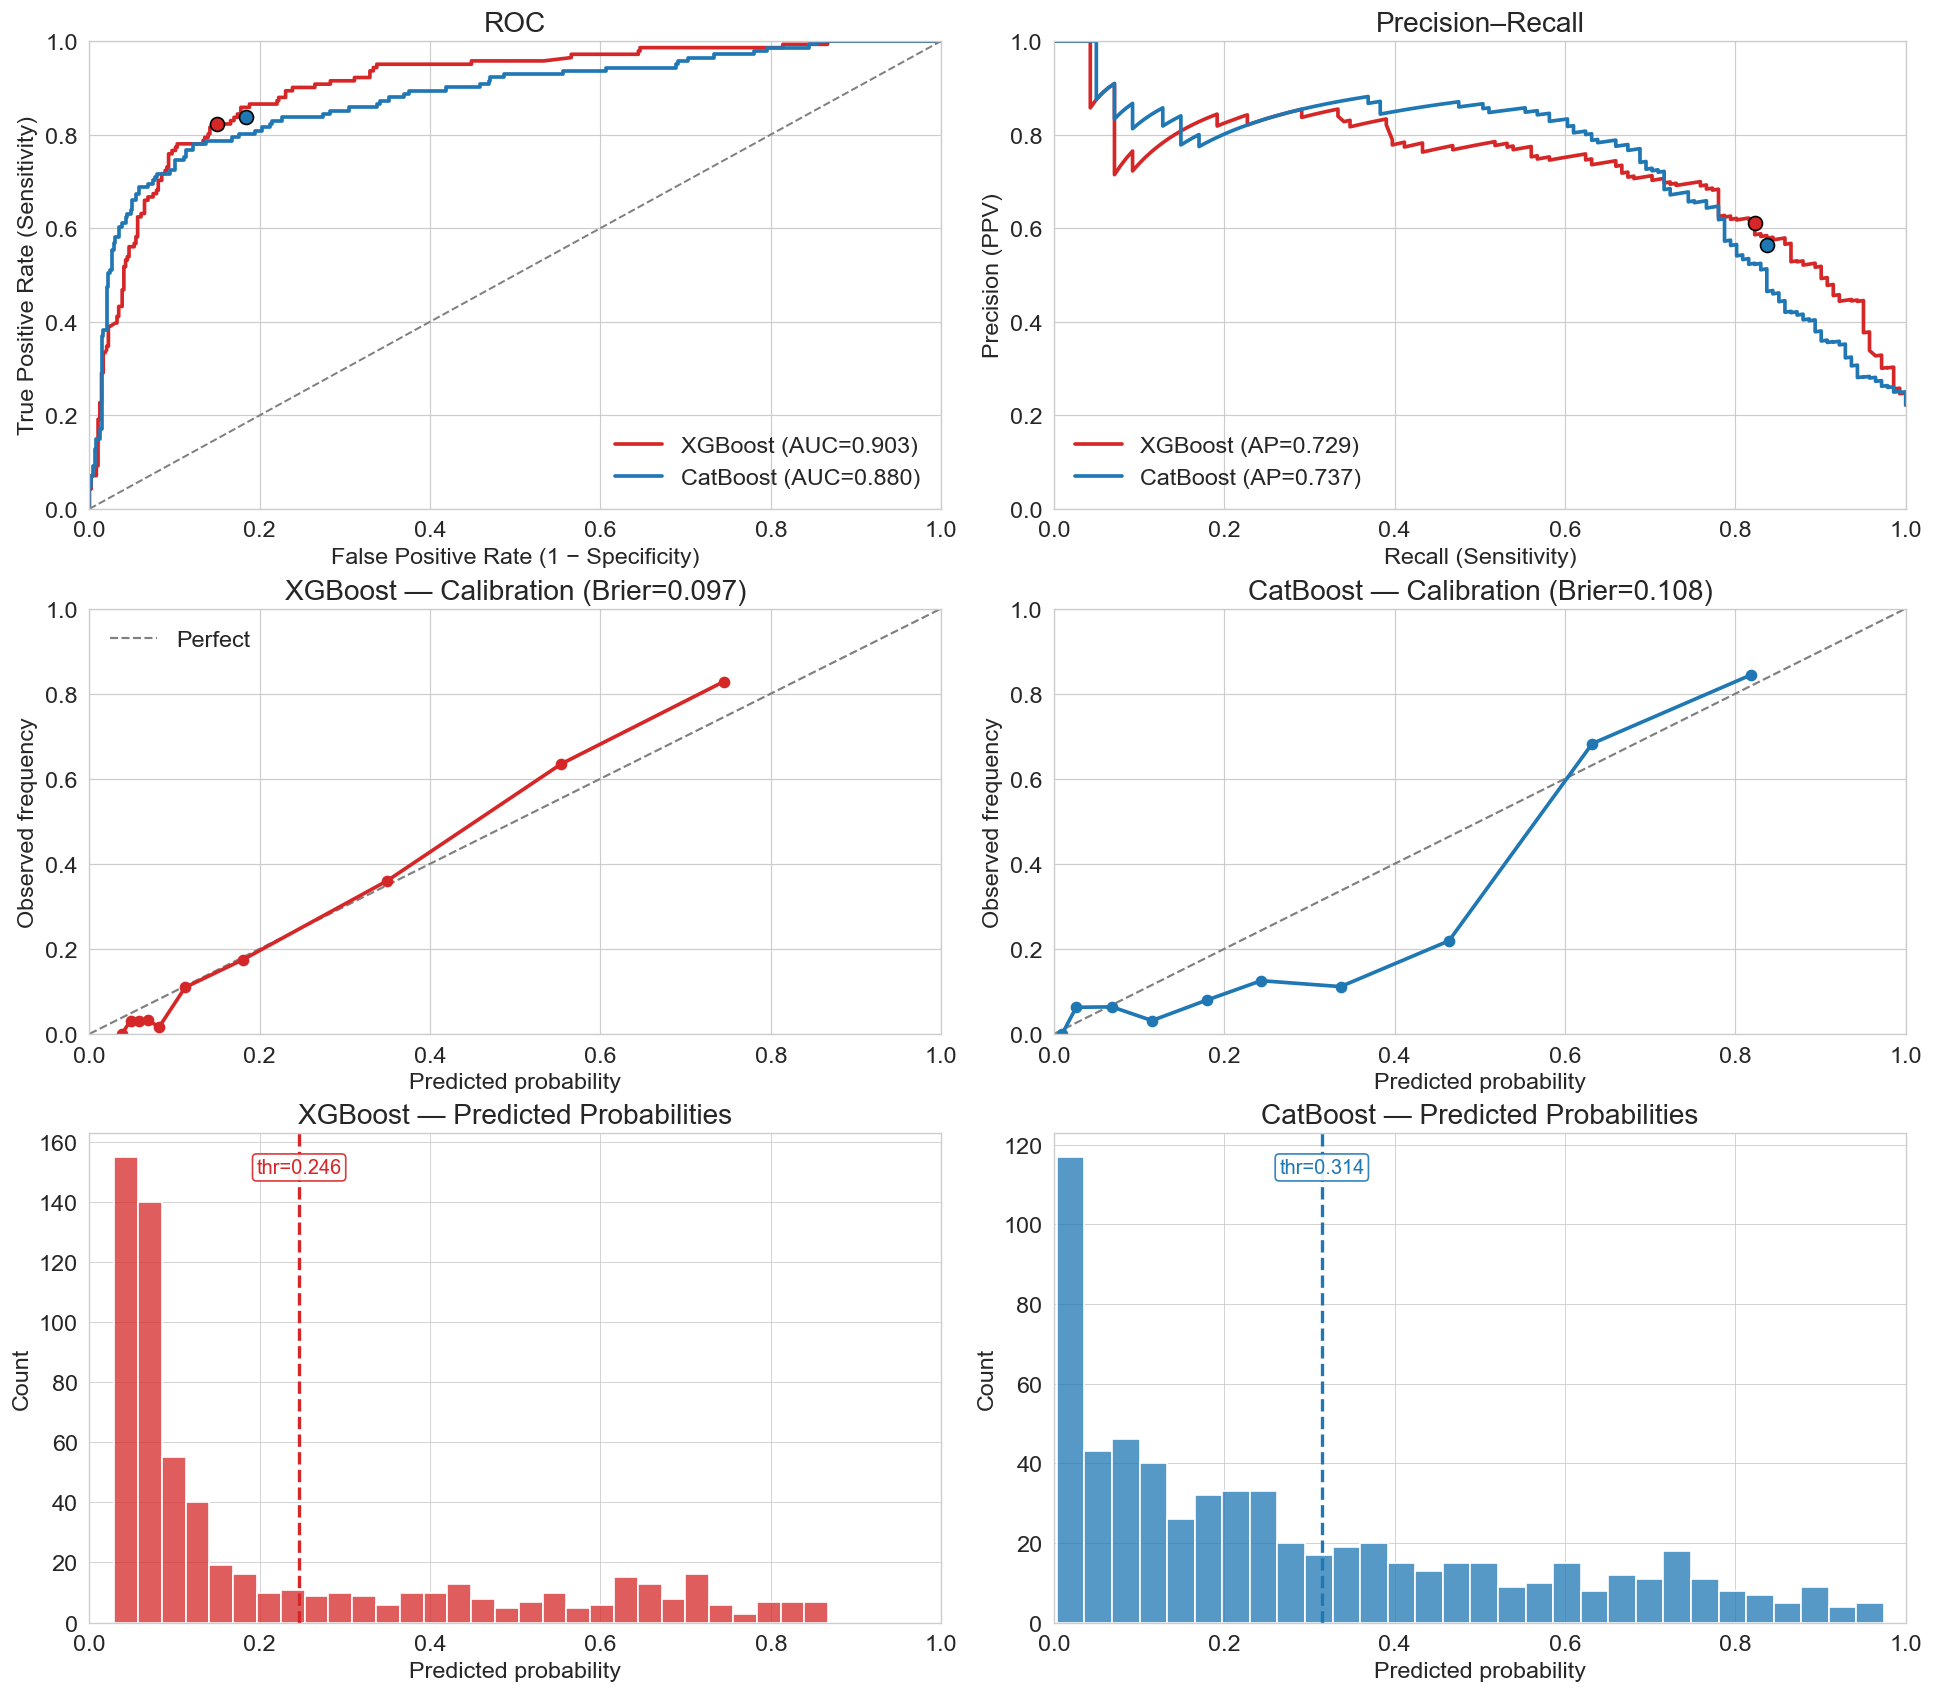

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/fig_ROC_PR_Calibration_Hists_XGB_left_CAT_right.png


In [11]:
# =============== FIGURE 2: ROC (AUC) | PR (AP) | Calibration | Prob Histograms ===============

mpl.rcParams.update({"font.size": 14})  # bump up all text globally

def calib_data(y_true, probs, n_bins=10):
    y_true = np.asarray(y_true).astype(int)
    probs  = as_proba(probs)
    n_bins = min(10, max(3, n_bins))
    prob_true, prob_pred = calibration_curve(y_true, probs, n_bins=n_bins, strategy="quantile")
    brier = brier_score_loss(y_true, probs)
    return prob_true, prob_pred, brier

def pooled_operating_point_pr(y_true, probs, fold_ids, fold_thresholds):
    thr_vec = np.array([fold_thresholds[int(f)] for f in fold_ids])
    preds = (as_proba(probs) >= thr_vec).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0,1]).ravel()
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    return precision, recall

def pooled_operating_point_roc(y_true, probs, fold_ids, fold_thresholds):
    thr_vec = np.array([fold_thresholds[int(f)] for f in fold_ids])
    preds = (as_proba(probs) >= thr_vec).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, preds, labels=[0,1]).ravel()
    tpr = tp / (tp + fn) if (tp + fn) else 0.0
    fpr = fp / (fp + tn) if (fp + tn) else 0.0
    return fpr, tpr

def ensure_oof_dict(name, d):
    need = {"y_true","probs","fold_ids","fold_thresholds"}
    assert isinstance(d, dict) and need.issubset(d.keys()), f"{name} missing keys {need}"
    d["y_true"]  = np.asarray(d["y_true"]).astype(int)
    d["probs"]   = as_proba(d["probs"])
    d["fold_ids"]= np.asarray(d["fold_ids"]).astype(int)
    return d

oof_cat = ensure_oof_dict("oof_cat", oof_cat)
oof_xgb = ensure_oof_dict("oof_xgb", oof_xgb)

# Put XGBoost first (left), CatBoost second (right)
model_order = ["XGBoost", "CatBoost"]
oofs   = {"XGBoost": oof_xgb, "CatBoost": oof_cat}
colors = {"XGBoost": "tab:red", "CatBoost": "tab:blue"}
mean_thresholds = {k: float(np.mean(list(v["fold_thresholds"].values()))) for k, v in oofs.items()}

# Precompute metrics
calib, ap_vals, auc_vals = {}, {}, {}
for name in model_order:
    y = oofs[name]["y_true"]; p = oofs[name]["probs"]
    calib[name] = calib_data(y, p, n_bins=10)
    ap_vals[name]  = average_precision_score(y, p)
    auc_vals[name] = roc_auc_score(y, p)

# ---------- Layout: 3 rows x 2 cols ----------
fig = plt.figure(figsize=(16, 14), constrained_layout=True)
gs = gridspec.GridSpec(3, 2, figure=fig, height_ratios=[1.1, 1.0, 1.15])

# ===== Top-left: ROC (AUC) =====
ax_roc = plt.subplot(gs[0, 0])
for name in model_order:
    y_true = oofs[name]["y_true"]; probs = oofs[name]["probs"]
    fpr, tpr, _ = roc_curve(y_true, probs)
    auc = auc_vals[name]
    ax_roc.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})", linewidth=2.2, color=colors[name])
    fpr_op, tpr_op = pooled_operating_point_roc(y_true, probs, oofs[name]["fold_ids"], oofs[name]["fold_thresholds"])
    ax_roc.scatter(fpr_op, tpr_op, color=colors[name], edgecolor="black", s=70, zorder=5)
ax_roc.plot([0,1],[0,1], linestyle="--", color="gray", linewidth=1.2)
ax_roc.set_xlabel("False Positive Rate (1 − Specificity)")
ax_roc.set_ylabel("True Positive Rate (Sensitivity)")
ax_roc.set_title("ROC")
ax_roc.set_xlim(0, 1); ax_roc.set_ylim(0, 1)
ax_roc.legend(frameon=False, loc="lower right"); ax_roc.grid(True, linewidth=0.7)

# ===== Top-right: PR (AP) =====
ax_pr = plt.subplot(gs[0, 1])
for name in model_order:
    y_true = oofs[name]["y_true"]; probs = oofs[name]["probs"]
    prec, rec, _ = precision_recall_curve(y_true, probs)
    ap = ap_vals[name]
    ax_pr.plot(rec, prec, label=f"{name} (AP={ap:.3f})", linewidth=2.2, color=colors[name])
    pr_op, rc_op = pooled_operating_point_pr(y_true, probs, oofs[name]["fold_ids"], oofs[name]["fold_thresholds"])
    ax_pr.scatter(rc_op, pr_op, color=colors[name], edgecolor="black", s=70, zorder=5)
ax_pr.set_xlabel("Recall (Sensitivity)"); ax_pr.set_ylabel("Precision (PPV)")
ax_pr.set_title("Precision–Recall")
ax_pr.set_xlim(0, 1); ax_pr.set_ylim(0, 1)
ax_pr.legend(frameon=False, loc="lower left"); ax_pr.grid(True, linewidth=0.7)

# ===== Middle row: Calibration curves =====
axes_cal = [plt.subplot(gs[1, 0]), plt.subplot(gs[1, 1])]
for ax, name in zip(axes_cal, model_order):
    pt, pp, brier = calib[name]
    ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1.3, label="Perfect")
    ax.plot(pp, pt, marker="o", markersize=6, linewidth=2.2, color=colors[name])
    ax.set_title(f"{name} — Calibration (Brier={brier:.3f})")
    ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed frequency")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(True, linewidth=0.7)
axes_cal[0].legend(frameon=False, loc="upper left")

# ===== Bottom row: Probability histograms =====
axes_hist = [plt.subplot(gs[2, 0]), plt.subplot(gs[2, 1])]
for ax, name in zip(axes_hist, model_order):
    p = oofs[name]["probs"]
    sns.histplot(p, bins=30, ax=ax, color=colors[name], kde=False)
    ax.set_title(f"{name} — Predicted Probabilities")
    ax.set_xlabel("Predicted probability"); ax.set_ylabel("Count")
    ax.set_xlim(0, 1); ax.grid(True, linewidth=0.5)
    thr = mean_thresholds[name]
    ax.axvline(thr, color=colors[name], linestyle="--", linewidth=2)
    ymin, ymax = ax.get_ylim()
    ax.text(thr, ymax - 0.05*(ymax - ymin), f"thr={thr:.3f}",
            color=colors[name], ha="center", va="top", fontsize=12,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=colors[name], alpha=0.9))

out_path = f"{IMG_DIR}/fig_ROC_PR_Calibration_Hists_XGB_left_CAT_right.png"
os.makedirs(os.path.dirname(out_path), exist_ok=True)
plt.savefig(out_path, dpi=300, bbox_inches="tight"); plt.show()
print("Saved:", out_path)


In [12]:
# =============== 8) TABLE 2: METRICS (POOLED THR) ===============
def pooled_metrics(y, p, fids, thr_map):
    y = np.asarray(y).astype(int); p = as_proba(p); fids = np.asarray(fids).astype(int)
    thr_vec = np.array([thr_map[int(fi)] for fi in fids])
    preds = (p >= thr_vec).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, preds, labels=[0,1]).ravel()
    sens = tp/(tp+fn) if (tp+fn) else 0.0
    spec = tn/(tn+fp) if (tn+fp) else 0.0
    ppv  = tp/(tp+fp) if (tp+fp) else 0.0
    npv  = tn/(tn+fn) if (tn+fn) else 0.0
    return sens, spec, ppv, npv

def bootstrap_ci_pooled(y, p, fids, thr_map, B=2000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(y); buckets = {k: [] for k in ["Sens","Spec","PPV","NPV","AUC","PRAUC","Brier"]}
    y = np.asarray(y).astype(int); p = as_proba(p); fids = np.asarray(fids).astype(int)
    for _ in range(B):
        idx = rng.integers(0, n, size=n)
        sens, spec, ppv, npv = pooled_metrics(y[idx], p[idx], fids[idx], thr_map)
        buckets["Sens"].append(sens); buckets["Spec"].append(spec)
        buckets["PPV"].append(ppv);   buckets["NPV"].append(npv)
        buckets["AUC"].append(roc_auc_score(y[idx], p[idx]))
        buckets["PRAUC"].append(average_precision_score(y[idx], p[idx]))
        buckets["Brier"].append(brier_score_loss(y[idx], p[idx]))
    out = {k: (np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in buckets.items()}
    return out

def row(mean, lo, hi, d=3): return f"{mean:.{d}f} ({lo:.{d}f}, {hi:.{d}f})"

models = {"CatBoost": oof_cat, "XGBoost": oof_xgb}
summary_fmt = {}
for name, pack in models.items():
    y, p, fids, thr_map = pack["y_true"], pack["probs"], pack["fold_ids"], pack["fold_thresholds"]
    sens, spec, ppv, npv = pooled_metrics(y, p, fids, thr_map)
    boot = bootstrap_ci_pooled(y, p, fids, thr_map, B=2000, seed=123)
    summary_fmt[name] = {
        "Sens":  row(sens, *boot["Sens"][1:3]),
        "Spec":  row(spec, *boot["Spec"][1:3]),
        "PPV":   row(ppv,  *boot["PPV"][1:3]),
        "NPV":   row(npv,  *boot["NPV"][1:3]),
        "AUC":   row(roc_auc_score(y,p), *boot["AUC"][1:3]),
        "PRAUC": row(average_precision_score(y,p), *boot["PRAUC"][1:3]),
        "Brier": row(brier_score_loss(y,p), *boot["Brier"][1:3]),
    }

summary_df = pd.DataFrame(summary_fmt)[["CatBoost","XGBoost"]]
print("\n=== OOF summary with 95% CIs — pooled, fold-wise thresholds ===")
print(summary_df)

out_csv = f"{CSV_DIR}/fig2_summary_metrics_XGB_vs_CAT_bootstrap_pooled.csv"
summary_df.to_csv(out_csv); print("Saved:", out_csv)



=== OOF summary with 95% CIs — pooled, fold-wise thresholds ===
                   CatBoost               XGBoost
Sens   0.837 (0.771, 0.895)  0.823 (0.755, 0.885)
Spec   0.816 (0.783, 0.847)  0.851 (0.820, 0.880)
PPV    0.565 (0.497, 0.630)  0.611 (0.542, 0.677)
NPV    0.946 (0.924, 0.966)  0.944 (0.921, 0.964)
AUC    0.880 (0.841, 0.914)  0.903 (0.873, 0.930)
PRAUC  0.737 (0.658, 0.810)  0.729 (0.646, 0.804)
Brier  0.108 (0.096, 0.122)  0.097 (0.084, 0.112)
Saved: /Users/hbattey/Desktop/Rodwell/Output/csv/fig2_summary_metrics_XGB_vs_CAT_bootstrap_pooled.csv


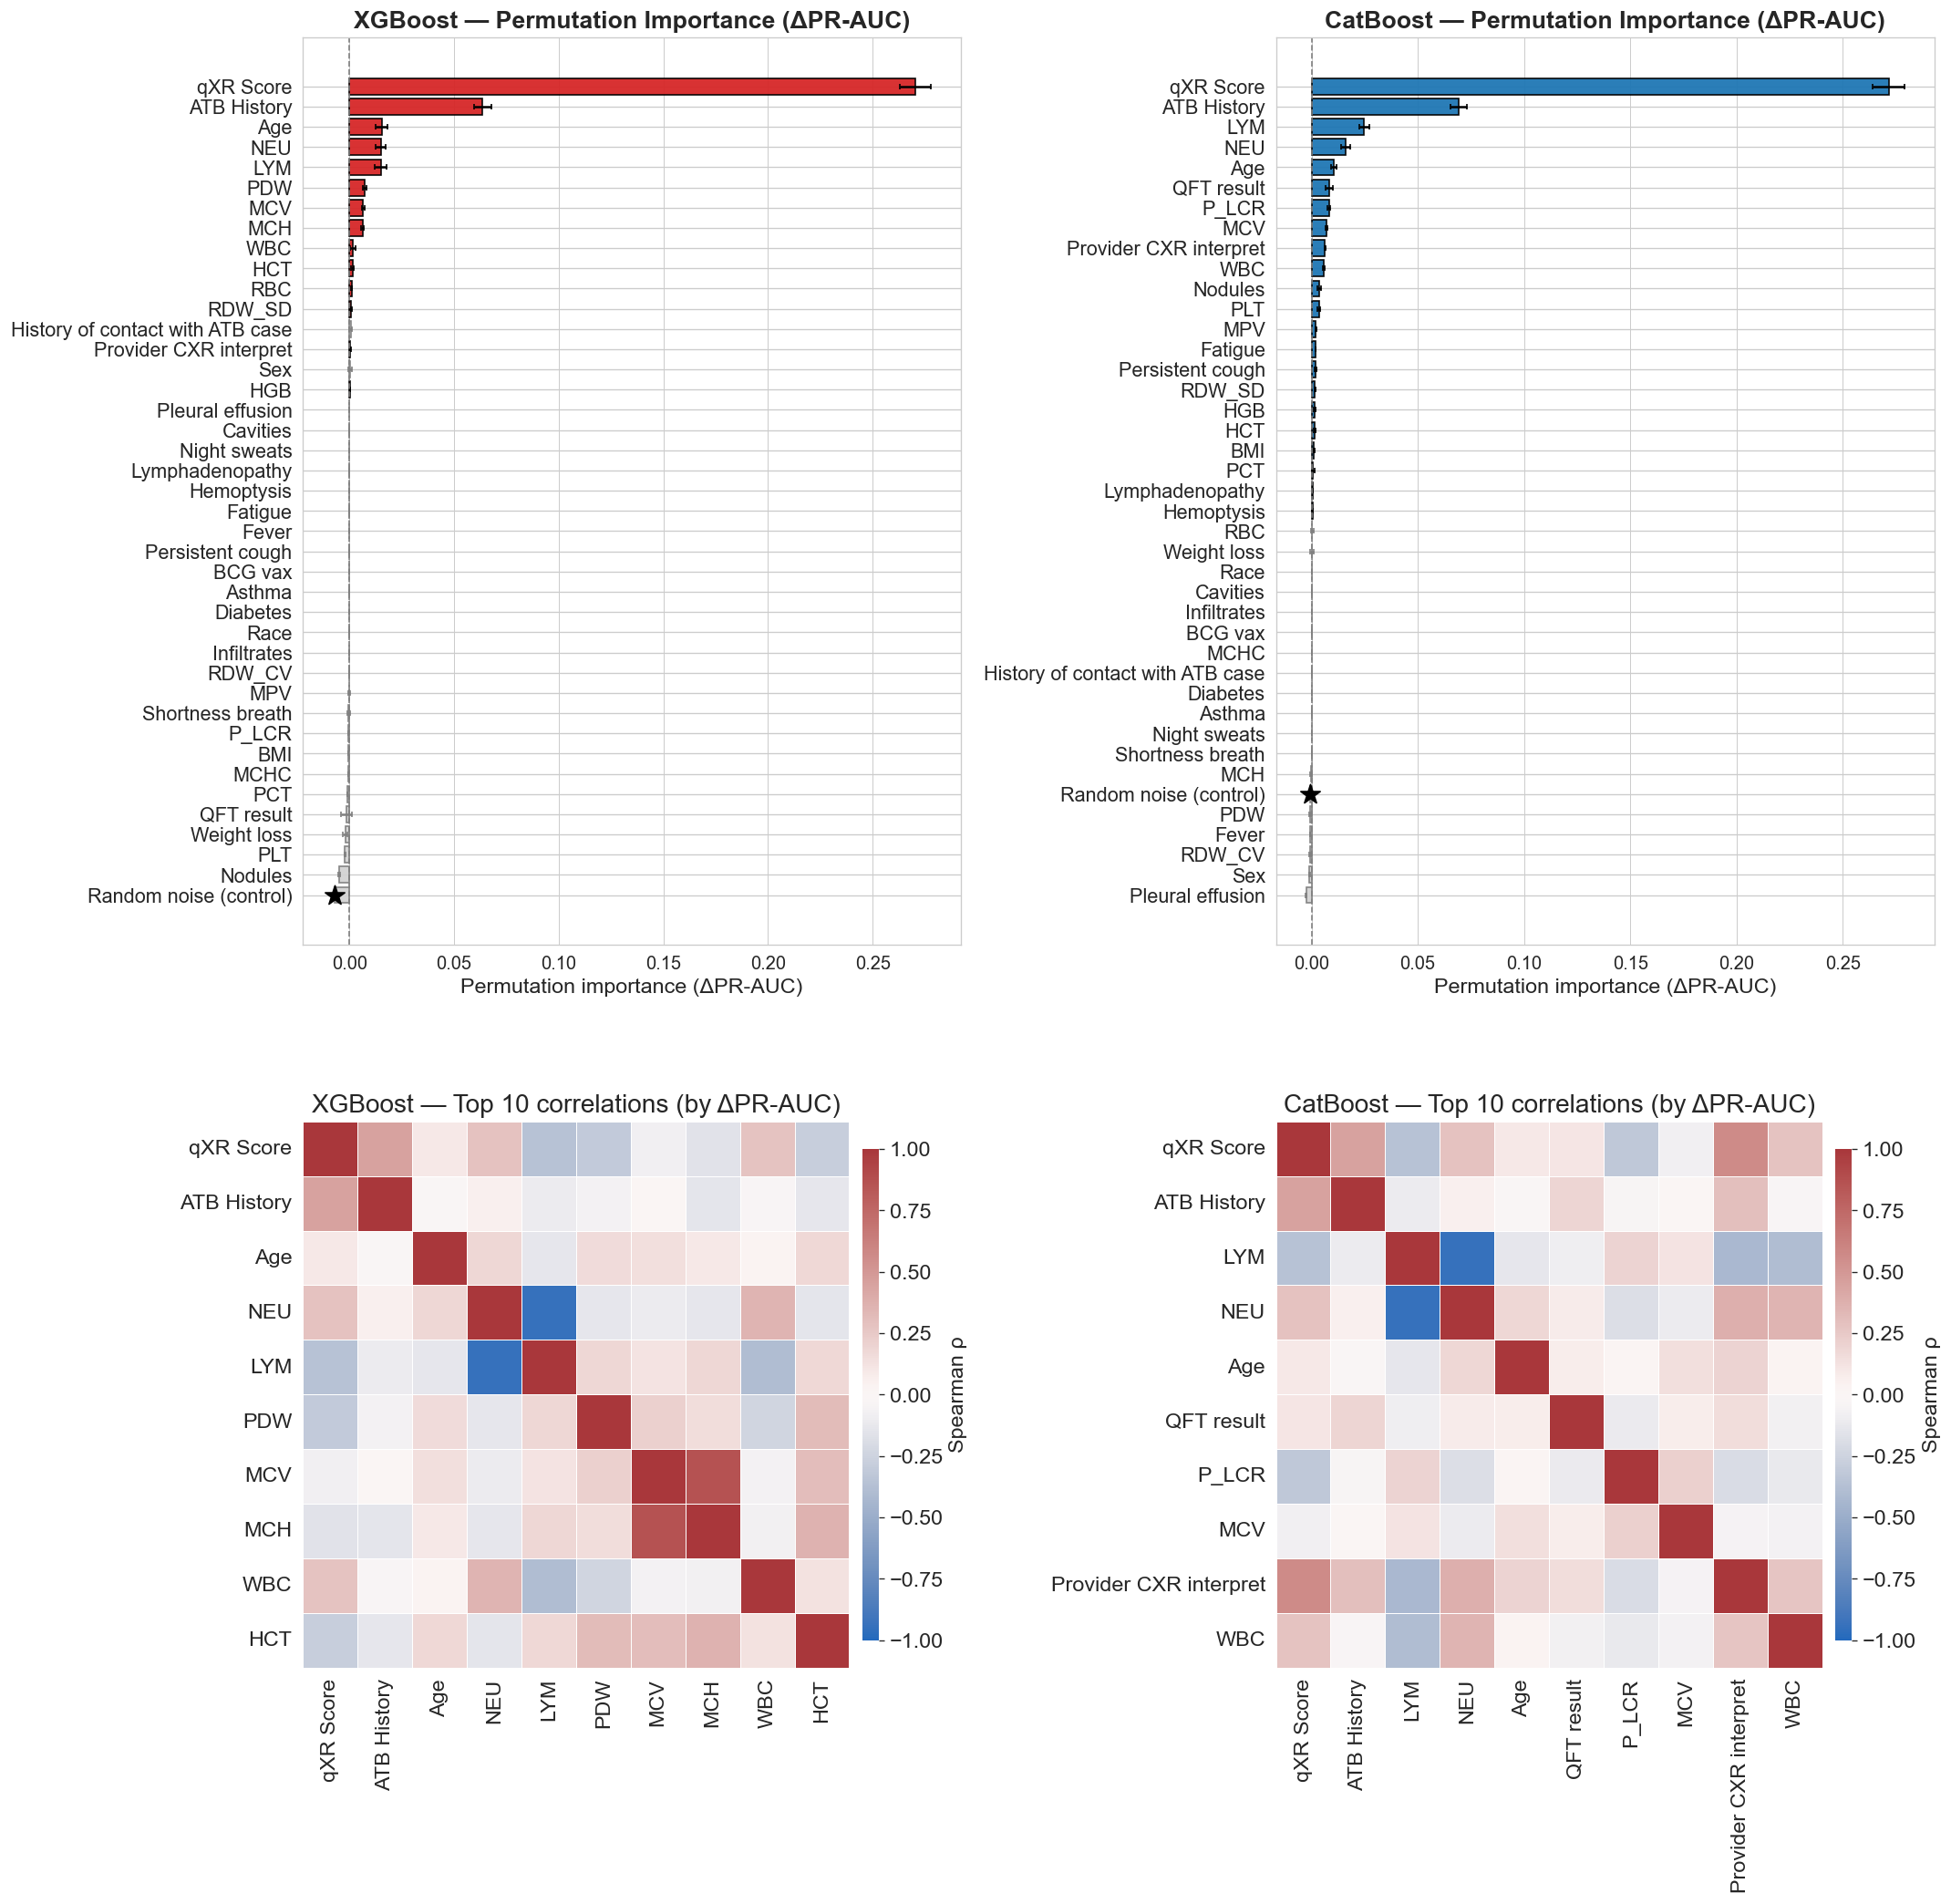

Saved figure (ΔPR-AUC): /Users/hbattey/Desktop/Rodwell/Output/Images/perm_importance_PR-AUCprimary_with_corr_XGB_left_CAT_right.png


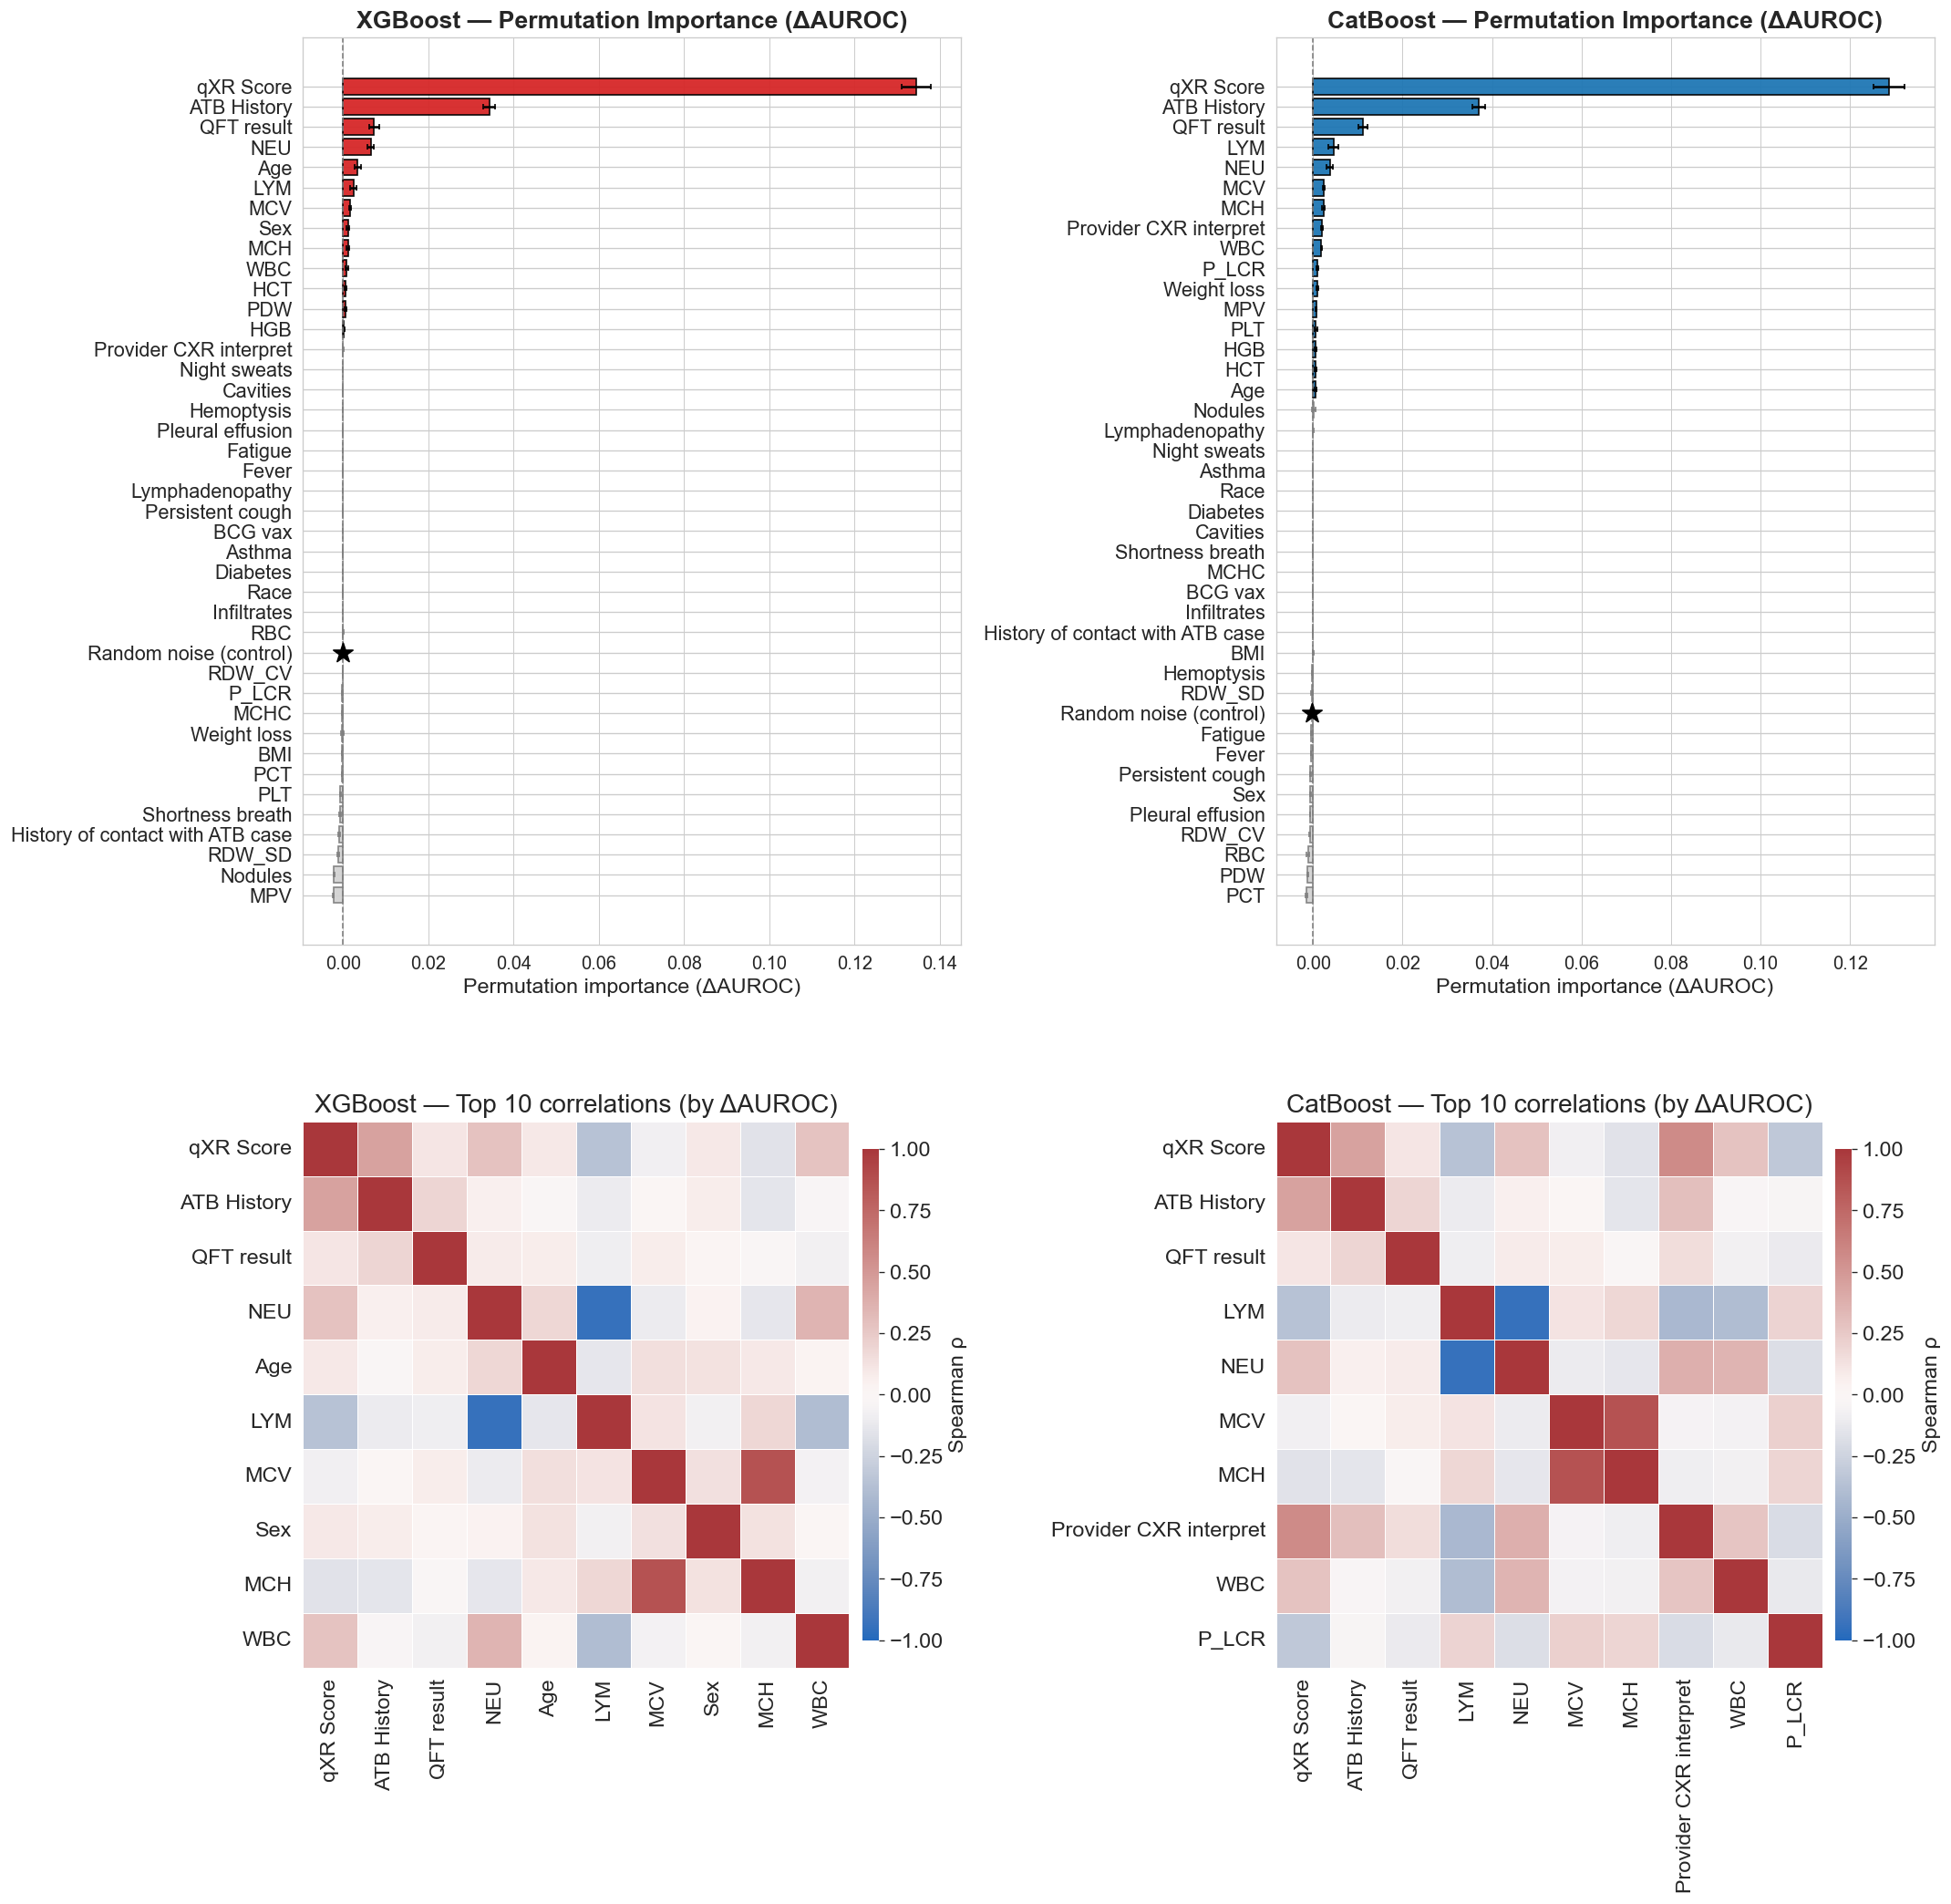

Saved figure (ΔAUROC): /Users/hbattey/Desktop/Rodwell/Output/Images/perm_importance_AUROC_sensitivity_with_corr_XGB_left_CAT_right.png
XGBoost (ΔPR-AUC): rand_noise ranked 41/41 by ΔPR_AUC_mean
CatBoost (ΔPR-AUC): rand_noise ranked 36/41 by ΔPR_AUC_mean
XGBoost (ΔAUROC): rand_noise ranked 29/41 by ΔAUROC_mean
CatBoost (ΔAUROC): rand_noise ranked 32/41 by ΔAUROC_mean


In [13]:
# =============== FIG 3: Permutation Importance (PR-AUC primary; AUROC sensitivity) + CORR ===============
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt, seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, ClassifierMixin
from xgboost import DMatrix

mpl.rcParams.update({"font.size": 14})

# -------- Build PI test frame (align + base) --------
X_test_base = align_categoricals(feature_test.copy())
y_test      = target_test.astype(int).copy()

# Ensure the single chosen random control exists in TEST matrices used for PI
if RAND_NAME not in X_test_base.columns:
    X_test_base[RAND_NAME] = np.random.default_rng(random_feature_seed).random(len(X_test_base))

# -------- Model-required columns & alignment --------
def required_cols_for_xgb(booster):
    req = getattr(booster, "feature_names_", None)
    if req is None:
        raise ValueError("XGB booster missing feature_names_; ensure set after training.")
    return list(req)

def required_cols_for_cat(model, fallback_cols):
    req = getattr(model, "feature_names_", None)
    return list(req) if (req is not None and len(req) > 0) else list(fallback_cols)

req_xgb = required_cols_for_xgb(est_xgb)
req_cat = required_cols_for_cat(est_cat, fallback_cols=X_train_pi.columns)

def align_to_model(df, required_cols, model_name):
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        # recreate any missing RAND_NAME (noise) or fill with 0/median for others
        df2 = df.copy()
        rng = np.random.default_rng(random_feature_seed)
        for c in missing:
            if c == RAND_NAME or str(c).lower().startswith(("rand","random")):
                df2[c] = rng.random(len(df2))
            else:
                vals = pd.to_numeric(X_train_pi[c], errors="coerce") if c in X_train_pi.columns else pd.Series([], dtype=float)
                fill = float(np.nanmedian(vals)) if len(vals) and vals.notna().any() else 0.0
                df2[c] = fill
        df = df2
        # re-check
        missing2 = [c for c in required_cols if c not in df.columns]
        if missing2:
            raise ValueError(f"[{model_name}] Missing columns even after fix: {missing2}")
    return df.reindex(columns=required_cols)

# Align to model-required columns
X_test_xgb = align_to_model(X_test_base, req_xgb, "XGBoost")
X_test_cat = align_to_model(X_test_base, req_cat, "CatBoost")

# Build PI matrices: include RAND_NAME even if not in required cols (starred in plots)
X_pi_xgb = X_test_xgb.copy()
X_pi_cat = X_test_cat.copy()
if RAND_NAME not in X_pi_xgb.columns:
    X_pi_xgb[RAND_NAME] = X_test_base[RAND_NAME].values
if RAND_NAME not in X_pi_cat.columns:
    X_pi_cat[RAND_NAME] = X_test_base[RAND_NAME].values

STAR_FEATURES = {RAND_NAME}

# -------- sklearn-compatible wrappers (must implement fit) --------
class XGBBoosterWrapper(BaseEstimator, ClassifierMixin):
    """Wrapper around a fitted xgboost.Booster to satisfy sklearn API."""
    def __init__(self, booster, feature_names):
        self.booster = booster
        self.feature_names = list(feature_names)
        self.classes_ = np.array([0, 1], dtype=int)
        self._estimator_type = "classifier"

    def fit(self, X, y=None):
        # no training; just mark as 'fitted' and record n_features_in_
        self.n_features_in_ = len(self.feature_names)
        return self

    def _prepare(self, X):
        X2 = align_categoricals(X).reindex(columns=self.feature_names)
        return DMatrix(X2, enable_categorical=True)

    def predict_proba(self, X):
        d = self._prepare(X)
        p = as_proba(self.booster.predict(d)).reshape(-1)
        return np.vstack([1 - p, p]).T

class CatBoostWrapper(BaseEstimator, ClassifierMixin):
    """Wrapper around a fitted CatBoost model to satisfy sklearn API."""
    def __init__(self, model, feature_names):
        self.model = model
        self.feature_names = list(feature_names)
        self.classes_ = np.array([0, 1], dtype=int)
        self._estimator_type = "classifier"

    def fit(self, X, y=None):
        # no training; just mark as 'fitted' and record n_features_in_
        self.n_features_in_ = len(self.feature_names)
        return self

    def predict_proba(self, X):
        X2 = align_categoricals(X).reindex(columns=self.feature_names)
        return self.model.predict_proba(X2)

# Instantiate + 'fit' wrappers (required by permutation_importance)
xgb_pi = XGBBoosterWrapper(est_xgb, req_xgb).fit(X_test_xgb, y_test)
cat_pi = CatBoostWrapper(est_cat, req_cat).fit(X_test_cat, y_test)

# -------- Stats utils --------
def _bh_fdr(p):
    p = np.asarray(p, float); n = p.size
    order = np.argsort(p); ranked = p[order]
    q = ranked * n / (np.arange(n) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty_like(q); out[order] = q
    return np.clip(out, 0, 1)

try:
    from statsmodels.stats.multitest import multipletests
except Exception:
    multipletests = None

def _summarize_importance(imp_obj):
    deltas = imp_obj.importances
    means  = deltas.mean(axis=1); sds = deltas.std(axis=1, ddof=1)
    n = deltas.shape[1]; se = sds / np.sqrt(max(n, 1))
    from scipy import stats as _stats
    tstat = np.divide(means, se, out=np.zeros_like(means), where=se > 0)
    pvals = _stats.t.sf(tstat, df=max(n - 1, 1))
    qvals = multipletests(pvals, method="fdr_bh")[1] if multipletests else _bh_fdr(pvals)
    ci_lo = means - 1.96 * se; ci_hi = means + 1.96 * se
    return means, sds, ci_lo, ci_hi, pvals, qvals

# Repeats for PI (you referenced N_PI_REPEATS earlier)
N_PI_REPEATS = 200
Z = 1.96  # for error bars in plots

# -------- Permutation importance: PR-AUC primary, AUROC sensitivity --------
def run_perm_PR_AUROC(est, X, y, n_repeats=N_PI_REPEATS, random_state=RANDOM_STATE):
    imp_pr  = permutation_importance(est, X, y, n_repeats=n_repeats, scoring="average_precision",
                                     random_state=random_state, n_jobs=-1)
    pr_m, pr_sd, pr_lo, pr_hi, p_pr, q_pr = _summarize_importance(imp_pr)

    imp_auc = permutation_importance(est, X, y, n_repeats=n_repeats, scoring="roc_auc",
                                     random_state=random_state, n_jobs=-1)
    auc_m, auc_sd, auc_lo, auc_hi, p_auc, q_auc = _summarize_importance(imp_auc)

    out = pd.DataFrame({
        "Feature": X.columns,
        "ΔPR_AUC_mean": pr_m, "ΔPR_AUC_sd": pr_sd, "ΔPR_AUC_lo": pr_lo, "ΔPR_AUC_hi": pr_hi,
        "pval_PR_AUC":  p_pr, "qval_PR_AUC": q_pr, "sig_PR_AUC_q<0.05": (q_pr < 0.05),

        "ΔAUROC_mean":  auc_m, "ΔAUROC_sd": auc_sd, "ΔAUROC_lo": auc_lo, "ΔAUROC_hi": auc_hi,
        "pval_AUROC":   p_auc, "qval_AUROC":  q_auc, "sig_AUROC_q<0.05": (q_auc < 0.05),
    })
    out["Display"] = out["Feature"].map(lambda c: rename_dict.get(c, c))
    return out

pi_xgb = run_perm_PR_AUROC(xgb_pi, X_pi_xgb, y_test)
pi_cat = run_perm_PR_AUROC(cat_pi,  X_pi_cat, y_test)

# -------- Save CSVs --------
os.makedirs(CSV_DIR, exist_ok=True)
pi_xgb.sort_values("ΔPR_AUC_mean", ascending=False).to_csv(f"{CSV_DIR}/perm_importance_XGB_PR-AUC_primary.csv", index=False)
pi_cat.sort_values("ΔPR_AUC_mean", ascending=False).to_csv(f"{CSV_DIR}/perm_importance_CAT_PR-AUC_primary.csv", index=False)
pi_xgb.sort_values("ΔAUROC_mean",   ascending=False).to_csv(f"{CSV_DIR}/perm_importance_XGB_AUROC_sensitivity.csv", index=False)
pi_cat.sort_values("ΔAUROC_mean",   ascending=False).to_csv(f"{CSV_DIR}/perm_importance_CAT_AUROC_sensitivity.csv", index=False)

# -------- Plotting helpers (bars + correlations) --------
def to_numeric_matrix(df, cols):
    X = df[cols].copy(); out = pd.DataFrame(index=X.index)
    for c in cols:
        s = X[c]
        if isinstance(s.dtype, pd.CategoricalDtype) or s.dtype == object:
            out[c] = s.astype("category").cat.codes
        else:
            out[c] = pd.to_numeric(s, errors="coerce").fillna(0)
    return out

def corr_panel(ax, df_raw, top_feats, title):
    if len(top_feats) == 0:
        ax.set_visible(False); return
    Xnum = to_numeric_matrix(df_raw, top_feats)
    corr = Xnum.corr(method="spearman")
    pretty_cols = [rename_dict.get(c, c) for c in top_feats]
    corr.index = pretty_cols; corr.columns = pretty_cols
    sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap="vlag", square=True,
                linewidths=0.3, linecolor="white",
                cbar_kws={"label":"Spearman ρ","shrink":0.65,"aspect":30,"pad":0.02},
                ax=ax)
    ax.set_title(title); ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

def bar_panel(ax, df_imp, order, labels, title,
              metric_col="ΔPR_AUC_mean", sd_col="ΔPR_AUC_sd", sig_col="sig_PR_AUC_q<0.05",
              color_sig="tab:red", color_ns="lightgray",
              n_repeats=N_PI_REPEATS, z=Z, xlabel="Permutation importance (ΔPR-AUC)"):
    sub = df_imp.set_index("Feature").loc[order].iloc[::-1].copy()
    y_pos = np.arange(len(sub))
    vals  = sub[metric_col].to_numpy()
    errs  = (z * sub[sd_col].to_numpy() / np.sqrt(n_repeats))
    sig   = sub[sig_col].to_numpy().astype(bool)

    if (~sig).any():
        ax.barh(y_pos[~sig], vals[~sig], xerr=errs[~sig],
                color=color_ns, edgecolor="gray", ecolor="gray", capsize=2, alpha=0.95)
    if sig.any():
        ax.barh(y_pos[sig], vals[sig], xerr=errs[sig],
                color=color_sig, edgecolor="black", ecolor="black", capsize=2, alpha=0.95)

    # star the random control if present
    if RAND_NAME in sub.index:
        idx = sub.index.get_loc(RAND_NAME)
        ax.scatter(vals[idx], y_pos[idx], marker="*", s=180, color="black", zorder=5)

    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(title, fontsize=16, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=14)
    ax.set_yticks(y_pos); ax.set_yticklabels(list(reversed(labels)), fontsize=13)
    ax.tick_params(axis="x", labelsize=12); ax.grid(True, axis="x", linewidth=0.6)

# -------- FIGURE A: ΔPR-AUC (primary) + correlations --------
order_xgb_pr = pi_xgb.sort_values("ΔPR_AUC_mean", ascending=False)["Feature"].tolist()
order_cat_pr = pi_cat.sort_values("ΔPR_AUC_mean", ascending=False)["Feature"].tolist()
labels_xgb   = [rename_dict.get(f, f) for f in order_xgb_pr]
labels_cat   = [rename_dict.get(f, f) for f in order_cat_pr]
TOP_K = min(10, len(order_xgb_pr), len(order_cat_pr))

fig_pr, axes_pr = plt.subplots(2, 2, figsize=(18, max(8, 0.30*max(len(order_xgb_pr), len(order_cat_pr)) + 6)),
                               gridspec_kw={"height_ratios": [1.2, 1.0]})

bar_panel(axes_pr[0, 0], pi_xgb, order_xgb_pr, labels_xgb,
          "XGBoost — Permutation Importance (ΔPR-AUC)",
          color_sig="tab:red", xlabel="Permutation importance (ΔPR-AUC)")
bar_panel(axes_pr[0, 1], pi_cat, order_cat_pr, labels_cat,
          "CatBoost — Permutation Importance (ΔPR-AUC)",
          color_sig="tab:blue", xlabel="Permutation importance (ΔPR-AUC)")

top_xgb_pr_corr = [f for f in order_xgb_pr if f != RAND_NAME][:TOP_K]
top_cat_pr_corr = [f for f in order_cat_pr if f != RAND_NAME][:TOP_K]
corr_panel(axes_pr[1, 0], X_test_base, top_xgb_pr_corr,
           f"XGBoost — Top {len(top_xgb_pr_corr)} correlations (by ΔPR-AUC)")
corr_panel(axes_pr[1, 1], X_test_base, top_cat_pr_corr,
           f"CatBoost — Top {len(top_cat_pr_corr)} correlations (by ΔPR-AUC)")

os.makedirs(IMG_DIR, exist_ok=True)
fig_path_pr = f"{IMG_DIR}/perm_importance_PR-AUCprimary_with_corr_XGB_left_CAT_right.png"
plt.tight_layout(); plt.savefig(fig_path_pr, dpi=260, bbox_inches="tight"); plt.show()
print("Saved figure (ΔPR-AUC):", fig_path_pr)

# -------- FIGURE B: ΔAUROC (sensitivity) + correlations --------
order_xgb_auc = pi_xgb.sort_values("ΔAUROC_mean", ascending=False)["Feature"].tolist()
order_cat_auc = pi_cat.sort_values("ΔAUROC_mean", ascending=False)["Feature"].tolist()
labels_xgb_auc = [rename_dict.get(f, f) for f in order_xgb_auc]
labels_cat_auc = [rename_dict.get(f, f) for f in order_cat_auc]
TOP_K_AUC = min(10, len(order_xgb_auc), len(order_cat_auc))

fig_auc, axes_auc = plt.subplots(2, 2, figsize=(18, max(8, 0.30*max(len(order_xgb_auc), len(order_cat_auc)) + 6)),
                                 gridspec_kw={"height_ratios": [1.2, 1.0]})

bar_panel(axes_auc[0, 0], pi_xgb, order_xgb_auc, labels_xgb_auc,
          "XGBoost — Permutation Importance (ΔAUROC)",
          metric_col="ΔAUROC_mean", sd_col="ΔAUROC_sd", sig_col="sig_AUROC_q<0.05",
          color_sig="tab:red", xlabel="Permutation importance (ΔAUROC)")
bar_panel(axes_auc[0, 1], pi_cat, order_cat_auc, labels_cat_auc,
          "CatBoost — Permutation Importance (ΔAUROC)",
          metric_col="ΔAUROC_mean", sd_col="ΔAUROC_sd", sig_col="sig_AUROC_q<0.05",
          color_sig="tab:blue", xlabel="Permutation importance (ΔAUROC)")

top_xgb_auc_corr = [f for f in order_xgb_auc if f != RAND_NAME][:TOP_K_AUC]
top_cat_auc_corr = [f for f in order_cat_auc if f != RAND_NAME][:TOP_K_AUC]
corr_panel(axes_auc[1, 0], X_test_base, top_xgb_auc_corr,
           f"XGBoost — Top {len(top_xgb_auc_corr)} correlations (by ΔAUROC)")
corr_panel(axes_auc[1, 1], X_test_base, top_cat_auc_corr,
           f"CatBoost — Top {len(top_cat_auc_corr)} correlations (by ΔAUROC)")

fig_path_auc = f"{IMG_DIR}/perm_importance_AUROC_sensitivity_with_corr_XGB_left_CAT_right.png"
plt.tight_layout(); plt.savefig(fig_path_auc, dpi=260, bbox_inches="tight"); plt.show()
print("Saved figure (ΔAUROC):", fig_path_auc)

def print_random_rank(pi_df, model_name, metric_col, random_name=RAND_NAME):
    if metric_col not in pi_df.columns:
        print(f"{model_name}: metric '{metric_col}' not found."); return
    df = pi_df[["Feature", metric_col]].sort_values(metric_col, ascending=False).reset_index(drop=True)
    total = len(df)
    idxs = np.flatnonzero(df["Feature"].to_numpy() == random_name)
    if idxs.size == 0:
        print(f"{model_name}: '{random_name}' not in feature list."); return
    rank = int(idxs[0]) + 1
    print(f"{model_name}: {random_name} ranked {rank}/{total} by {metric_col}")

print_random_rank(pi_xgb, "XGBoost (ΔPR-AUC)", "ΔPR_AUC_mean")
print_random_rank(pi_cat, "CatBoost (ΔPR-AUC)", "ΔPR_AUC_mean")
print_random_rank(pi_xgb, "XGBoost (ΔAUROC)",  "ΔAUROC_mean")
print_random_rank(pi_cat, "CatBoost (ΔAUROC)", "ΔAUROC_mean")


In [12]:
# =============== 10) FAIRNESS TABLE (SEARCH SPACES & BESTS) ===============

XGB_HIDE_KEYS = {"max_cat_to_onehot", "max_cat_threshold", "enable_categorical"}  # impl details, not tuned

# Best params snapshots prepared earlier
xgb_disp = {k: v for k, v in xgb_best_params.items() if k not in XGB_HIDE_KEYS}
cat_disp = dict(cat_best_params)

SEED_VAL = int(split_seed)

def rng(a, b): return f"[{a}, {b}]"
def fmt(v):
    if v is None: return "—"
    if isinstance(v, float): return f"{v:.6g}"
    return str(v)

rows = []
def add_row(concept, purpose, xgb_space, cat_space, xgb_best_val, cat_best_val):
    rows.append({
        "Concept / Parameter": concept,
        "Purpose / Notes": purpose,
        "XGBoost — Search space / Fixed": xgb_space,
        "XGBoost — Best": xgb_best_val,
        "CatBoost — Search space / Fixed": cat_space,
        "CatBoost — Best": cat_best_val,
    })

add_row("Learning rate","Step size shrinkage.",
        rng(0.05,0.10), rng(0.05,0.10),
        fmt(xgb_disp.get("learning_rate")), fmt(cat_disp.get("learning_rate")))

add_row("Tree depth (capacity)","Model capacity.",
        rng(3,7)+" (max_depth)", rng(3,7)+" (depth)",
        fmt(xgb_disp.get("max_depth")), fmt(cat_disp.get("depth")))

add_row("L2 regularization","Overfit control.",
        rng(1.0,10.0)+" (lambda)", rng(1.0,10.0)+" (l2_leaf_reg)",
        fmt(xgb_disp.get("lambda")), fmt(cat_disp.get("l2_leaf_reg")))

add_row("L1 regularization","Sparsity (XGB only).",
        rng(0.0,10.0)+" (alpha)", "—",
        fmt(xgb_disp.get("alpha")), "—")

add_row("Column sampling","Per-tree feature sampling.",
        rng(0.70,0.95)+" (colsample_bytree)", rng(0.70,0.95)+" (rsm)",
        fmt(xgb_disp.get("colsample_bytree")), fmt(cat_disp.get("rsm")))

add_row("Row sampling (Bernoulli)","Stochastic per-row.",
        rng(0.70,0.95)+" (subsample)", "If Bernoulli → "+rng(0.70,0.95),
        fmt(xgb_disp.get("subsample")),
        fmt(cat_disp.get("subsample")) if cat_disp.get("bootstrap_type")=="Bernoulli" else "—")

add_row("Bagging temperature (Bayesian)","Bayesian bootstrap randomness.",
        "—", "If Bayesian → "+rng(0.0,1.0),
        "—",
        fmt(cat_disp.get("bagging_temperature")) if cat_disp.get("bootstrap_type")=="Bayesian" else "—")

add_row("Bootstrap family","CatBoost bagging scheme.",
        "—", "{Bayesian, Bernoulli}",
        "—", fmt(cat_disp.get("bootstrap_type")))

add_row("Min child / leaf weight","Leaf stability.",
        rng(1,10)+" (min_child_weight)", rng(1,32)+" (min_data_in_leaf)",
        fmt(xgb_disp.get("min_child_weight")), fmt(cat_disp.get("min_data_in_leaf")))

# **FIXED**: was the literal string "rng(0,5) (gamma)"
add_row("Min split loss (γ)","Penalty to create a new split.",
        rng(0.0,5.0)+" (gamma)", "—",
        fmt(xgb_disp.get("gamma")), "—")

# ---- Class imbalance summary (from studies) ----
def _best_trial_params(study):
    try:
        return dict(study.best_trial.params)
    except Exception:
        return {}

xgb_trial = _best_trial_params(study_xgb)
cat_trial = _best_trial_params(study_cat)

xgb_use_w  = xgb_trial.get("use_weights", None)
xgb_w_mult = xgb_trial.get("w_mult", None)
xgb_spw    = xgb_best_params.get("scale_pos_weight", None)

cat_use_w  = cat_trial.get("use_weights", None)
cat_w_mult = cat_trial.get("w_mult", None)

xgb_search = f"use_weights∈{{T,F}}; w_mult∈[0.5,2.0]; scale_pos_weight = 1 if off else w_mult×SCALE_POS({SCALE_POS:.3g})"
cat_search = "use_weights∈{T,F}; w_mult∈[0.5,2.0]"

if xgb_use_w is True:
    xgb_best_str = f"use_weights=True; w_mult={fmt(xgb_w_mult)}; scale_pos_weight={fmt(xgb_spw)}"
elif xgb_use_w is False:
    xgb_best_str = f"use_weights=False; scale_pos_weight={fmt(xgb_spw)}"
else:
    xgb_best_str = f"scale_pos_weight={fmt(xgb_spw)}"

if "class_weights" in cat_disp:
    cat_best_str = f"use_weights={cat_use_w if cat_use_w is not None else True}; w_mult={fmt(cat_w_mult)}; class_weights={cat_disp['class_weights']}"
elif "auto_class_weights" in cat_disp:
    cat_best_str = f"auto_class_weights={cat_disp['auto_class_weights']}"
else:
    cat_best_str = "use_weights=False (not used)" if cat_use_w is False else "use_weights=True; class_weights set"

add_row("Class imbalance weighting","Optional weighting around class ratio.",
        xgb_search, cat_search, xgb_best_str, cat_best_str)

add_row("Objective / Loss","Binary loss.",
        "binary:logistic", "Logloss",
        "binary:logistic", "Logloss")

add_row("Eval metric","Guides early stopping.",
        "auc", "AUC",
        "auc", "AUC")

add_row("Training length control","Upper cap & early stopping patience.",
        "≤2000; patience=80", "≤2000; patience=80",
        f"best_rounds={xgb_best_rounds}", f"best_rounds={cat_best_rounds}")

add_row("Categorical handling","Native categorical support.",
        "enable_categorical=True (fixed)", "Native CatBoost (fixed)",
        "Enabled", "Enabled")

add_row("Tree method / Seed","Determinism / backend.",
        f"tree_method=hist; seed={SEED_VAL}", f"random_seed={SEED_VAL}",
        f"hist; seed={SEED_VAL}", f"{SEED_VAL}")

fair_df = pd.DataFrame(rows)
fair_df.to_csv(f"{CSV_DIR}/tuning_fairness_table.csv", index=False)
try:
    import openpyxl
    fair_df.to_excel(f"{CSV_DIR}/tuning_fairness_table.xlsx",
                     sheet_name="fairness_table", index=False)
except Exception:
    print("Excel save skipped; install openpyxl if needed.")

print("Saved fairness table to CSV (and XLSX if available).")


Saved fairness table to CSV (and XLSX if available).



=== Nested CV at target specificity 0.75 ===

=== Nested CV at target specificity 0.80 ===

=== Nested CV at target specificity 0.85 ===

=== Nested CV at target specificity 0.90 ===
   Specificity_Target     Model  Sensitivity  Sensitivity_CI  \
0                0.75  CatBoost     0.836879  (0.777, 0.892)   
1                0.75   XGBoost     0.836879  (0.771, 0.894)   
2                0.80  CatBoost     0.836879  (0.773, 0.894)   
3                0.80   XGBoost     0.822695  (0.757, 0.882)   
4                0.85  CatBoost     0.815603  (0.748, 0.876)   
5                0.85   XGBoost     0.787234  (0.719, 0.851)   
6                0.90  CatBoost     0.751773  (0.680, 0.817)   
7                0.90   XGBoost     0.687943  (0.611, 0.762)   

   Achieved_Specificity       PPV       NPV     AUROC     PRAUC     Brier  
0              0.826263  0.578431  0.946759  0.903747  0.737298  0.094301  
1              0.822222  0.572816  0.946512  0.898768  0.752714  0.096168  
2          

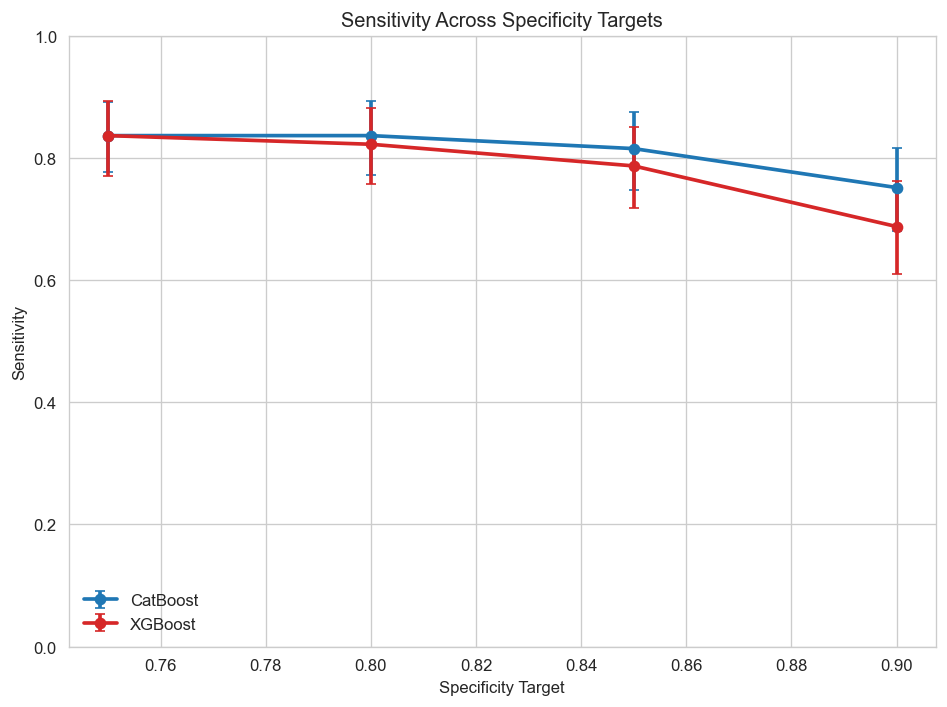

Saved figure: /Users/hbattey/Desktop/Rodwell/Output/Images/sensitivity_vs_spec_targets_cat_xgb.png


In [13]:
# =============== 11) SUPP FIG 3: SENS VS SPEC TARGETS ===============
SPEC_TARGETS = [0.75, 0.80, 0.85, 0.90]
records = []

for spec_t in SPEC_TARGETS:
    print(f"\n=== Nested CV at target specificity {spec_t:.2f} ===")
    oof_cat_s = build_oof_catboost_at_spec(X_for_oof, y_for_oof, CATS, spec_t, n_outer=N_OUTER, seed=RANDOM_STATE)
    oof_xgb_s = build_oof_xgb_at_spec(X_for_oof, y_for_oof, CATS, spec_t, n_outer=N_OUTER, seed=RANDOM_STATE)

    for name, pack in [("CatBoost", oof_cat_s), ("XGBoost", oof_xgb_s)]:
        y_true, probs, fids, thr_map = pack["y_true"], pack["probs"], pack["fold_ids"], pack["fold_thresholds"]
        # pooled metrics
        tn, fp, fn, tp = confusion_matrix(y_true, (probs >= np.array([thr_map[int(f)] for f in fids])).astype(int), labels=[0,1]).ravel()
        sens = tp/(tp+fn) if (tp+fn) else 0.0
        spec = (1 - fp/(fp+tn)) if (fp+tn) else 0.0
        ppv  = tp/(tp+fp) if (tp+fp) else 0.0
        npv  = tn/(tn+fn) if (tn+fn) else 0.0

        # simple bootstrap CI for sensitivity
        rng = np.random.default_rng(RANDOM_STATE)
        N = len(y_true)
        boots = []
        for _ in range(2000):
            idx = rng.integers(0, N, size=N)
            yb, pb, fb = y_true[idx], probs[idx], fids[idx]
            thrb = np.array([thr_map[int(f)] for f in fb])
            tn_b, fp_b, fn_b, tp_b = confusion_matrix(yb, (pb>=thrb).astype(int), labels=[0,1]).ravel()
            boots.append(tp_b/(tp_b+fn_b) if (tp_b+fn_b) else 0.0)
        lo, hi = np.percentile(boots, [2.5, 97.5])

        records.append(dict(
            Specificity_Target=spec_t, Model=name, Sensitivity=sens,
            Sensitivity_CI=f"({lo:.3f}, {hi:.3f})",
            Achieved_Specificity=spec, PPV=ppv, NPV=npv,
            AUROC=roc_auc_score(y_true, probs),
            PRAUC=average_precision_score(y_true, probs),
            Brier=brier_score_loss(y_true, probs)
        ))

results_df = pd.DataFrame(records).sort_values(["Specificity_Target","Model"]).reset_index(drop=True)
print(results_df[["Specificity_Target","Model","Sensitivity","Sensitivity_CI","Achieved_Specificity","PPV","NPV","AUROC","PRAUC","Brier"]])

out_csv = f"{CSV_DIR}/sensitivity_vs_spec_targets_cat_xgb.csv"
results_df.to_csv(out_csv, index=False); print("Saved table:", out_csv)

# Plot
plt.figure(figsize=(8,6))
for name, color in [("CatBoost","tab:blue"), ("XGBoost","tab:red")]:
    sub = results_df[results_df["Model"] == name].sort_values("Specificity_Target")
    sens = sub["Sensitivity"].values
    lohi = np.array([tuple(map(float, s.strip("()").split(","))) for s in sub["Sensitivity_CI"].values])
    yerr = np.vstack([sens - lohi[:,0], lohi[:,1] - sens])
    plt.errorbar(sub["Specificity_Target"].values, sens, yerr=yerr, fmt="-o", capsize=3, linewidth=2.2, label=name, color=color)
plt.xlabel("Specificity Target"); plt.ylabel("Sensitivity"); plt.title("Sensitivity Across Specificity Targets")
plt.ylim(0, 1); plt.grid(True, linewidth=0.8); plt.legend(frameon=False, loc="lower left")
out_img = f"{IMG_DIR}/sensitivity_vs_spec_targets_cat_xgb.png"
plt.tight_layout(); plt.savefig(out_img, dpi=220, bbox_inches="tight"); plt.show()
print("Saved figure:", out_img)


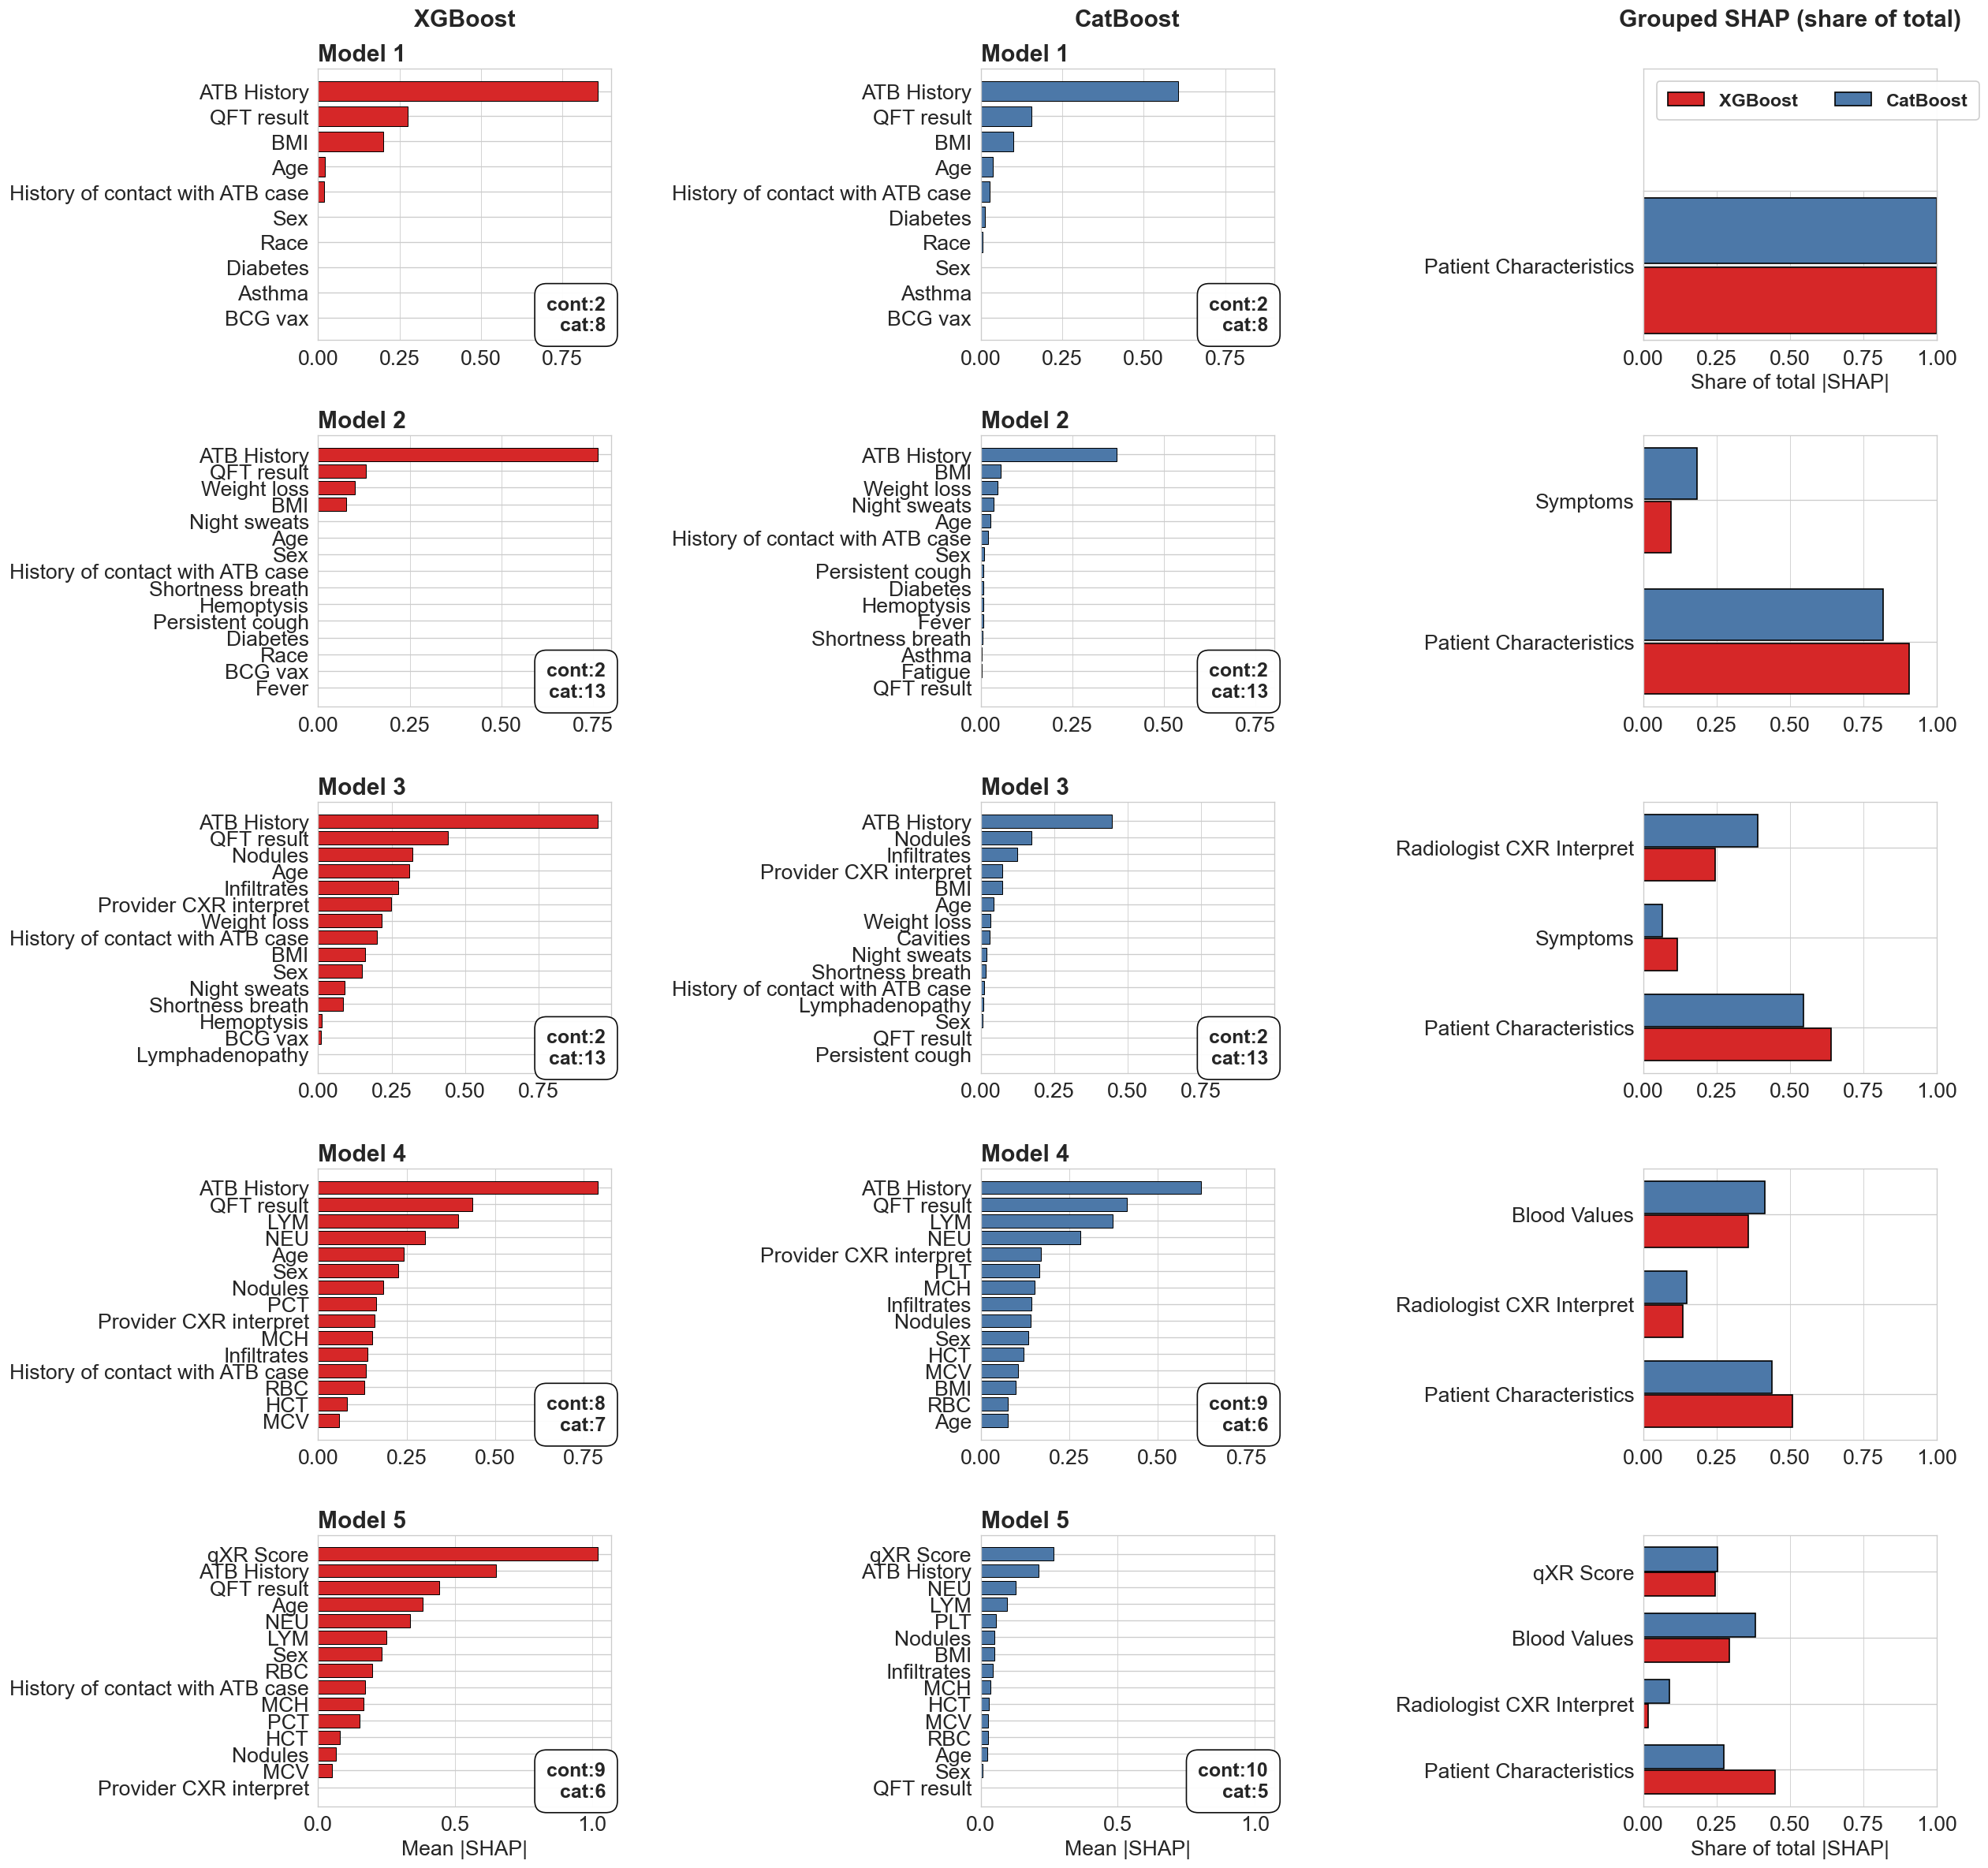

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/fig_rfe_carryforward_xgb_cat_plus_grouped.png


In [21]:
# =============== 12) FIGURE 4: 5 MODELS SHAP + GROUPED ===============
from collections import OrderedDict
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from sklearn.model_selection import StratifiedKFold
from xgboost import DMatrix, train as xgb_train
from catboost import CatBoostClassifier, Pool

# ---- Define stages ----
baseline_vars = ['age','gender','race_collapsed','bmi','diabetes','asthma',
                 'bcg','lived_with_another_tb','tb_history_composite','QFT_result_composite']
clinical_vars = ['persistent_cough','shortness_of_breath','fever','fatigue',
                 'cough_blood','weight_loss','night_sweats']
radiologist_interpret = ['lung_infiltrates','lung_nodules','lung_cavities',
                         'pleural_effusion','lymph_nodes','imaging_tb']
blood_vars_continuous = ["CBC_WBC","CBC_NEU_freq","CBC_LYM_freq","CBC_P_LCR",
                         "CBC_RBC","CBC_HGB","CBC_HCT","CBC_MCHC","CBC_MCH","CBC_MCV",
                         "CBC_RDW_CV","CBC_RDW_SD","CBC_PLT","CBC_MPV","CBC_PCT","CBC_PDW"]

stage_new = OrderedDict({
    "Model 1": baseline_vars,
    "Model 2": clinical_vars,
    "Model 3": radiologist_interpret,
    "Model 4": blood_vars_continuous,
    "Model 5": ["Score"],
})
stage_K = {"Model 1": 10, "Model 2": 15, "Model 3": 15, "Model 4": 15, "Model 5": 15}
GROUPS = {
    "Patient Characteristics": baseline_vars,
    "Symptoms": clinical_vars,
    "Radiologist CXR Interpret": radiologist_interpret,
    "Blood Values": blood_vars_continuous,
    "qXR Score": ["Score"],
}

# ---- Data (assumes upstream variables exist) ----
X_train_full = feature_train.copy()
X_test_full  = feature_test.copy()
y_train_full = target_train.astype(int).copy()
y_test_full  = target_test.astype(int).copy()

# Drop random control for this figure
if RAND_NAME in X_train_full: X_train_full = X_train_full.drop(columns=[RAND_NAME])
if RAND_NAME in X_test_full:  X_test_full  = X_test_full.drop(columns=[RAND_NAME])

def make_dm(df, y=None):
    return DMatrix(align_categoricals(df), label=y, enable_categorical=True)

def count_types_dynamic(feats, X_train, cat_names):
    feats = [f for f in feats if f in X_train.columns]
    cat_set = set(cat_names)
    n_cat = sum(1 for f in feats if f in cat_set)
    n_cont = len(feats) - n_cat
    n_bool = sum(1 for f in feats if str(X_train[f].dtype) == "bool")
    return n_cont, n_cat, n_bool

# ---- CatBoost verbosity scrubber (avoid conflicts) ----
def _clean_cat_verbose(params: dict) -> dict:
    p = dict(params)
    for k in ("verbose", "verbose_eval", "silent", "logging_level"):
        p.pop(k, None)
    p["logging_level"] = "Silent"   # choose exactly one
    return p

# ---- OOF mean |SHAP| per feature (re-trains per fold; quiet) ----
def oof_mean_abs_shap(algo, X, y, feats, n_outer=N_OUTER, seed=RANDOM_STATE):
    feats = [f for f in feats if f in X.columns]
    if not feats:
        return pd.Series(dtype=float)

    skf = StratifiedKFold(n_splits=n_outer, shuffle=True, random_state=seed)
    fold_means = []
    for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
        X_tr_full, y_tr_full = X.iloc[tr_idx], y.iloc[tr_idx]
        X_te = align_categoricals(X.iloc[te_idx][feats].copy())

        if algo == "XGB":
            (best, rounds), _ = tune_xgb_params_auc(X_tr_full, y_tr_full, feats, seed+fold)
            best = dict(best); best.setdefault("verbosity", 0)
            dtr = make_dm(align_categoricals(X_tr_full[feats]), y_tr_full)
            booster = xgb_train(best, dtr, num_boost_round=rounds, verbose_eval=False)
            sv = np.asarray(booster.predict(make_dm(X_te), pred_contribs=True))[:, :len(feats)]
        else:  # CAT
            params_final, _ = tune_cat_params_auc(X_tr_full, y_tr_full, feats, seed+fold)
            params_final = _clean_cat_verbose(params_final)
            Xt = align_categoricals(X_tr_full[feats])
            cat_idx = [Xt.columns.get_loc(c) for c in CATS if c in Xt.columns]
            model = CatBoostClassifier(**params_final)
            # no verbose kw here; logging_level handled in params
            model.fit(Xt, y_tr_full, cat_features=cat_idx if len(cat_idx) else None)
            pool = Pool(X_te, cat_features=[X_te.columns.get_loc(c) for c in CATS if c in X_te.columns])
            sv = np.asarray(model.get_feature_importance(pool, type='ShapValues'))[:, :len(feats)]

        fold_means.append(np.abs(sv).mean(axis=0))

    return pd.Series(np.mean(fold_means, axis=0), index=feats)

# ---- Carry-forward RFE using OOF |SHAP| ----
def carry_forward_rfe(
    algo, X, y, stage_new: OrderedDict, stage_K: dict,
    *, verbose: bool = False, pretty_names: bool = True, log_path: str | None = None
):
    def _pretty(name: str) -> str:
        return rename_dict.get(name, name) if pretty_names else name

    selected_by_stage, rankings_by_stage, prev_selected = OrderedDict(), OrderedDict(), []
    events = []

    for stage, new_feats in stage_new.items():
        pool = list(dict.fromkeys(prev_selected + [f for f in new_feats if f in X.columns]))
        shap_series = oof_mean_abs_shap(algo, X, y, pool).sort_values(ascending=False)
        K = int(stage_K[stage])
        kept = list(shap_series.index[:min(K, len(shap_series))])

        retained_prev = [f for f in prev_selected if f in kept]
        dropped_prev  = [f for f in prev_selected if f not in kept]
        selected_new  = [f for f in new_feats if f in kept]
        not_selected_new = [f for f in new_feats if f not in kept]

        selected_by_stage[stage] = kept
        rankings_by_stage[stage] = shap_series
        prev_selected = kept

        if verbose:
            print(f"\n[{algo}] {stage}: K={len(kept)} from pool={len(pool)}")
            if retained_prev:
                print(f"  Retained ({len(retained_prev)}):", ", ".join(_pretty(x) for x in retained_prev))
            if selected_new:
                print(f"  Selected new ({len(selected_new)}):", ", ".join(_pretty(x) for x in selected_new))
            if dropped_prev:
                print(f"  Dropped from previous ({len(dropped_prev)}):", ", ".join(_pretty(x) for x in dropped_prev))
            if not_selected_new:
                print(f"  Not selected (new block) ({len(not_selected_new)}):", ", ".join(_pretty(x) for x in not_selected_new))

        for f in retained_prev:
            events.append({"Algo": algo, "Stage": stage, "Change": "Retained", "Feature": f, "Display": _pretty(f)})
        for f in selected_new:
            events.append({"Algo": algo, "Stage": stage, "Change": "Selected new", "Feature": f, "Display": _pretty(f)})
        for f in dropped_prev:
            events.append({"Algo": algo, "Stage": stage, "Change": "Dropped from previous", "Feature": f, "Display": _pretty(f)})
        for f in not_selected_new:
            events.append({"Algo": algo, "Stage": stage, "Change": "Not selected (new block)", "Feature": f, "Display": _pretty(f)})

    if log_path is not None:
        try:
            pd.DataFrame(events).to_csv(log_path, index=False)
            if verbose:
                print(f"\nSaved feature-change log to: {log_path}")
        except Exception as e:
            print(f"Warning: failed to save log to {log_path}: {e}")

    return selected_by_stage, rankings_by_stage

# ---- Run RFE ONCE per algorithm (with logs, quiet) ----
X_all = X_train_full.copy(); y_all = y_train_full.copy()
xgb_selected, xgb_rankings = carry_forward_rfe(
    "XGB", X_all, y_all, stage_new, stage_K, verbose=False, log_path=f"{CSV_DIR}/rfe_flow_XGB.csv"
)
cat_selected, cat_rankings = carry_forward_rfe(
    "CAT", X_all, y_all, stage_new, stage_K, verbose=False, log_path=f"{CSV_DIR}/rfe_flow_CatBoost.csv"
)

# ---- Final fits for plotting (once per stage; quiet) ----
def fit_final_xgb_for_fig(feats):
    Xt = align_categoricals(X_all[feats])
    (params, rounds), _ = tune_xgb_params_auc(X_all, y_all, feats, RANDOM_STATE+123)
    params = dict(params); params.setdefault("verbosity", 0)
    booster = xgb_train(params, DMatrix(Xt, label=y_all, enable_categorical=True),
                        num_boost_round=rounds, verbose_eval=False)
    return booster

def fit_final_cat_for_fig(feats):
    Xt = align_categoricals(X_all[feats])
    params, _ = tune_cat_params_auc(X_all, y_all, feats, RANDOM_STATE+123)
    params = _clean_cat_verbose(params)
    cat_idx = [Xt.columns.get_loc(c) for c in CATS if c in Xt.columns]
    model = CatBoostClassifier(**params)
    model.fit(Pool(Xt, y_all, cat_features=cat_idx if len(cat_idx) else None))
    return model

final_models_xgb = OrderedDict((st, {"model": fit_final_xgb_for_fig(feats), "feats": feats})
                               for st, feats in xgb_selected.items())
final_models_cat = OrderedDict((st, {"model": fit_final_cat_for_fig(feats), "feats": feats})
                               for st, feats in cat_selected.items())

# ---- SHAP helpers ----
def xgb_shap_on_test(booster, X_df):
    X_df = align_categoricals(X_df)
    return np.asarray(booster.predict(DMatrix(X_df, enable_categorical=True), pred_contribs=True))[:, :X_df.shape[1]]

def cat_shap_on_test(model, X_df):
    X_df = align_categoricals(X_df)
    pool = Pool(X_df, cat_features=[X_df.columns.get_loc(c) for c in CATS if c in X_df.columns])
    return np.asarray(model.get_feature_importance(pool, type='ShapValues'))[:, :X_df.shape[1]]

def _grouped_shap_for_stage(bundle, X, shap_func, groups: dict, normalize=True):
    feats = [f for f in bundle["feats"] if f in X.columns]
    Xs = align_categoricals(X[feats])
    sv = shap_func(bundle["model"], Xs)
    mag = np.abs(sv).mean(0)
    per_feat = pd.DataFrame({"feature": feats, "mean_abs_shap": mag})
    rows, inv = [], {}
    for g, flist in groups.items():
        for f in flist: inv.setdefault(f, []).append(g)
    for _, r in per_feat.iterrows():
        f = r["feature"]; v = float(r["mean_abs_shap"])
        for g in inv.get(f, ["(Unassigned)"]):
            rows.append((g, v))
    gdf = pd.DataFrame(rows, columns=["Group", "mean_abs_shap"])
    gsum = gdf.groupby("Group", as_index=False)["mean_abs_shap"].sum().rename(columns={"mean_abs_shap":"sum_abs_shap"})
    if normalize:
        tot = gsum["sum_abs_shap"].sum()
        gsum["frac"] = (gsum["sum_abs_shap"] / tot) if tot > 0 else 0.0
    return gsum

# ---- FIGURE LAYOUT & PLOTTING ----
fig, axes = plt.subplots(5, 3, figsize=(21, 20), sharex=False)
axes = np.atleast_2d(axes)
mpl.rcParams.update({"font.size": 16})  # global font

# Column headers
axes[0,0].annotate("XGBoost", xy=(0.5,1.14), xycoords="axes fraction",
                   ha="center", va="bottom", fontsize=18, fontweight="bold")
axes[0,1].annotate("CatBoost", xy=(0.5,1.14), xycoords="axes fraction",
                   ha="center", va="bottom", fontsize=18, fontweight="bold")
axes[0,2].annotate("Grouped SHAP (share of total)", xy=(0.5,1.14), xycoords="axes fraction",
                   ha="center", va="bottom", fontsize=18, fontweight="bold")

xgb_color, cat_color = "#d62728", "#4c78a8"
top_k_bars = 15

for ri, stage in enumerate(stage_new.keys()):
    # ---- LEFT: XGB per-feature SHAP ----
    fx = final_models_xgb[stage]
    Xtx = X_test_full[fx["feats"]]
    svx = xgb_shap_on_test(fx["model"], Xtx)
    meanx = np.abs(svx).mean(0)
    idx = np.argsort(-meanx)[:min(top_k_bars, len(meanx))]
    plot_x = pd.DataFrame({
        "Feature":[rename_dict.get(fx["feats"][i], fx["feats"][i]) for i in idx][::-1],
        "Mean|SHAP|":meanx[idx][::-1]
    })

    axL = axes[ri,0]
    axL.barh(plot_x["Feature"], plot_x["Mean|SHAP|"], color=xgb_color, edgecolor="black", linewidth=0.6)
    axL.set_title(stage, loc="left", fontsize=18, fontweight="bold")
    if ri == 4: axL.set_xlabel("Mean |SHAP|")
    axL.grid(True, axis="x", linewidth=0.5)

    x_cont, x_cat, _ = count_types_dynamic(fx["feats"], X_train_full, CATS)
    axL.text(0.98, 0.02, f"cont:{x_cont}\ncat:{x_cat}",
             transform=axL.transAxes, ha="right", va="bottom",
             fontsize=15, fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="black", lw=1.0, alpha=0.95))

    # ---- MIDDLE: CAT per-feature SHAP ----
    fc = final_models_cat[stage]
    Xtc = X_test_full[fc["feats"]]
    svc = cat_shap_on_test(fc["model"], Xtc)
    meanc = np.abs(svc).mean(0)
    idc = np.argsort(-meanc)[:min(top_k_bars, len(meanc))]
    plot_c = pd.DataFrame({
        "Feature":[rename_dict.get(fc["feats"][i], fc["feats"][i]) for i in idc][::-1],
        "Mean|SHAP|":meanc[idc][::-1]
    })

    axR = axes[ri,1]
    axR.barh(plot_c["Feature"], plot_c["Mean|SHAP|"], color=cat_color, edgecolor="black", linewidth=0.6)
    axR.set_title(stage, loc="left", fontsize=18, fontweight="bold")
    if ri == 4: axR.set_xlabel("Mean |SHAP|")
    axR.grid(True, axis="x", linewidth=0.5)

    c_cont, c_cat, _ = count_types_dynamic(fc["feats"], X_train_full, CATS)
    axR.text(0.98, 0.02, f"cont:{c_cont}\ncat:{c_cat}",
             transform=axR.transAxes, ha="right", va="bottom",
             fontsize=15, fontweight="bold",
             bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="black", lw=1.0, alpha=0.95))

    # ---- RIGHT: Grouped SHAP ----
    gx = _grouped_shap_for_stage(fx, X_test_full, lambda m, X: xgb_shap_on_test(m, X), GROUPS, normalize=True)
    gc = _grouped_shap_for_stage(fc, X_test_full, lambda m, X: cat_shap_on_test(m, X), GROUPS, normalize=True)
    canonical = list(GROUPS.keys())
    union = list(sorted(set(gx["Group"]).union(gc["Group"]),
                        key=lambda g: (0 if g in canonical else 1, canonical.index(g) if g in canonical else 999)))
    gx = gx.set_index("Group").reindex(union).fillna(0.0).reset_index()
    gc = gc.set_index("Group").reindex(union).fillna(0.0).reset_index()

    y = np.arange(len(union))
    axG = axes[ri,2]

    if ri == 0:
        # Lower-half inset for bars
        axG_lower = axG.inset_axes([0.00, 0.00, 1.00, 0.55])
        bw = 0.25
        axG_lower.barh(y - bw/2, gx["frac"].values, height=bw*0.95,
                       color=xgb_color, edgecolor="black", label="XGBoost")
        axG_lower.barh(y + bw/2, gc["frac"].values, height=bw*0.95,
                       color=cat_color, edgecolor="black", label="CatBoost")
        axG_lower.set_yticks(y); axG_lower.set_yticklabels(union)
        axG_lower.set_xlim(0, 1.0); axG_lower.grid(True, axis="x", linewidth=0.5)
        axG_lower.set_xlabel("Share of total |SHAP|")

        # Legend in upper half of parent axis (big & bold)
        handles, labels = axG_lower.get_legend_handles_labels()
        by_label = OrderedDict(zip(labels, handles))
        leg = axG.legend(by_label.values(), by_label.keys(),
                         loc="upper left", bbox_to_anchor=(0.02, 0.98),
                         frameon=True, framealpha=0.95, borderpad=0.6, borderaxespad=0.4,
                         ncol=2, fontsize=14)
        for txt in leg.get_texts():
            txt.set_fontweight("bold")
        axG.set_xticks([]); axG.set_yticks([])
    else:
        # No labels here -> no stray small legends
        bw = 0.38
        axG.barh(y - bw/2, gx["frac"].values, height=bw*0.95, color=xgb_color, edgecolor="black")
        axG.barh(y + bw/2, gc["frac"].values, height=bw*0.95, color=cat_color, edgecolor="black")
        axG.set_yticks(y); axG.set_yticklabels(union); axG.set_xlim(0, 1.0)
        if ri == 4: axG.set_xlabel("Share of total |SHAP|")
        axG.grid(True, axis="x", linewidth=0.5)
        if axG.get_legend() is not None:
            axG.get_legend().remove()

# Harmonize x-lims in first two columns per row
for r in range(5):
    xmax = 0.0
    for c in (0,1):
        if len(axes[r,c].patches):
            xmax = max(xmax, max(p.get_width() for p in axes[r,c].patches))
    for c in (0,1):
        axes[r,c].set_xlim(0, xmax*1.05 if xmax>0 else 1.0)

fig_path = f"{IMG_DIR}/fig_rfe_carryforward_xgb_cat_plus_grouped.png"
plt.tight_layout(h_pad=2.0, w_pad=2.2)
plt.savefig(fig_path, dpi=150); plt.show()
print("Saved:", fig_path)


In [16]:
# =============== 13) METRICS TABLES BY STAGE (TEST) ===============
def eval_stage_cat(feats, seed=RANDOM_STATE):
    feats = [f for f in feats if f in X_train_full.columns]
    params, _ = tune_cat_params_sens(X_train_full, y_train_full, feats, seed, TARGET_SPEC)
    Xtr, Xval, ytr, yval, _ = safe_train_val_split(align_categoricals(X_train_full[feats]), y_train_full, seed=seed)
    cat_idx = [Xtr.columns.get_loc(c) for c in CATS if c in Xtr.columns]
    model = CatBoostClassifier(**params)
    model.fit(Xtr, ytr, eval_set=(Xval, yval), cat_features=cat_idx if len(cat_idx) else None,
              early_stopping_rounds=80, verbose=False)
    thr, _, _ = threshold_at_spec(yval, model.predict_proba(Xval)[:,1], TARGET_SPEC)
    Xte = align_categoricals(X_test_full[feats]); pte = model.predict_proba(Xte)[:,1]
    sens, spec, ppv, npv = sens_spec_ppv_npv(y_test_full, pte, thr)
    return dict(Sens=sens, Spec=spec, PPV=ppv, NPV=npv,
                AUROC=roc_auc_score(y_test_full, pte),
                AP=average_precision_score(y_test_full, pte),
                Brier=brier_score_loss(y_test_full, as_proba(pte)),
                Thr=thr)

def eval_stage_xgb(feats, seed=RANDOM_STATE):
    feats = [f for f in feats if f in X_train_full.columns]
    params, _ = tune_xgb_params_sens(X_train_full, y_train_full, feats, seed, TARGET_SPEC)
    Xtr, Xval, ytr, yval, _ = safe_train_val_split(align_categoricals(X_train_full[feats]), y_train_full, seed=seed)
    dtr  = DMatrix(Xtr, ytr, enable_categorical=True); dval = DMatrix(Xval, yval, enable_categorical=True)
    booster = xgb_train(params, dtr, num_boost_round=2000, evals=[(dval,"val")], early_stopping_rounds=80, verbose_eval=False)
    thr, _, _ = threshold_at_spec(yval, booster.predict(dval), TARGET_SPEC)
    dte = DMatrix(align_categoricals(X_test_full[feats]), enable_categorical=True)
    pte = booster.predict(dte)
    sens, spec, ppv, npv = sens_spec_ppv_npv(y_test_full, pte, thr)
    return dict(Sens=sens, Spec=spec, PPV=ppv, NPV=npv,
                AUROC=roc_auc_score(y_test_full, pte),
                AP=average_precision_score(y_test_full, pte),
                Brier=brier_score_loss(y_test_full, as_proba(pte)),
                Thr=thr)

rows_cat, rows_xgb = [], []
for st in stage_new.keys():
    feats_cat = cat_selected[st]; feats_xgb = xgb_selected[st]
    rows_cat.append(dict(Model=st, **{k: float(v) for k,v in eval_stage_cat(feats_cat, seed=RANDOM_STATE+7).items()}))
    rows_xgb.append(dict(Model=st, **{k: float(v) for k,v in eval_stage_xgb(feats_xgb, seed=RANDOM_STATE+7).items()}))

tbl_cat = pd.DataFrame(rows_cat).set_index("Model")
tbl_xgb = pd.DataFrame(rows_xgb).set_index("Model")

print("\n=== Metrics — CatBoost (Test, thr at Spec≥{:.2f}) ===".format(TARGET_SPEC)); print(tbl_cat.round(3))
print("\n=== Metrics — XGBoost  (Test, thr at Spec≥{:.2f}) ===".format(TARGET_SPEC)); print(tbl_xgb.round(3))

tbl_cat.to_csv(f"{CSV_DIR}/fig3_metrics_catboost_by_stage.csv")
tbl_xgb.to_csv(f"{CSV_DIR}/fig3_metrics_xgboost_by_stage.csv")
print("Saved metrics CSVs.")



=== Metrics — CatBoost (Test, thr at Spec≥0.80) ===
          Sens   Spec    PPV    NPV  AUROC     AP  Brier    Thr
Model                                                          
Model 1  0.686  0.839  0.545  0.904  0.810  0.532  0.171  0.471
Model 2  0.743  0.806  0.520  0.917  0.837  0.624  0.123  0.198
Model 3  0.829  0.839  0.592  0.945  0.883  0.655  0.110  0.182
Model 4  0.714  0.831  0.543  0.912  0.889  0.742  0.109  0.268
Model 5  0.914  0.823  0.593  0.971  0.937  0.840  0.085  0.217

=== Metrics — XGBoost  (Test, thr at Spec≥0.80) ===
          Sens   Spec    PPV    NPV  AUROC     AP  Brier    Thr
Model                                                          
Model 1  0.457  0.895  0.552  0.854  0.795  0.484  0.136  0.427
Model 2  0.629  0.847  0.537  0.890  0.844  0.655  0.121  0.233
Model 3  0.743  0.879  0.634  0.924  0.888  0.640  0.120  0.280
Model 4  0.743  0.847  0.578  0.921  0.900  0.780  0.106  0.217
Model 5  0.829  0.847  0.604  0.946  0.925  0.803  0.088  0.15

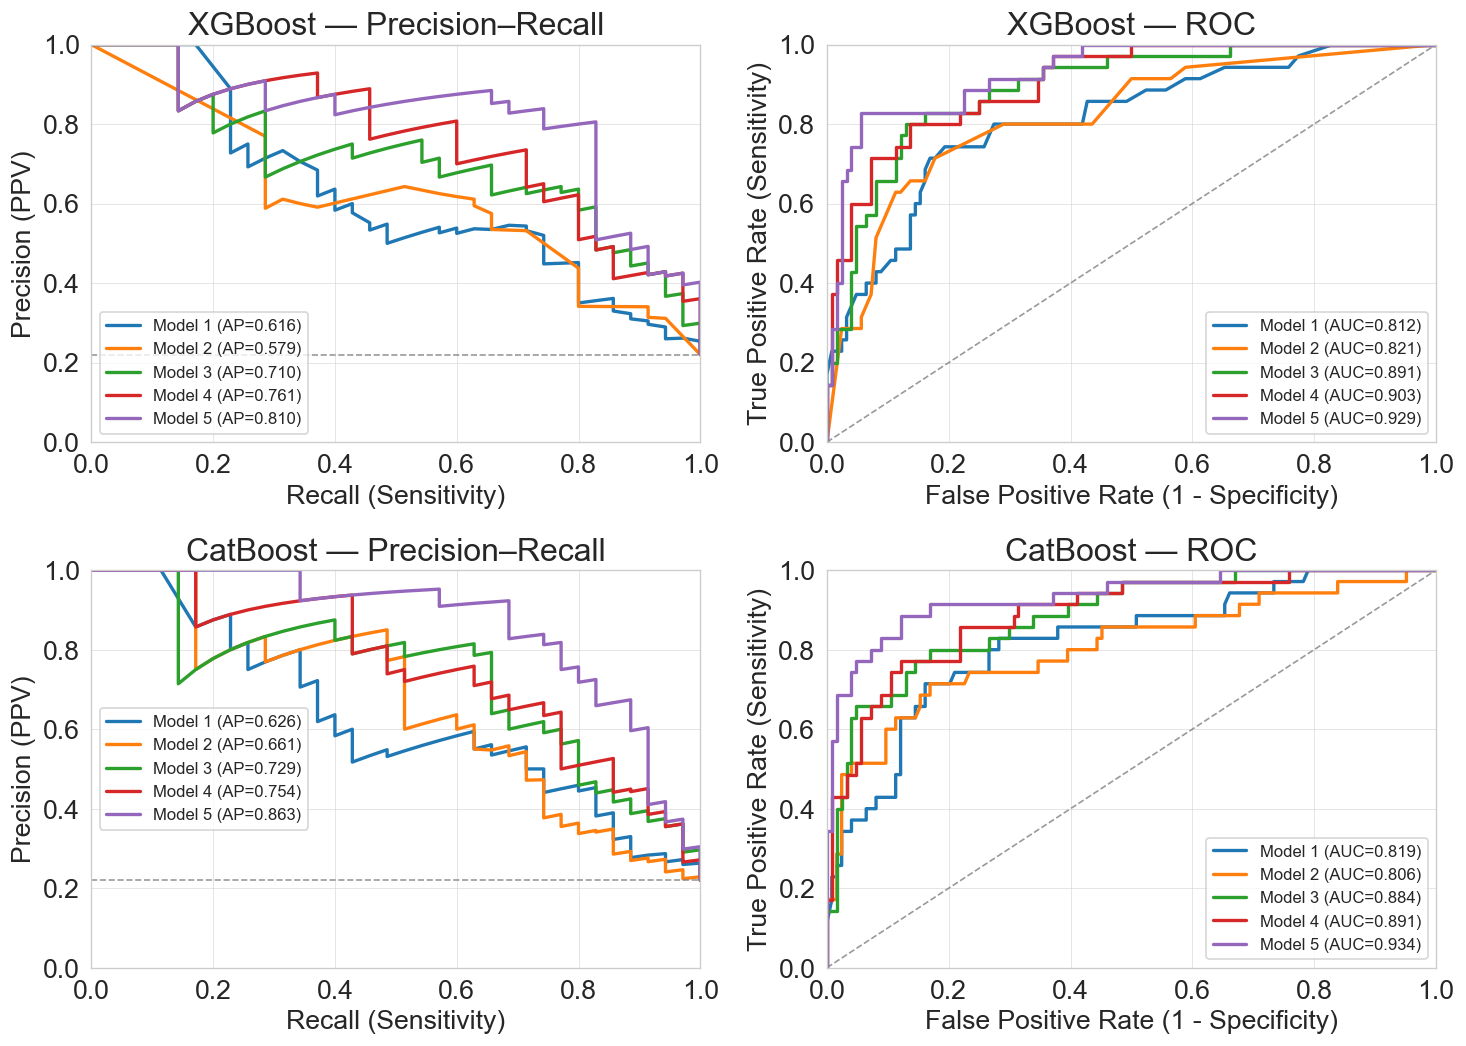

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/fig_staged_PR_left_ROC_right_xgb_cat.png


In [17]:
# =============== FIGURE: PR (left) + ROC (right) for 5 staged models, XGB (top) & CAT (bottom) ===============
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_curve, roc_auc_score

# --- helpers to get test-set probabilities per stage ---
def _proba_xgb(bundle, X):
    feats = [f for f in bundle["feats"] if f in X.columns]
    Xs = align_categoricals(X[feats])
    d = DMatrix(Xs, enable_categorical=True)
    return bundle["model"].predict(d), feats

def _proba_cat(bundle, X):
    feats = [f for f in bundle["feats"] if f in X.columns]
    Xs = align_categoricals(X[feats])
    cat_idx = [Xs.columns.get_loc(c) for c in CATS if c in Xs.columns]
    pool = Pool(Xs, cat_features=cat_idx if len(cat_idx) else None)
    return bundle["model"].predict_proba(pool)[:, 1], feats

def _plot_pr_roc_row(final_models, algo_label, ax_pr, ax_roc, colors=None):
    # consistent model order
    stages = list(stage_new.keys())
    if colors is None:
        colors = plt.cm.tab10.colors  # 10 distinct colors; we need first 5

    # prevalence baseline for PR
    prev = float(np.mean(y_test_full))

    for i, st in enumerate(stages):
        bundle = final_models[st]
        if algo_label.upper().startswith("XGB"):
            p, feats = _proba_xgb(bundle, X_test_full)
        else:
            p, feats = _proba_cat(bundle, X_test_full)

        # PR
        prec, rec, _ = precision_recall_curve(y_test_full, p)
        ap = average_precision_score(y_test_full, p)
        ax_pr.plot(rec, prec, lw=2, color=colors[i], label=f"{st} (AP={ap:.3f})")

        # ROC
        fpr, tpr, _ = roc_curve(y_test_full, p)
        auc = roc_auc_score(y_test_full, p)
        ax_roc.plot(fpr, tpr, lw=2, color=colors[i], label=f"{st} (AUC={auc:.3f})")

    # PR cosmetics
    ax_pr.set_title(f"{algo_label} — Precision–Recall")
    ax_pr.set_xlabel("Recall (Sensitivity)"); ax_pr.set_ylabel("Precision (PPV)")
    ax_pr.set_xlim(0, 1); ax_pr.set_ylim(0, 1)
    ax_pr.axhline(prev, ls="--", lw=1, color="gray", alpha=0.8)  # prevalence baseline
    ax_pr.grid(True, linewidth=0.5, alpha=0.6)
    ax_pr.legend(frameon=True, fontsize=10)

    # ROC cosmetics
    ax_roc.set_title(f"{algo_label} — ROC")
    ax_roc.set_xlabel("False Positive Rate (1 - Specificity)"); ax_roc.set_ylabel("True Positive Rate (Sensitivity)")
    ax_roc.set_xlim(0, 1); ax_roc.set_ylim(0, 1)
    ax_roc.plot([0,1], [0,1], ls="--", lw=1, color="gray", alpha=0.8)
    ax_roc.grid(True, linewidth=0.5, alpha=0.6)
    ax_roc.legend(frameon=True, fontsize=10)

# --- figure layout: 2 rows (XGB, CAT) x 2 cols (PR, ROC) ---
fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.0), sharex=False, sharey=False)
(ax_pr_xgb, ax_roc_xgb), (ax_pr_cat, ax_roc_cat) = axes

_plot_pr_roc_row(final_models_xgb, "XGBoost", ax_pr_xgb, ax_roc_xgb)
_plot_pr_roc_row(final_models_cat, "CatBoost", ax_pr_cat, ax_roc_cat)

plt.tight_layout()
out_path = f"{IMG_DIR}/fig_staged_PR_left_ROC_right_xgb_cat.png"
plt.savefig(out_path, dpi=200, bbox_inches="tight"); plt.show()
print("Saved:", out_path)


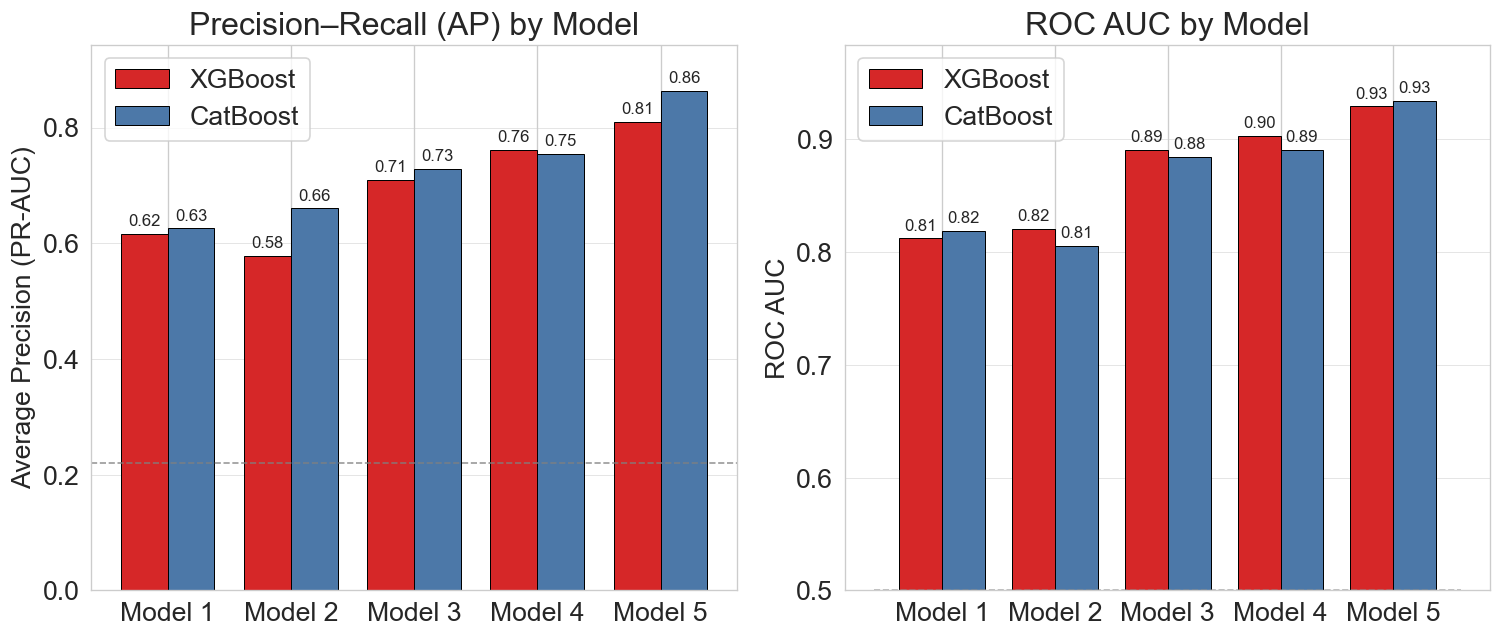

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/fig_bar_AP_left_AUC_right_stages_xgb_cat.png
              AP              AUC        
Algo    CatBoost XGBoost CatBoost XGBoost
Model                                    
Model 1    0.626   0.616    0.819   0.812
Model 2    0.661   0.579    0.806   0.821
Model 3    0.729   0.710    0.884   0.891
Model 4    0.754   0.761    0.891   0.903
Model 5    0.863   0.810    0.934   0.929


In [18]:
# =============== FIGURE: Barplots — PR-AUC (left) and ROC-AUC (right) across 5 stages ===============
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score

# Helpers to get test-set probabilities per stage (reuse your fitted models)
def _proba_xgb(bundle, X):
    feats = [f for f in bundle["feats"] if f in X.columns]
    Xs = align_categoricals(X[feats])
    d = DMatrix(Xs, enable_categorical=True)
    return bundle["model"].predict(d)

def _proba_cat(bundle, X):
    feats = [f for f in bundle["feats"] if f in X.columns]
    Xs = align_categoricals(X[feats])
    cat_idx = [Xs.columns.get_loc(c) for c in CATS if c in Xs.columns]
    pool = Pool(Xs, cat_features=cat_idx if len(cat_idx) else None)
    return bundle["model"].predict_proba(pool)[:, 1]

stages = list(stage_new.keys())
metrics = []
for st in stages:
    # XGB
    p_x = _proba_xgb(final_models_xgb[st], X_test_full)
    metrics.append({"Model": st, "Algo": "XGBoost",
                    "AP": average_precision_score(y_test_full, p_x),
                    "AUC": roc_auc_score(y_test_full, p_x)})
    # CAT
    p_c = _proba_cat(final_models_cat[st], X_test_full)
    metrics.append({"Model": st, "Algo": "CatBoost",
                    "AP": average_precision_score(y_test_full, p_c),
                    "AUC": roc_auc_score(y_test_full, p_c)})

df = pd.DataFrame(metrics)

# Colors to match your scheme
xgb_color, cat_color = "#d62728", "#4c78a8"

# Prepare grouped bars
x = np.arange(len(stages)); w = 0.38
ap_xgb  = df[df.Algo=="XGBoost"].set_index("Model").loc[stages]["AP"].values
ap_cat  = df[df.Algo=="CatBoost"].set_index("Model").loc[stages]["AP"].values
auc_xgb = df[df.Algo=="XGBoost"].set_index("Model").loc[stages]["AUC"].values
auc_cat = df[df.Algo=="CatBoost"].set_index("Model").loc[stages]["AUC"].values
prev = float(np.mean(y_test_full))

fig, (ax_ap, ax_auc) = plt.subplots(1, 2, figsize=(12.8, 5.6))

# --- PR-AUC (AP) ---
bars_ap_x = ax_ap.bar(x - w/2, ap_xgb, width=w, label="XGBoost",
                      color=xgb_color, edgecolor="black", linewidth=0.6)
bars_ap_c = ax_ap.bar(x + w/2, ap_cat, width=w, label="CatBoost",
                      color=cat_color, edgecolor="black", linewidth=0.6)
ax_ap.set_xticks(x); ax_ap.set_xticklabels(stages)
ap_max = float(np.max([ap_xgb.max(), ap_cat.max()]))
ax_ap.set_ylim(0, min(1.0, ap_max + 0.08))  # add headroom for labels
ax_ap.set_ylabel("Average Precision (PR-AUC)")
ax_ap.set_title("Precision–Recall (AP) by Model")
ax_ap.axhline(prev, ls="--", lw=1, color="gray", alpha=0.8)  # prevalence baseline
ax_ap.grid(True, axis="y", linewidth=0.5, alpha=0.6)
ax_ap.legend(frameon=True)

# add value labels
try:
    ax_ap.bar_label(bars_ap_x, fmt="%.2f", padding=3, fontsize=10)
    ax_ap.bar_label(bars_ap_c, fmt="%.2f", padding=3, fontsize=10)
except Exception:
    # fallback if bar_label is unavailable
    for bars in (bars_ap_x, bars_ap_c):
        for b in bars:
            h = b.get_height()
            ax_ap.text(b.get_x()+b.get_width()/2, h + 0.02, f"{h:.2f}",
                       ha="center", va="bottom", fontsize=10)

# --- ROC-AUC ---
bars_auc_x = ax_auc.bar(x - w/2, auc_xgb, width=w, label="XGBoost",
                        color=xgb_color, edgecolor="black", linewidth=0.6)
bars_auc_c = ax_auc.bar(x + w/2, auc_cat, width=w, label="CatBoost",
                        color=cat_color, edgecolor="black", linewidth=0.6)
ax_auc.set_xticks(x); ax_auc.set_xticklabels(stages)
auc_max = float(np.max([auc_xgb.max(), auc_cat.max()]))
auc_min = float(np.min([auc_xgb.min(), auc_cat.min()]))
ax_auc.set_ylim(max(0.45, min(0.5, auc_min - 0.02)), min(1.0, auc_max + 0.05))
ax_auc.set_ylabel("ROC AUC")
ax_auc.set_title("ROC AUC by Model")
ax_auc.plot([x[0]-0.6, x[-1]+0.6], [0.5, 0.5], ls="--", lw=1, color="gray", alpha=0.6)
ax_auc.grid(True, axis="y", linewidth=0.5, alpha=0.6)
ax_auc.legend(frameon=True)

# add value labels
try:
    ax_auc.bar_label(bars_auc_x, fmt="%.2f", padding=3, fontsize=10)
    ax_auc.bar_label(bars_auc_c, fmt="%.2f", padding=3, fontsize=10)
except Exception:
    for bars in (bars_auc_x, bars_auc_c):
        for b in bars:
            h = b.get_height()
            ax_auc.text(b.get_x()+b.get_width()/2, h + 0.015, f"{h:.2f}",
                        ha="center", va="bottom", fontsize=10)

plt.tight_layout()
out_path = f"{IMG_DIR}/fig_bar_AP_left_AUC_right_stages_xgb_cat.png"
plt.savefig(out_path, dpi=200, bbox_inches="tight"); plt.show()
print("Saved:", out_path)
print(df.pivot_table(index="Model", columns="Algo", values=["AP","AUC"]).round(3))


/var/folders/dh/6hpvwb7s6fl_671fts1fr6q9p0t2vg/T/ipykernel_47571/2301796771.py:47: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  is_cat = is_categorical_dtype(s) or is_object_dtype(s) or (col in CATS)
/var/folders/dh/6hpvwb7s6fl_671fts1fr6q9p0t2vg/T/ipykernel_47571/2301796771.py:47: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  is_cat = is_categorical_dtype(s) or is_object_dtype(s) or (col in CATS)
/var/folders/dh/6hpvwb7s6fl_671fts1fr6q9p0t2vg/T/ipykernel_47571/2301796771.py:47: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  is_cat = is_categorical_dtype(s) or is_object_dtype(s) or (col in CATS)
/var/folders/dh/6hpvwb7s6fl_671fts1fr6q9p0t2vg/T/ipykernel_47571/2301796771.py:47: Depre

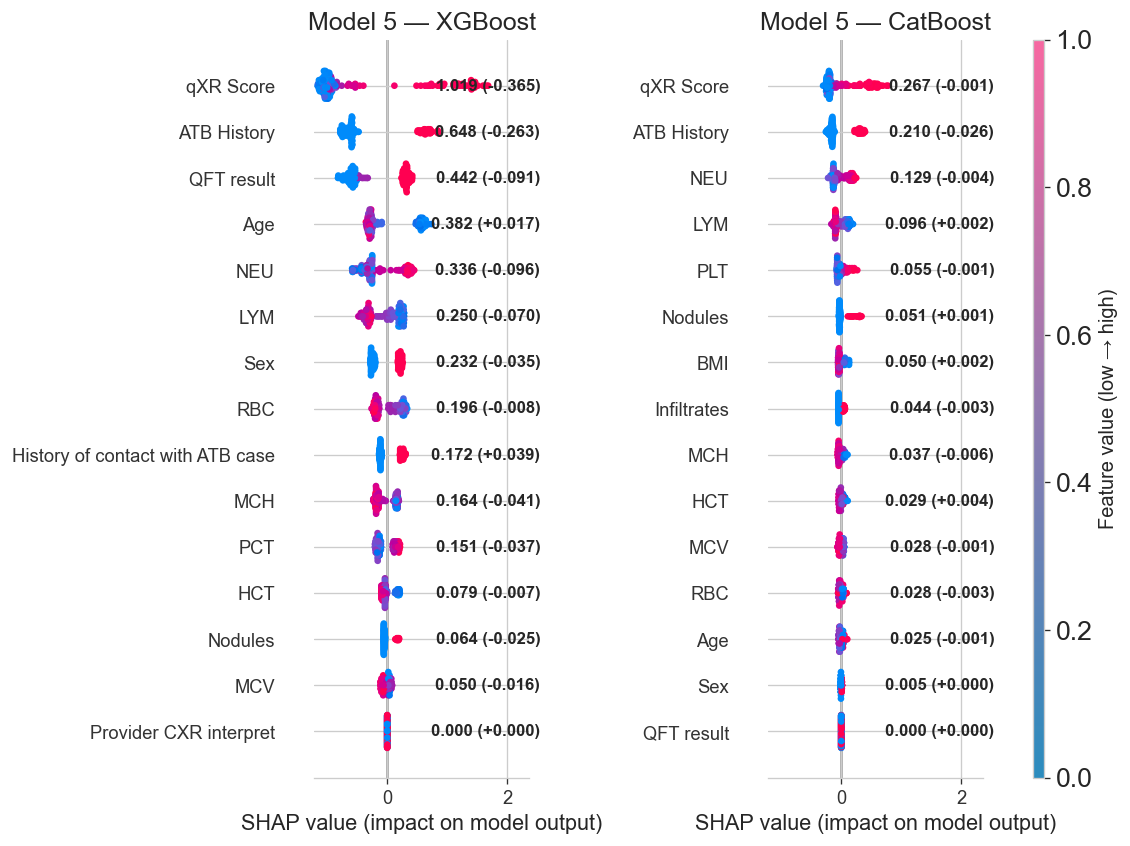

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/fig5_shap_beeswarm_model5_xgb_vs_cat_wide.png


In [19]:
# =============== 14) FIGURE 5: SHAP BEESWARMS (MODEL 5) ===============
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
import matplotlib.gridspec as gridspec
from matplotlib import transforms as mtrans
from xgboost import DMatrix
from catboost import Pool
import shap  # pip install shap
from matplotlib.colors import LinearSegmentedColormap

blue_purple_pink = LinearSegmentedColormap.from_list(
    "blue_purple_pink", ["#2b8cbe", "#9e77e5", "#f768a1"], N=256
)
# pass this to shap.summary_plot(..., color=blue_purple_pink, ...)


# ---- Grab Model 5 bundles (assumes final_models_xgb/cat exist from earlier steps) ----
bundle_xgb = final_models_xgb["Model 5"]
bundle_cat = final_models_cat["Model 5"]

# Exclude the random control feature if present
_rand = globals().get("RAND_NAME", None)
feats_xgb = [f for f in bundle_xgb["feats"] if (_rand is None or f != _rand)]
feats_cat = [f for f in bundle_cat["feats"] if (_rand is None or f != _rand)]

# Prepare test matrices (assumes feature_test and align_categoricals, CATS, rename_dict exist)
X5_raw_xgb = align_categoricals(feature_test[feats_xgb].copy())
X5_raw_cat = align_categoricals(feature_test[feats_cat].copy())

def to_numeric_for_coloring(X: pd.DataFrame) -> pd.DataFrame:
    import numpy as np, pandas as pd
    from pandas.api.types import is_categorical_dtype, is_object_dtype

    # optional: enforce desired orders so colors match intuition
    desired_orders = {
        "QFT_result_composite": ["Negative", "Indeterminate", "Positive"],
        "gender": ["Female", "Male"],  # Female=blue (low), Male=pink (high)
    }

    Xn = X.copy()
    for col in Xn.columns:
        s = Xn[col]

        # if categorical / object / declared CATS → treat as categorical
        is_cat = is_categorical_dtype(s) or is_object_dtype(s) or (col in CATS)

        if is_cat:
            s = s.astype("category")
            # apply desired order if provided (and present)
            if col in desired_orders:
                cats = [c for c in desired_orders[col] if c in s.cat.categories]
                # keep any remaining categories (except __OTHER__) at the end (optional)
                tail = [c for c in s.cat.categories if c not in cats and c != "__OTHER__"]
                s = s.cat.set_categories(cats + tail, ordered=True)

            # drop the placeholder category from mapping if present
            cats = [c for c in s.cat.categories if c != "__OTHER__"]
            if len(cats) <= 1:
                Xn[col] = 0.0
                continue

            # map categories → 0..k-1, then → evenly spaced anchors in [0,1]
            code_map = {c: i for i, c in enumerate(cats)}
            raw_codes = s.map(code_map)
            k = len(cats)
            anchors = np.linspace(0.0, 1.0, k)
            anchor_map = {i: anchors[i] for i in range(k)}
            Xn[col] = raw_codes.map(anchor_map).astype(float)

        else:
            # continuous: keep numeric (no discrete anchors)
            Xn[col] = pd.to_numeric(s, errors="coerce")

    return Xn.rename(columns=rename_dict)

# Display frames (renamed for axis labels) + color frames (numeric)
X5_disp_xgb = X5_raw_xgb.rename(columns=rename_dict)
X5_disp_cat = X5_raw_cat.rename(columns=rename_dict)
X5_color_xgb = to_numeric_for_coloring(X5_raw_xgb)
X5_color_cat = to_numeric_for_coloring(X5_raw_cat)

# ---- Native SHAP extraction helpers ----
def xgb_shap_values_native(booster, X_df):
    d = DMatrix(align_categoricals(X_df), enable_categorical=True)
    contrib = booster.predict(d, pred_contribs=True)
    return np.asarray(contrib)[:, :X_df.shape[1]]  # drop bias term

def cat_shap_values_native(model, X_df):
    pool = Pool(align_categoricals(X_df), cat_features=[X_df.columns.get_loc(c) for c in CATS if c in X_df.columns])
    shap_vals = model.get_feature_importance(pool, type='ShapValues')
    return np.asarray(shap_vals)[:, :X_df.shape[1]]  # drop bias term

# ---- Compute SHAP values (Model 5) ----
sv5_xgb = xgb_shap_values_native(bundle_xgb["model"], X5_raw_xgb)
sv5_cat = cat_shap_values_native(bundle_cat["model"], X5_raw_cat)

# Order by mean absolute SHAP (ranking), but also compute SIGNED means for annotation
mean_abs5_xgb    = pd.Series(np.abs(sv5_xgb).mean(0), index=list(X5_disp_xgb.columns))
mean_abs5_cat    = pd.Series(np.abs(sv5_cat).mean(0), index=list(X5_disp_cat.columns))
mean_signed5_xgb = pd.Series(sv5_xgb.mean(0), index=list(X5_disp_xgb.columns))
mean_signed5_cat = pd.Series(sv5_cat.mean(0), index=list(X5_disp_cat.columns))

# ---- Shared axis limits across panels ----
blue_pink = LinearSegmentedColormap.from_list("blue_pink", ["#2b8cbe", "#f768a1"])
x_min_raw = float(min(np.nanmin(sv5_xgb), np.nanmin(sv5_cat)))
x_max_raw = float(max(np.nanmax(sv5_xgb), np.nanmax(sv5_cat)))
if not np.isfinite([x_min_raw, x_max_raw]).all():
    x_min_raw, x_max_raw = -1.0, 1.0
span = x_max_raw - x_min_raw if x_max_raw > x_min_raw else 1.0
shared_xlim = (x_min_raw - 0.02*span, x_max_raw + 0.24*span)  # room for numbers at right
blue_pink_mapper = ScalarMappable(cmap=blue_pink); blue_pink_mapper.set_array([])

# ---- Figure layout ----
fig = plt.figure(figsize=(26, 10), constrained_layout=False)
gs  = gridspec.GridSpec(1, 4, figure=fig, width_ratios=[1.15, 0.75, 1.15, 0.06], wspace=0.34)
ax1 = fig.add_subplot(gs[0, 0])   # XGB beeswarm
ax2 = fig.add_subplot(gs[0, 2])   # CAT beeswarm
cax = fig.add_subplot(gs[0, 3])   # colorbar

def beeswarm(ax, sv, X_color, title):
    plt.sca(ax)
    shap.summary_plot(
        sv, X_color,
        feature_names=list(X_color.columns),
        plot_type="dot", show=False,
        color=blue_pink, color_bar=False,
        max_display=20
    )
    ax = plt.gca()
    ax.set_title(title, fontsize=15)
    ax.set_xlim(*shared_xlim)
    ax.tick_params(axis="y", labelsize=11)
    return ax

ax1 = beeswarm(ax1, sv5_xgb, X5_color_xgb, "Model 5 — XGBoost")
ax2 = beeswarm(ax2, sv5_cat, X5_color_cat, "Model 5 — CatBoost")

# --- Replace your annotation helper + calls with this ---

from matplotlib import transforms as mtrans

def annotate_abs_then_signed(ax, abs_means, signed_means, *,
                             x_frac=1.02, dx_pts=0, fontsize=10):
    """
    Write 'abs (±signed)' to the right of each y-tick label.
    x_frac : x in axes fraction (0.1 inside; >1 outside to the right).
    dx_pts : extra rightward offset in display points.
    """
    ylabels = [t.get_text() for t in ax.get_yticklabels()]
    ylocs   = ax.get_yticks()

    # base: x in axes coords, y in data coords
    trans = mtrans.blended_transform_factory(ax.transAxes, ax.transData)
    if dx_pts:
        trans = trans + mtrans.ScaledTranslation(dx_pts/72.0, 0, ax.figure.dpi_scale_trans)

    ha = "left" if x_frac >= 1.0 else "right"

    for y, label in zip(ylocs, ylabels):
        a = abs_means.get(label, None)
        s = signed_means.get(label, None)
        if a is None and s is None:
            continue
        if (a is not None) and (s is not None):
            txt = f"{float(a):.3f} ({float(s):+.3f})"
        elif a is not None:
            txt = f"{float(a):.3f}"
        else:
            txt = f"({float(s):+.3f})"
        ax.text(x_frac, y, txt, transform=trans, ha=ha, va="center",
                fontweight="bold", fontsize=fontsize, clip_on=False)


annotate_abs_then_signed(
    ax1,
    mean_abs5_xgb.rename(index=rename_dict),
    mean_signed5_xgb.rename(index=rename_dict),
    x_frac=0.99, dx_pts=8, fontsize=10
)
annotate_abs_then_signed(
    ax2,
    mean_abs5_cat.rename(index=rename_dict),
    mean_signed5_cat.rename(index=rename_dict),
    x_frac=0.99, dx_pts=8, fontsize=10
)



# ---- Colorbar & final layout ----
cbar = fig.colorbar(blue_pink_mapper, cax=cax)
cbar.set_label("Feature value (low → high)", fontsize=12)

fig.subplots_adjust(left=0.26, right=1.02, bottom=0.10, top=0.92, wspace=0.34)

# ---- Save ----
out_path = f"{IMG_DIR}/fig5_shap_beeswarm_model5_xgb_vs_cat_wide.png"
plt.savefig(out_path, dpi=220, bbox_inches="tight"); plt.show()
print("Saved:", out_path)


/var/folders/dh/6hpvwb7s6fl_671fts1fr6q9p0t2vg/T/ipykernel_47571/4270712899.py:51: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  is_cat = is_categorical_dtype(s) or is_object_dtype(s) or (col in CATS)
/var/folders/dh/6hpvwb7s6fl_671fts1fr6q9p0t2vg/T/ipykernel_47571/4270712899.py:51: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  is_cat = is_categorical_dtype(s) or is_object_dtype(s) or (col in CATS)
/var/folders/dh/6hpvwb7s6fl_671fts1fr6q9p0t2vg/T/ipykernel_47571/4270712899.py:51: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  is_cat = is_categorical_dtype(s) or is_object_dtype(s) or (col in CATS)
/var/folders/dh/6hpvwb7s6fl_671fts1fr6q9p0t2vg/T/ipykernel_47571/4270712899.py:51: Depre

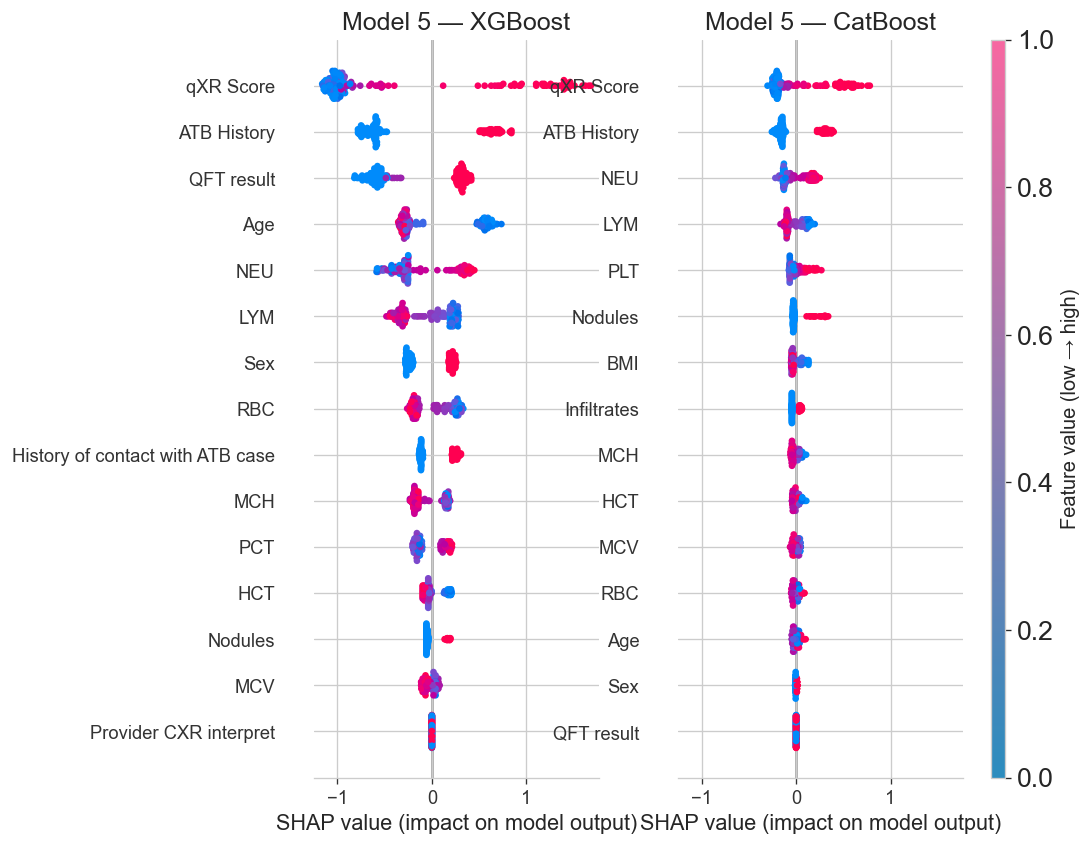

Saved: /Users/hbattey/Desktop/Rodwell/Output/Images/fig5_shap_beeswarm_model5_xgb_vs_cat_wide.png


In [16]:
#Epi practicum - remove the bold numbers

# =============== 14) FIGURE 5: SHAP BEESWARMS (MODEL 5) ===============
# CHANGES:
#  - Removed all numeric annotations (abs and signed means)
#  - Dropped mean_abs/mean_signed computation (not needed anymore)
#  - Tightened x-limits and grid layout (no space needed for numbers)

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
import matplotlib.gridspec as gridspec
from xgboost import DMatrix
from catboost import Pool
import shap  # pip install shap

# ---- Colormap ----
blue_purple_pink = LinearSegmentedColormap.from_list(
    "blue_purple_pink", ["#2b8cbe", "#9e77e5", "#f768a1"], N=256
)
blue_pink = LinearSegmentedColormap.from_list("blue_pink", ["#2b8cbe", "#f768a1"])

# ---- Grab Model 5 bundles (assumes final_models_xgb/cat exist from earlier steps) ----
bundle_xgb = final_models_xgb["Model 5"]
bundle_cat = final_models_cat["Model 5"]

# Exclude the random control feature if present
_rand = globals().get("RAND_NAME", None)
feats_xgb = [f for f in bundle_xgb["feats"] if (_rand is None or f != _rand)]
feats_cat = [f for f in bundle_cat["feats"] if (_rand is None or f != _rand)]

# Prepare test matrices (assumes feature_test and align_categoricals, CATS, rename_dict exist)
X5_raw_xgb = align_categoricals(feature_test[feats_xgb].copy())
X5_raw_cat = align_categoricals(feature_test[feats_cat].copy())

def to_numeric_for_coloring(X: pd.DataFrame) -> pd.DataFrame:
    import numpy as np, pandas as pd
    from pandas.api.types import is_categorical_dtype, is_object_dtype

    # optional: enforce desired orders so colors match intuition
    desired_orders = {
        "QFT_result_composite": ["Negative", "Indeterminate", "Positive"],
        "gender": ["Female", "Male"],  # Female=blue (low), Male=pink (high)
    }

    Xn = X.copy()
    for col in Xn.columns:
        s = Xn[col]
        # if categorical / object / declared CATS → treat as categorical
        is_cat = is_categorical_dtype(s) or is_object_dtype(s) or (col in CATS)

        if is_cat:
            s = s.astype("category")
            # apply desired order if provided (and present)
            if col in desired_orders:
                cats = [c for c in desired_orders[col] if c in s.cat.categories]
                tail = [c for c in s.cat.categories if c not in cats and c != "__OTHER__"]
                s = s.cat.set_categories(cats + tail, ordered=True)

            cats = [c for c in s.cat.categories if c != "__OTHER__"]
            if len(cats) <= 1:
                Xn[col] = 0.0
                continue

            code_map = {c: i for i, c in enumerate(cats)}
            raw_codes = s.map(code_map)
            k = len(cats)
            anchors = np.linspace(0.0, 1.0, k)
            anchor_map = {i: anchors[i] for i in range(k)}
            Xn[col] = raw_codes.map(anchor_map).astype(float)
        else:
            Xn[col] = pd.to_numeric(s, errors="coerce")

    return Xn.rename(columns=rename_dict)

# Display frames (renamed for axis labels) + color frames (numeric)
X5_disp_xgb = X5_raw_xgb.rename(columns=rename_dict)
X5_disp_cat = X5_raw_cat.rename(columns=rename_dict)
X5_color_xgb = to_numeric_for_coloring(X5_raw_xgb)
X5_color_cat = to_numeric_for_coloring(X5_raw_cat)

# ---- Native SHAP extraction helpers ----
def xgb_shap_values_native(booster, X_df):
    d = DMatrix(align_categoricals(X_df), enable_categorical=True)
    contrib = booster.predict(d, pred_contribs=True)
    return np.asarray(contrib)[:, :X_df.shape[1]]  # drop bias term

def cat_shap_values_native(model, X_df):
    pool = Pool(align_categoricals(X_df), cat_features=[X_df.columns.get_loc(c) for c in CATS if c in X_df.columns])
    shap_vals = model.get_feature_importance(pool, type='ShapValues')
    return np.asarray(shap_vals)[:, :X_df.shape[1]]  # drop bias term

# ---- Compute SHAP values (Model 5) ----
sv5_xgb = xgb_shap_values_native(bundle_xgb["model"], X5_raw_xgb)
sv5_cat = cat_shap_values_native(bundle_cat["model"], X5_raw_cat)

# ---- Shared axis limits across panels (no extra right padding needed) ----
x_min_raw = float(min(np.nanmin(sv5_xgb), np.nanmin(sv5_cat)))
x_max_raw = float(max(np.nanmax(sv5_xgb), np.nanmax(sv5_cat)))
if not np.isfinite([x_min_raw, x_max_raw]).all():
    x_min_raw, x_max_raw = -1.0, 1.0
span = x_max_raw - x_min_raw if x_max_raw > x_min_raw else 1.0
shared_xlim = (x_min_raw - 0.03 * span, x_max_raw + 0.03 * span)  # symmetric, tighter

blue_pink_mapper = ScalarMappable(cmap=blue_pink); blue_pink_mapper.set_array([])

# ---- Figure layout (narrower right margin & colorbar) ----
fig = plt.figure(figsize=(24, 9.5), constrained_layout=False)
gs  = gridspec.GridSpec(1, 4, figure=fig, width_ratios=[1.15, 0.10, 1.15, 0.06], wspace=0.18)
ax1 = fig.add_subplot(gs[0, 0])   # XGB beeswarm
ax2 = fig.add_subplot(gs[0, 2])   # CAT beeswarm
cax = fig.add_subplot(gs[0, 3])   # colorbar

def beeswarm(ax, sv, X_color, title):
    plt.sca(ax)
    shap.summary_plot(
        sv, X_color,
        feature_names=list(X_color.columns),
        plot_type="dot", show=False,
        color=blue_pink, color_bar=False,
        max_display=20
    )
    ax = plt.gca()
    ax.set_title(title, fontsize=15)
    ax.set_xlim(*shared_xlim)
    ax.tick_params(axis="y", labelsize=11)
    return ax

ax1 = beeswarm(ax1, sv5_xgb, X5_color_xgb, "Model 5 — XGBoost")
ax2 = beeswarm(ax2, sv5_cat, X5_color_cat, "Model 5 — CatBoost")

# ---- Colorbar & final layout ----
cbar = fig.colorbar(blue_pink_mapper, cax=cax)
cbar.set_label("Feature value (low → high)", fontsize=12)

fig.subplots_adjust(left=0.26, right=0.98, bottom=0.10, top=0.92, wspace=0.18)

# ---- Save ----
out_path = f"{IMG_DIR}/fig5_shap_beeswarm_model5_xgb_vs_cat_wide.png"
plt.savefig(out_path, dpi=220, bbox_inches="tight"); plt.show()
print("Saved:", out_path)


In [61]:
for col in ["QFT_result_composite", "gender"]:
    for name, X in [("train", feature_train), ("test", feature_test)]:
        s = X[col]
        print(f"\n[{name}] {col}: dtype={s.dtype}")
        print("unique:", pd.Series(pd.unique(s)).astype(str).tolist())
        if str(s.dtype) == "category":
            print("categories (order):", list(s.cat.categories))



[train] QFT_result_composite: dtype=category
unique: ['Indeterminate', 'Negative', 'Positive']
categories (order): ['Indeterminate', 'Negative', 'Positive', '__OTHER__']

[test] QFT_result_composite: dtype=category
unique: ['Positive', 'Indeterminate', 'Negative']
categories (order): ['Indeterminate', 'Negative', 'Positive', '__OTHER__']

[train] gender: dtype=category
unique: ['Female', 'Male']
categories (order): ['Female', 'Male', '__OTHER__']

[test] gender: dtype=category
unique: ['Female', 'Male']
categories (order): ['Female', 'Male', '__OTHER__']


In [ ]:
# =============== 15) SPLIT THRESHOLDS FOR 'Score' (MODEL 5) ===============
xgb_model_for_m5 = final_models_xgb["Model 5"]["model"]
cat_model_for_m5 = final_models_cat["Model 5"]["model"]
xgb_feats_m5     = final_models_xgb["Model 5"]["feats"]
cat_feats_m5     = final_models_cat["Model 5"]["feats"]

feature_name = "Score"
if feature_name not in xgb_feats_m5 or feature_name not in cat_feats_m5:
    raise ValueError(f'"{feature_name}" must be in Model 5 feature lists.')

def xgb_split_values(booster, feat_name):
    try:
        hist = booster.get_split_value_histogram(feat_name, as_pandas=True)
        if isinstance(hist, pd.DataFrame) and not hist.empty:
            return np.repeat(hist["SplitValue"].to_numpy(), hist["Count"].astype(int).to_numpy()).astype(float)
    except Exception:
        pass
    try:
        df = booster.trees_to_dataframe()
        df = df[df["Feature"] == feat_name]
        return df["Split"].dropna().astype(float).to_numpy()
    except Exception:
        return np.array([])

def cat_split_values(model, feat_name, feat_list):
    if feat_name not in feat_list:
        return np.array([])
    local_idx = feat_list.index(feat_name)
    with tempfile.NamedTemporaryFile(delete=False, suffix=".json") as tmp:
        tmp_path = tmp.name
    try:
        model.save_model(tmp_path, format="json")
        with open(tmp_path, "r") as f:
            js = json.load(f)
    finally:
        try: os.remove(tmp_path)
        except Exception: pass

    float_infos = {}
    for ff in js.get("features_info", {}).get("float_features", []):
        idx = int(ff.get("index", ff.get("flat_feature_index", -1)))
        float_infos[idx] = {"feature_id": ff.get("feature_id"), "borders": ff.get("borders", [])}
    name_to_model_idx = {v.get("feature_id"): k for k, v in float_infos.items() if v.get("feature_id") is not None}
    model_float_idx = name_to_model_idx.get(feat_name, local_idx)

    splits = []
    for tree in js.get("oblivious_trees", []):
        for sp in tree.get("splits", []):
            if sp.get("split_type") == "FloatFeature" and int(sp.get("float_feature_index")) == model_float_idx:
                if "border" in sp:
                    try: splits.append(float(sp["border"]))
                    except Exception: pass
                elif "border_idx" in sp:
                    try:
                        bidx = int(sp["border_idx"])
                        borders = float_infos.get(model_float_idx, {}).get("borders", [])
                        if 0 <= bidx < len(borders):
                            splits.append(float(borders[bidx]))
                    except Exception: pass
    return np.array(splits, dtype=float)

xgb_vals = xgb_split_values(xgb_model_for_m5, feature_name)
cat_vals = cat_split_values(cat_model_for_m5, feature_name, cat_feats_m5)

print(f"XGB splits on '{feature_name}': n={len(xgb_vals)}")
print(f"CAT splits on '{feature_name}': n={len(cat_vals)}")

if len(xgb_vals)==0 and len(cat_vals)==0:
    raise RuntimeError(f"No splits on '{feature_name}' found in either model.")

def make_ecdf(x):
    x = np.sort(np.asarray(x, float)); y = np.linspace(0, 1, len(x), endpoint=True); return x, y

fig, axes = plt.subplots(2, 2, figsize=(14, 8), gridspec_kw={"height_ratios":[2,1]})
(ax_hx, ax_hc), (ax_ex, ax_ec) = axes

all_vals = np.concatenate([v for v in [xgb_vals, cat_vals] if len(v)])
lo, hi = float(np.min(all_vals)), float(np.max(all_vals)); span = max(hi - lo, 1e-9)
bins = max(10, min(50, int(np.sqrt(len(all_vals)))))

ax_hx.hist(xgb_vals, bins=bins, edgecolor="black", alpha=0.9)
if len(xgb_vals): ax_hx.axvline(np.average(xgb_vals), color="red", ls="--", lw=2, label=f"Avg cutoff: {np.average(xgb_vals):.3f}")
ax_hx.set_title(f"XGBoost — splits on '{feature_name}'"); ax_hx.set_xlabel("Split value"); ax_hx.set_ylabel("Frequency")
ax_hx.legend(loc="upper left", frameon=False)

ax_hc.hist(cat_vals, bins=bins, edgecolor="black", alpha=0.9)
if len(cat_vals): ax_hc.axvline(np.average(cat_vals), color="red", ls="--", lw=2, label=f"Avg cutoff: {np.average(cat_vals):.3f}")
ax_hc.set_title(f"CatBoost — splits on '{feature_name}'"); ax_hc.set_xlabel("Split value"); ax_hc.set_ylabel("Frequency")
ax_hc.legend(loc="upper left", frameon=False)

if len(xgb_vals): ex, ey = make_ecdf(xgb_vals); ax_ex.plot(ex, ey, lw=2)
if len(cat_vals): ec, fc = make_ecdf(cat_vals); ax_ec.plot(ec, fc, lw=2)

ax_ex.set_title("XGBoost — ECDF"); ax_ex.set_xlabel("Split value"); ax_ex.set_ylabel("Cumulative fraction")
ax_ec.set_title("CatBoost — ECDF"); ax_ec.set_xlabel("Split value"); ax_ec.set_ylabel("Cumulative fraction")

for ax in (ax_hx, ax_hc, ax_ex, ax_ec):
    ax.set_xlim(lo - 0.05*span, hi + 0.05*span); ax.grid(True, alpha=0.3)

out_png = f"{IMG_DIR}/model5_score_split_dists_xgb_cat.png"
plt.tight_layout(); plt.savefig(out_png, dpi=200, bbox_inches="tight"); plt.show()
print("Saved:", out_png)


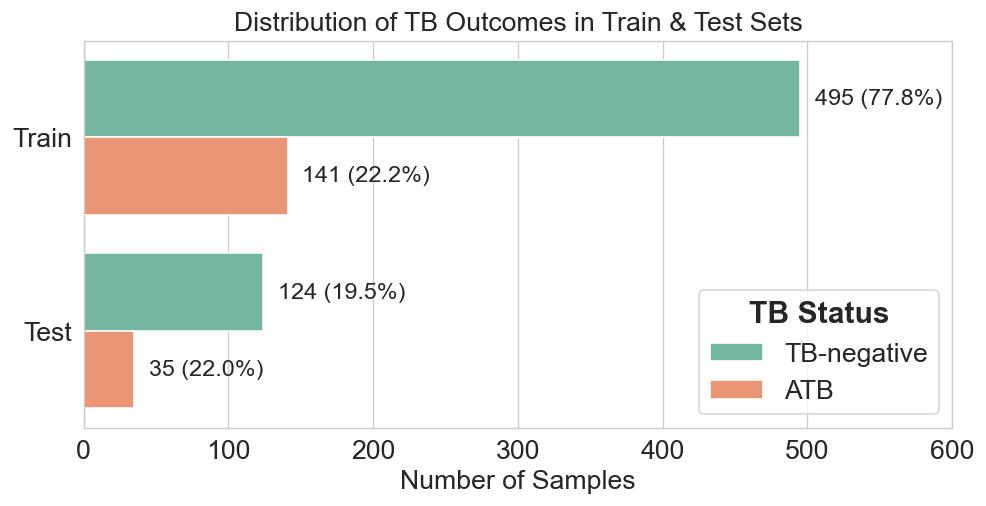

In [20]:
# =========================================
#Supplementary Figure 1
# =========================================

#Distribution of train and test sets
from matplotlib.font_manager import FontProperties

# Combine train and test sets
train_labels = pd.DataFrame({"Set": "Train", "Outcome": target_train})
test_labels = pd.DataFrame({"Set": "Test", "Outcome": target_test})
combined = pd.concat([train_labels, test_labels])

# Convert outcomes to categorical labels
label_map = {0: "TB-negative", 1: "ATB"}
combined["Outcome"] = combined["Outcome"].map(label_map)

# Plot as horizontal bar chart
plt.figure(figsize=(8.5, 4.5))
ax = sns.countplot(data=combined, y="Set", hue="Outcome", palette="Set2", orient='h')

# Get counts per group
group_totals = combined.groupby("Set").size().to_dict()

# Annotate bars
for p in ax.patches:
    width = int(p.get_width())
    if width == 0:
        continue  # Skip zero-width bars

    y = p.get_y() + p.get_height() / 2
    set_label = ax.get_yticklabels()[int(y)].get_text()
    total = group_totals[set_label]
    pct = width / total * 100

    ax.annotate(f"{width} ({pct:.1f}%)", 
                (width + 10, y),  # Add more horizontal padding
                va='center',
                fontsize=14)

# Styling
plt.title("Distribution of TB Outcomes in Train & Test Sets", fontsize=16)
plt.xlabel("Number of Samples", fontsize=16)
plt.ylabel("")
plt.xlim(0, 600)  # Extend x-axis to avoid cutoff
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

# Bigger, clearer legend
plt.legend(
    title="TB Status", 
    title_fontproperties=FontProperties(weight='bold', size=18),
    fontsize=16)

plt.tight_layout()

# Save image
output_image_path = "/Users/hbattey/Desktop/Rodwell/Output/Images/train_test_distribution_horizontal.png"
plt.savefig(output_image_path, dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
# =============== 16) SENSITIVITY: BACTERIOLOGICALLY CONFIRMED TB ONLY ===============
# Define a stricter TB outcome using only bacteriologically confirmed cases from TB_status_detailed.

# Work on a copy so the original analysis variables remain unchanged.
df_bac = df0.copy()

df_bac["TB_status_bac_only"] = np.where(
    df_bac["TB_status_detailed"] == "ATB-bacteriologically confirmed",
    1,
    0,
)

print("Bacteriologically-confirmed TB label counts:")
print(df_bac["TB_status_bac_only"].value_counts(dropna=False))
print("Original TB_status counts:")
if df_bac["TB_status"].dtype == object:
    tb_num = df_bac["TB_status"].map({"atb": 1, "non_atb": 0}).astype(int)
else:
    tb_num = df_bac["TB_status"].astype(int)
print(tb_num.value_counts(dropna=False))
print("Breakdown of TB_status_detailed:")
print(df_bac["TB_status_detailed"].value_counts(dropna=False))
print("Bacteriologically-confirmed positives among original TB-positive:",
      int(((tb_num == 1) & (df_bac["TB_status_detailed"] == "ATB-bacteriologically confirmed")).sum()))

# Build the feature matrix for the bacteriologically-confirmed outcome.
drop_cols_bac = [
    "record_id", "TB_status", "TB_status_detailed", "TB_status_bac_only",
    "TB_status_including_clinician", "TB_status_clinician_only",
]
X_bac = df_bac.drop(columns=drop_cols_bac)
y_bac = df_bac["TB_status_bac_only"].astype(int)

cat_cols_bac = X_bac.select_dtypes(include=["object", "bool", "category"]).columns.tolist()
feature_train_bac, feature_test_bac, target_train_bac, target_test_bac = train_test_split(
    X_bac,
    y_bac,
    test_size=0.20,
    random_state=split_seed,
    stratify=y_bac,
)

print(f"Bacteriologically-confirmed train n={len(feature_train_bac)} | test n={len(feature_test_bac)} | pos rate={target_train_bac.mean():.3f}")

# Align categories if needed; this keeps the same feature ordering scheme as the original analysis.
feature_train_bac = align_categoricals(feature_train_bac)
feature_test_bac = align_categoricals(feature_test_bac)
feature_test_bac = feature_test_bac.reindex(columns=feature_train_bac.columns)

# =============== 17) RERUN STAGE-BASED MODEL SELECTION AND FITS FOR BACTERIOLOGICALLY-CONFIRMED ONLY ===============
from collections import OrderedDict

X_train_full_bac = feature_train_bac.copy()
y_train_full_bac = target_train_bac.astype(int).copy()
X_test_full_bac  = feature_test_bac.copy()
y_test_full_bac  = target_test_bac.astype(int).copy()

# Retrain the stage-wise selection pipeline with the bacteriologically-confirmed outcome.
print("Starting stage-wise feature selection for bacteriologically-confirmed outcome. This may take some time.")
xgb_selected_bac, xgb_rankings_bac = carry_forward_rfe(
    "XGB", X_train_full_bac, y_train_full_bac, stage_new, stage_K,
    verbose=False, log_path=f"{CSV_DIR}/rfe_flow_XGB_bacteriologically_confirmed.csv"
)
cat_selected_bac, cat_rankings_bac = carry_forward_rfe(
    "CAT", X_train_full_bac, y_train_full_bac, stage_new, stage_K,
    verbose=False, log_path=f"{CSV_DIR}/rfe_flow_CatBoost_bacteriologically_confirmed.csv"
)

print("Fitting final stage models for bacteriologically-confirmed outcome.")
def fit_final_xgb_for_bac(feats):
    Xt = align_categoricals(X_train_full_bac[feats])
    (params, rounds), _ = tune_xgb_params_auc(X_train_full_bac, y_train_full_bac, feats, RANDOM_STATE+123)
    params = dict(params); params.setdefault("verbosity", 0)
    booster = xgb_train(params, DMatrix(Xt, label=y_train_full_bac, enable_categorical=True),
                        num_boost_round=rounds, verbose_eval=False)
    return booster

def fit_final_cat_for_bac(feats):
    Xt = align_categoricals(X_train_full_bac[feats])
    params, _ = tune_cat_params_auc(X_train_full_bac, y_train_full_bac, feats, RANDOM_STATE+123)
    params = _clean_cat_verbose(params)
    cat_idx = [Xt.columns.get_loc(c) for c in CATS if c in Xt.columns]
    model = CatBoostClassifier(**params)
    model.fit(Pool(Xt, y_train_full_bac, cat_features=cat_idx if len(cat_idx) else None))
    return model

final_models_xgb_bac = OrderedDict((st, {"model": fit_final_xgb_for_bac(feats), "feats": feats})
                                   for st, feats in xgb_selected_bac.items())
final_models_cat_bac = OrderedDict((st, {"model": fit_final_cat_for_bac(feats), "feats": feats})
                                   for st, feats in cat_selected_bac.items())

print("Final XGB/CAT models fitted for bacteriologically-confirmed outcome.")

# =============== 18) EVALUATE BACTERIOLOGICALLY-CONFIRMED MODELS AND SAVE TABLES/FIGURES ===============
rows_cat_bac, rows_xgb_bac = [], []
for st in stage_new.keys():
    feats_cat = cat_selected_bac[st]
    feats_xgb = xgb_selected_bac[st]
    
    def eval_stage_cat_bac(feats, seed=RANDOM_STATE):
        Xt = align_categoricals(X_train_full_bac[feats])
        cat_idx = [Xt.columns.get_loc(c) for c in CATS if c in Xt.columns]
        (params, _), _ = tune_cat_params_auc(X_train_full_bac, y_train_full_bac, feats, seed)
        params = _clean_cat_verbose(params)
        model = CatBoostClassifier(**params)
        model.fit(Pool(Xt, y_train_full_bac, cat_features=cat_idx if len(cat_idx) else None))
        Xts = align_categoricals(X_test_full_bac[feats])
        y_pred_p = model.predict_proba(Pool(Xts, cat_features=cat_idx if len(cat_idx) else None))[:, 1]
        return {k: v for k, v in zip(["AUC", "Sens", "Spec", "AP", "Acc"], 
                                     compute_metrics(y_test_full_bac, y_pred_p, THRESHOLD))}
    
    def eval_stage_xgb_bac(feats, seed=RANDOM_STATE):
        Xt = align_categoricals(X_train_full_bac[feats])
        (params, rounds), _ = tune_xgb_params_auc(X_train_full_bac, y_train_full_bac, feats, seed)
        params = dict(params); params.setdefault("verbosity", 0)
        booster = xgb_train(params, DMatrix(Xt, label=y_train_full_bac, enable_categorical=True),
                           num_boost_round=rounds, verbose_eval=False)
        Xts = align_categoricals(X_test_full_bac[feats])
        y_pred_p = booster.predict(DMatrix(Xts, enable_categorical=True))
        return {k: v for k, v in zip(["AUC", "Sens", "Spec", "AP", "Acc"],
                                     compute_metrics(y_test_full_bac, y_pred_p, THRESHOLD))}
    
    rows_cat_bac.append(dict(Model=st, **{k: float(v) for k,v in eval_stage_cat_bac(feats_cat).items()}))
    rows_xgb_bac.append(dict(Model=st, **{k: float(v) for k,v in eval_stage_xgb_bac(feats_xgb).items()}))

tbl_cat_bac = pd.DataFrame(rows_cat_bac).set_index("Model")
tbl_xgb_bac = pd.DataFrame(rows_xgb_bac).set_index("Model")

print("\n=== Metrics — CatBoost (Bacteriologically-confirmed outcome, Test) ===")
print(tbl_cat_bac.round(3))
print("\n=== Metrics — XGBoost (Bacteriologically-confirmed outcome, Test) ===")
print(tbl_xgb_bac.round(3))

os.makedirs(CSV_DIR, exist_ok=True)
tbl_cat_bac.to_csv(f"{CSV_DIR}/fig3_metrics_catboost_by_stage_bacteriologically_confirmed.csv")
tbl_xgb_bac.to_csv(f"{CSV_DIR}/fig3_metrics_xgboost_by_stage_bacteriologically_confirmed.csv")
print("Saved bacteriologically-confirmed metrics CSVs.")

# PR/ROC for bacteriologically-confirmed stage models
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve, average_precision_score, roc_auc_score

def _proba_xgb_bac(bundle, X):
    feats = [f for f in bundle["feats"] if f in X.columns]
    Xs = align_categoricals(X[feats])
    d = DMatrix(Xs, enable_categorical=True)
    return bundle["model"].predict(d)

def _proba_cat_bac(bundle, X):
    feats = [f for f in bundle["feats"] if f in X.columns]
    Xs = align_categoricals(X[feats])
    cat_idx = [Xs.columns.get_loc(c) for c in CATS if c in Xs.columns]
    pool = Pool(Xs, cat_features=cat_idx if len(cat_idx) else None)
    return bundle["model"].predict_proba(pool)[:, 1]

fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.0), sharex=False, sharey=False)
(ax_pr_xgb, ax_roc_xgb), (ax_pr_cat, ax_roc_cat) = axes

for i, st in enumerate(stage_new.keys()):
    p_x = _proba_xgb_bac(final_models_xgb_bac[st], X_test_full_bac)
    p_c = _proba_cat_bac(final_models_cat_bac[st], X_test_full_bac)

    prec_x, rec_x, _ = precision_recall_curve(y_test_full_bac, p_x)
    ap_x = average_precision_score(y_test_full_bac, p_x)
    ax_pr_xgb.plot(rec_x, prec_x, lw=2, label=f"{st} (AP={ap_x:.3f})")
    fpr_x, tpr_x, _ = roc_curve(y_test_full_bac, p_x)
    auc_x = roc_auc_score(y_test_full_bac, p_x)
    ax_roc_xgb.plot(fpr_x, tpr_x, lw=2, label=f"{st} (AUC={auc_x:.3f})")

    prec_c, rec_c, _ = precision_recall_curve(y_test_full_bac, p_c)
    ap_c = average_precision_score(y_test_full_bac, p_c)
    ax_pr_cat.plot(rec_c, prec_c, lw=2, label=f"{st} (AP={ap_c:.3f})")
    fpr_c, tpr_c, _ = roc_curve(y_test_full_bac, p_c)
    auc_c = roc_auc_score(y_test_full_bac, p_c)
    ax_roc_cat.plot(fpr_c, tpr_c, lw=2, label=f"{st} (AUC={auc_c:.3f})")

for ax, title in [(ax_pr_xgb, "XGBoost — Precision–Recall"), (ax_roc_xgb, "XGBoost — ROC"),
                  (ax_pr_cat, "CatBoost — Precision–Recall"), (ax_roc_cat, "CatBoost — ROC")]:
    ax.set_title(title)
    ax.grid(True, linewidth=0.5, alpha=0.6)
    ax.legend(frameon=False, fontsize=9)

ax_pr_xgb.set_xlabel("Recall"); ax_pr_xgb.set_ylabel("Precision")
ax_roc_xgb.set_xlabel("False Positive Rate"); ax_roc_xgb.set_ylabel("True Positive Rate")
ax_pr_cat.set_xlabel("Recall"); ax_pr_cat.set_ylabel("Precision")
ax_roc_cat.set_xlabel("False Positive Rate"); ax_roc_cat.set_ylabel("True Positive Rate")

plt.tight_layout()
out_path = f"{IMG_DIR}/fig_staged_PR_left_ROC_right_xgb_cat_bacteriologically_confirmed.png"
plt.savefig(out_path, dpi=200, bbox_inches="tight"); plt.show()
print("Saved bacteriologically-confirmed PR/ROC figure:", out_path)
